# 07 — M1.1 scientific validation (Studies A, B, C)

**Status: authored, NOT executed.** Every number shown here comes from saved outputs after the user runs the CLI. Plan: `docs/M1_1_RESEARCH_PLAN.md`.

| | Study A — data quality & measurement validity |
|---|---|
| **A. Questions** | A1: do tiers / continuous quality dimensions separate reliable from unreliable trajectories? A2: where and how much does derived speed disagree with vendor speed? |
| **B. Motivation** | Every athlete feature (sprint, braking, COD) inherits the measurement error of the frame kinematics. |
| **C. Population** | All Combine attempts (6,310 per M1) and NFL player-plays (314,944 per M1); A2 NFL = deterministic game sample. |
| **D. Grain** | trajectory (A1), frame (A2 statistics), athlete (bootstrap unit). |
| **E. Quality filters** | none — quality *is* the outcome; filter scenarios are compared in the funnel. |
| **F. Methods** | `nflbdb.research.studies.quality` docstring (formulas, thresholds, provenance in `studies_thresholds.csv`). |

Heavy computation runs in the CLI, not in this notebook:
```
python -m nflbdb.research.studies --only A --sample-athletes 300 --skip-nfl-sample   # smoke (→ phase_03/_sample)
python -m nflbdb.research.studies --only A                                           # full
python -m nflbdb.research.studies --check
```

In [7]:
# Setup — configure_runtime BEFORE heavy polars work
from nflbdb.data.config import Phase01Config, configure_runtime
cfg = Phase01Config.load(); configure_runtime(cfg)

import polars as pl
from IPython.display import Image, display
from nflbdb.research.studies.config import StudiesConfig
from nflbdb.research.studies.store import StudyStore
from nflbdb.research.studies import quality as Q

SAMPLED = False          # True → read the smoke-run outputs under phase_03/_sample
store = StudyStore(cfg, sampled=SAMPLED)
status = {c.name: all(p.is_file() for p in store.paths(c)) for c in Q.CONTRACTS}
pl.DataFrame({'table': list(status), 'present': list(status.values())})

table,present
str,bool
"""trajectory_quality_dimensions""",true
"""A1_proportions""",true
"""A1_metric_by_tier""",true
"""A1_reason_matrix""",true
"""A1_filter_funnel""",true
…,…
"""trajectory_frame_diagnostics""",true
"""A2_hist2d""",true
"""A2_residual_by_speed""",true


In [8]:
# Optional: compute from the notebook (reuses current results; set FORCE=True to recompute)
RUN, FORCE = False, False
if RUN:
    Q.QualityStudy(cfg, StudiesConfig(), store).run(force=FORCE, figures=True)
A = {c.name: store.read(c) for c in Q.CONTRACTS if status.get(c.name) or RUN}
{k: v.height for k, v in A.items()}

{'trajectory_quality_dimensions': 321254,
 'A1_proportions': 533,
 'A1_metric_by_tier': 37,
 'A1_reason_matrix': 49,
 'A1_filter_funnel': 48,
 'A1_screen_thresholds': 69,
 'A1_extreme_accel_by_tier': 5,
 'A1_examples': 4,
 'A1_example_signals': 186,
 'A2_vendor_error_summary': 45,
 'trajectory_frame_diagnostics': 13776,
 'A2_hist2d': 10536,
 'A2_residual_by_speed': 91,
 'A2_example_signals': 311,
 'A_quality_results': 181}

## G. Descriptive analysis — A1 quality tiers and dimensions

In [9]:
if A:
    p = A['A1_proportions']
    display(p.filter(pl.col('facet').is_in(['all', 'cohort']) & pl.col('indicator').is_in(['tier_A', 'any_flag']))
             .select('domain', 'facet', 'level', 'indicator', 'n_trajectories', 'n_athletes', 'share', 'boot_lower', 'boot_upper'))
    display(A['A1_filter_funnel'].filter(pl.col('stratum') == 'all'))
    display(A['A1_reason_matrix'].sort('share', descending=True).head(20))
    display(A['A1_screen_thresholds'].filter(pl.col('share_zero') > 0.9))   # degenerate dimensions

domain,facet,level,indicator,n_trajectories,n_athletes,share,boot_lower,boot_upper
str,str,str,str,i64,i64,f64,f64,f64
"""combine""","""all""","""all""","""tier_A""",6310,510,0.999842,0.999524,1.0
"""combine""","""all""","""all""","""any_flag""",6310,510,0.041046,0.035849,0.046908
"""nfl""","""all""","""all""","""tier_A""",314944,497,0.990602,0.988796,0.992054
"""nfl""","""all""","""all""","""any_flag""",314944,497,0.024652,0.022477,0.027247
"""combine""","""cohort""","""2024""","""tier_A""",2171,177,1.0,1.0,1.0
…,…,…,…,…,…,…,…,…
"""nfl""","""cohort""","""2023""","""any_flag""",50911,156,0.018601,0.0151,0.022257
"""nfl""","""cohort""","""2024""","""tier_A""",108720,318,0.990811,0.988829,0.992369
"""nfl""","""cohort""","""2024""","""any_flag""",108720,318,0.02351,0.021104,0.026052


domain,stratum,scenario,scenario_order,n_trajectories,n_athletes,share_trajectories_retained,share_athletes_retained
str,str,str,i64,i64,i64,f64,f64
"""combine""","""all""","""all trajectories""",0,6310,510,1.0,1.0
"""combine""","""all""","""exclude reject""",1,6310,510,1.0,1.0
"""combine""","""all""","""tier A only""",2,6309,510,0.999842,1.0
"""combine""","""all""","""tier A + no screening flag""",3,6051,510,0.958954,1.0
"""nfl""","""all""","""all trajectories""",0,314944,497,1.0,1.0
"""nfl""","""all""","""exclude reject""",1,314638,497,0.999028,1.0
"""nfl""","""all""","""tier A only""",2,311984,497,0.990602,1.0
"""nfl""","""all""","""tier A + no screening flag""",3,307180,497,0.975348,1.0


domain,stratum,reason,source,n_trajectories,n_stratum,share
str,str,str,str,i64,i64,f64
"""combine""","""SKILL_DRILLS_LB""","""flag:coordinate_validity""","""screen_flag""",1,37,0.027027
"""combine""","""SKILL_DRILLS_LB""","""flag:derivative_reliability""","""screen_flag""",1,37,0.027027
"""combine""","""SKILL_DRILLS_LB""","""flag:heading_reliability""","""screen_flag""",1,37,0.027027
"""combine""","""SKILL_DRILLS_LB""","""flag:speed_consistency""","""screen_flag""",1,37,0.027027
"""combine""","""THREE_CONE_DRILL""","""flag:coordinate_validity""","""screen_flag""",3,203,0.014778
…,…,…,…,…,…,…
"""combine""","""SKILL_DRILLS_TE""","""flag:derivative_reliability""","""screen_flag""",5,438,0.011416
"""combine""","""SKILL_DRILLS_TE""","""flag:heading_reliability""","""screen_flag""",5,438,0.011416
"""combine""","""SKILL_DRILLS_TE""","""flag:speed_consistency""","""screen_flag""",5,438,0.011416


domain,stratum,metric,quantile,threshold,n_trajectories,share_zero
str,str,str,f64,f64,i64,f64
"""combine""","""FORTY_YARD_DASH""","""event_count_rel_range""",0.99,0.666667,793,0.934426
"""combine""","""FORTY_YARD_DASH""","""offgrid_rate""",0.99,0.0,793,1.0
"""combine""","""FORTY_YARD_DASH""","""structural_breaks""",0.99,0.0,793,1.0
"""combine""","""SHORT_SHUTTLE""","""offgrid_rate""",0.99,0.0,223,1.0
"""combine""","""SHORT_SHUTTLE""","""structural_breaks""",0.99,0.0,223,1.0
…,…,…,…,…,…,…
"""combine""","""SKILL_DRILLS_WR""","""structural_breaks""",0.99,0.0,1529,1.0
"""combine""","""THREE_CONE_DRILL""","""offgrid_rate""",0.99,0.0,203,1.0
"""combine""","""THREE_CONE_DRILL""","""structural_breaks""",0.99,0.0,203,1.0


## G. Descriptive analysis — A2 vendor vs derived speed

In [10]:
if A:
    v = A['A2_vendor_error_summary']
    display(v.filter(pl.col('facet').is_in(['all', 'speed_band', 'stratum']))
             .select('domain', 'facet', 'level', 'n_frames', 'n_athletes', 'mae', 'mae_lower', 'mae_upper', 'bias',
                     'loa_lower', 'loa_upper', 'p95_abs', 'rel_mae'))

domain,facet,level,n_frames,n_athletes,mae,mae_lower,mae_upper,bias,loa_lower,loa_upper,p95_abs,rel_mae
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""combine""","""all""","""all""",431094,510,0.050277,0.049294,0.051275,0.001122,-0.159486,0.16173,0.162836,0.015884
"""nfl_sample""","""all""","""all""",543964,173,0.088449,0.082157,0.094434,0.035145,-0.213614,0.283904,0.269126,0.037105
"""combine""","""stratum""","""FORTY_YARD_DASH""",41500,418,0.031861,0.030756,0.033035,0.003387,-0.116807,0.123581,0.104023,0.007386
"""combine""","""stratum""","""SKILL_DRILLS_DL""",77428,114,0.054144,0.053014,0.055363,-0.001907,-0.167108,0.163295,0.16101,0.018297
"""combine""","""stratum""","""THREE_CONE_DRILL""",15951,160,0.120395,0.116691,0.124015,0.009687,-0.328604,0.347978,0.364915,0.053574
…,…,…,…,…,…,…,…,…,…,…,…,…
"""nfl_sample""","""speed_band""","""[1, 3)""",205298,172,0.092137,0.086818,0.098013,0.036427,-0.215807,0.288661,0.264494,0.050463
"""nfl_sample""","""speed_band""","""[3, 5)""",115320,172,0.101702,0.092252,0.112075,0.031391,-0.249098,0.311881,0.297084,0.027134
"""nfl_sample""","""speed_band""","""[5, 7)""",51724,169,0.085933,0.076739,0.098278,0.010752,-0.252261,0.273766,0.303084,0.015105


## H. Statistical evidence (effect sizes + athlete-cluster CIs)

In [11]:
if A:
    r = A['A_quality_results']
    display(r.filter(pl.col('analysis_id').is_in(['A1.tier_contrast', 'A1.duration_association', 'A2.error_vs_duration']))
             .select('analysis_id', 'domain', 'feature', 'grain', 'n_athletes', 'n_trajectories', 'effect_size_type',
                     'effect_estimate', 'ci_lower', 'ci_upper', 'result_status', 'limitations'))

analysis_id,domain,feature,grain,n_athletes,n_trajectories,effect_size_type,effect_estimate,ci_lower,ci_upper,result_status,limitations
str,str,str,str,i64,i64,str,f64,f64,f64,str,str
"""A1.tier_contrast""","""combine""","""structural_breaks""","""trajectory""",510,6310,"""cliffs_delta_nonA_vs_A""",0.0,null,null,"""insufficient_data""","""only 1 non-A trajectories"""
"""A1.duration_association""","""combine""","""structural_breaks""","""trajectory""",510,6310,"""spearman_rho""",null,null,null,"""descriptive""","""longer trajectories have more …"
"""A1.tier_contrast""","""combine""","""offgrid_rate""","""trajectory""",510,6310,"""cliffs_delta_nonA_vs_A""",0.0,null,null,"""insufficient_data""","""only 1 non-A trajectories"""
"""A1.duration_association""","""combine""","""offgrid_rate""","""trajectory""",510,6310,"""spearman_rho""",null,null,null,"""descriptive""","""longer trajectories have more …"
"""A1.tier_contrast""","""combine""","""resid_rms_yds""","""trajectory""",510,6310,"""cliffs_delta_nonA_vs_A""",0.999683,null,null,"""insufficient_data""","""only 1 non-A trajectories"""
…,…,…,…,…,…,…,…,…,…,…,…
"""A1.tier_contrast""","""nfl""","""heading_invalid_frac""","""trajectory""",497,314944,"""cliffs_delta_nonA_vs_A""",-0.409464,-0.441425,-0.377048,"""descriptive""",""""""
"""A1.duration_association""","""nfl""","""heading_invalid_frac""","""trajectory""",497,314944,"""spearman_rho""",-0.409546,-0.418546,-0.400553,"""descriptive""","""longer trajectories have more …"
"""A1.tier_contrast""","""nfl""","""duration_s""","""trajectory""",497,314944,"""cliffs_delta_nonA_vs_A""",0.243176,0.210438,0.277761,"""descriptive""",""""""


## I. Visual evidence — figure index and gallery

figure_id,name,research_question,statistic,grain,interpretation_status
str,str,str,str,str,str
"""A1-01""","""A1_01_tier_distribution_by_dom…","""How are provisional tiers dist…","""share of trajectories per tier""","""trajectory""","""pending execution"""
"""A1-02""","""A1_02_quality_by_cohort""","""Does quality differ by draft y…","""share non-A / flagged""","""trajectory""","""pending execution"""
"""A1-03""","""A1_03_quality_by_drill""","""Which Combine drills produce l…","""share flagged / tier B""","""trajectory""","""pending execution"""
"""A1-04""","""A1_04_vendor_residual_by_tier""","""Do tiers separate vendor-speed…","""quantiles of speed_vendor_mad""","""trajectory""","""pending execution"""
"""A1-05""","""A1_05_acceleration_outliers_by…","""Do tiers separate implausible …","""max |a| quantiles; extreme-fra…","""trajectory / frame""","""pending execution"""
…,…,…,…,…,…
"""A2-06""","""A2_06_residual_by_drill""","""Which Combine drills have the …","""residual quantiles""","""frame""","""pending execution"""
"""A2-07""","""A2_07_error_vs_duration""","""Is trajectory-level error rela…","""median trajectory MAE by durat…","""trajectory""","""pending execution"""
"""A2-08""","""A2_08_bland_altman""","""What are bias and limits of ag…","""bias, 95 % LoA""","""frame""","""pending execution"""


A1_01_tier_distribution_by_domain.png


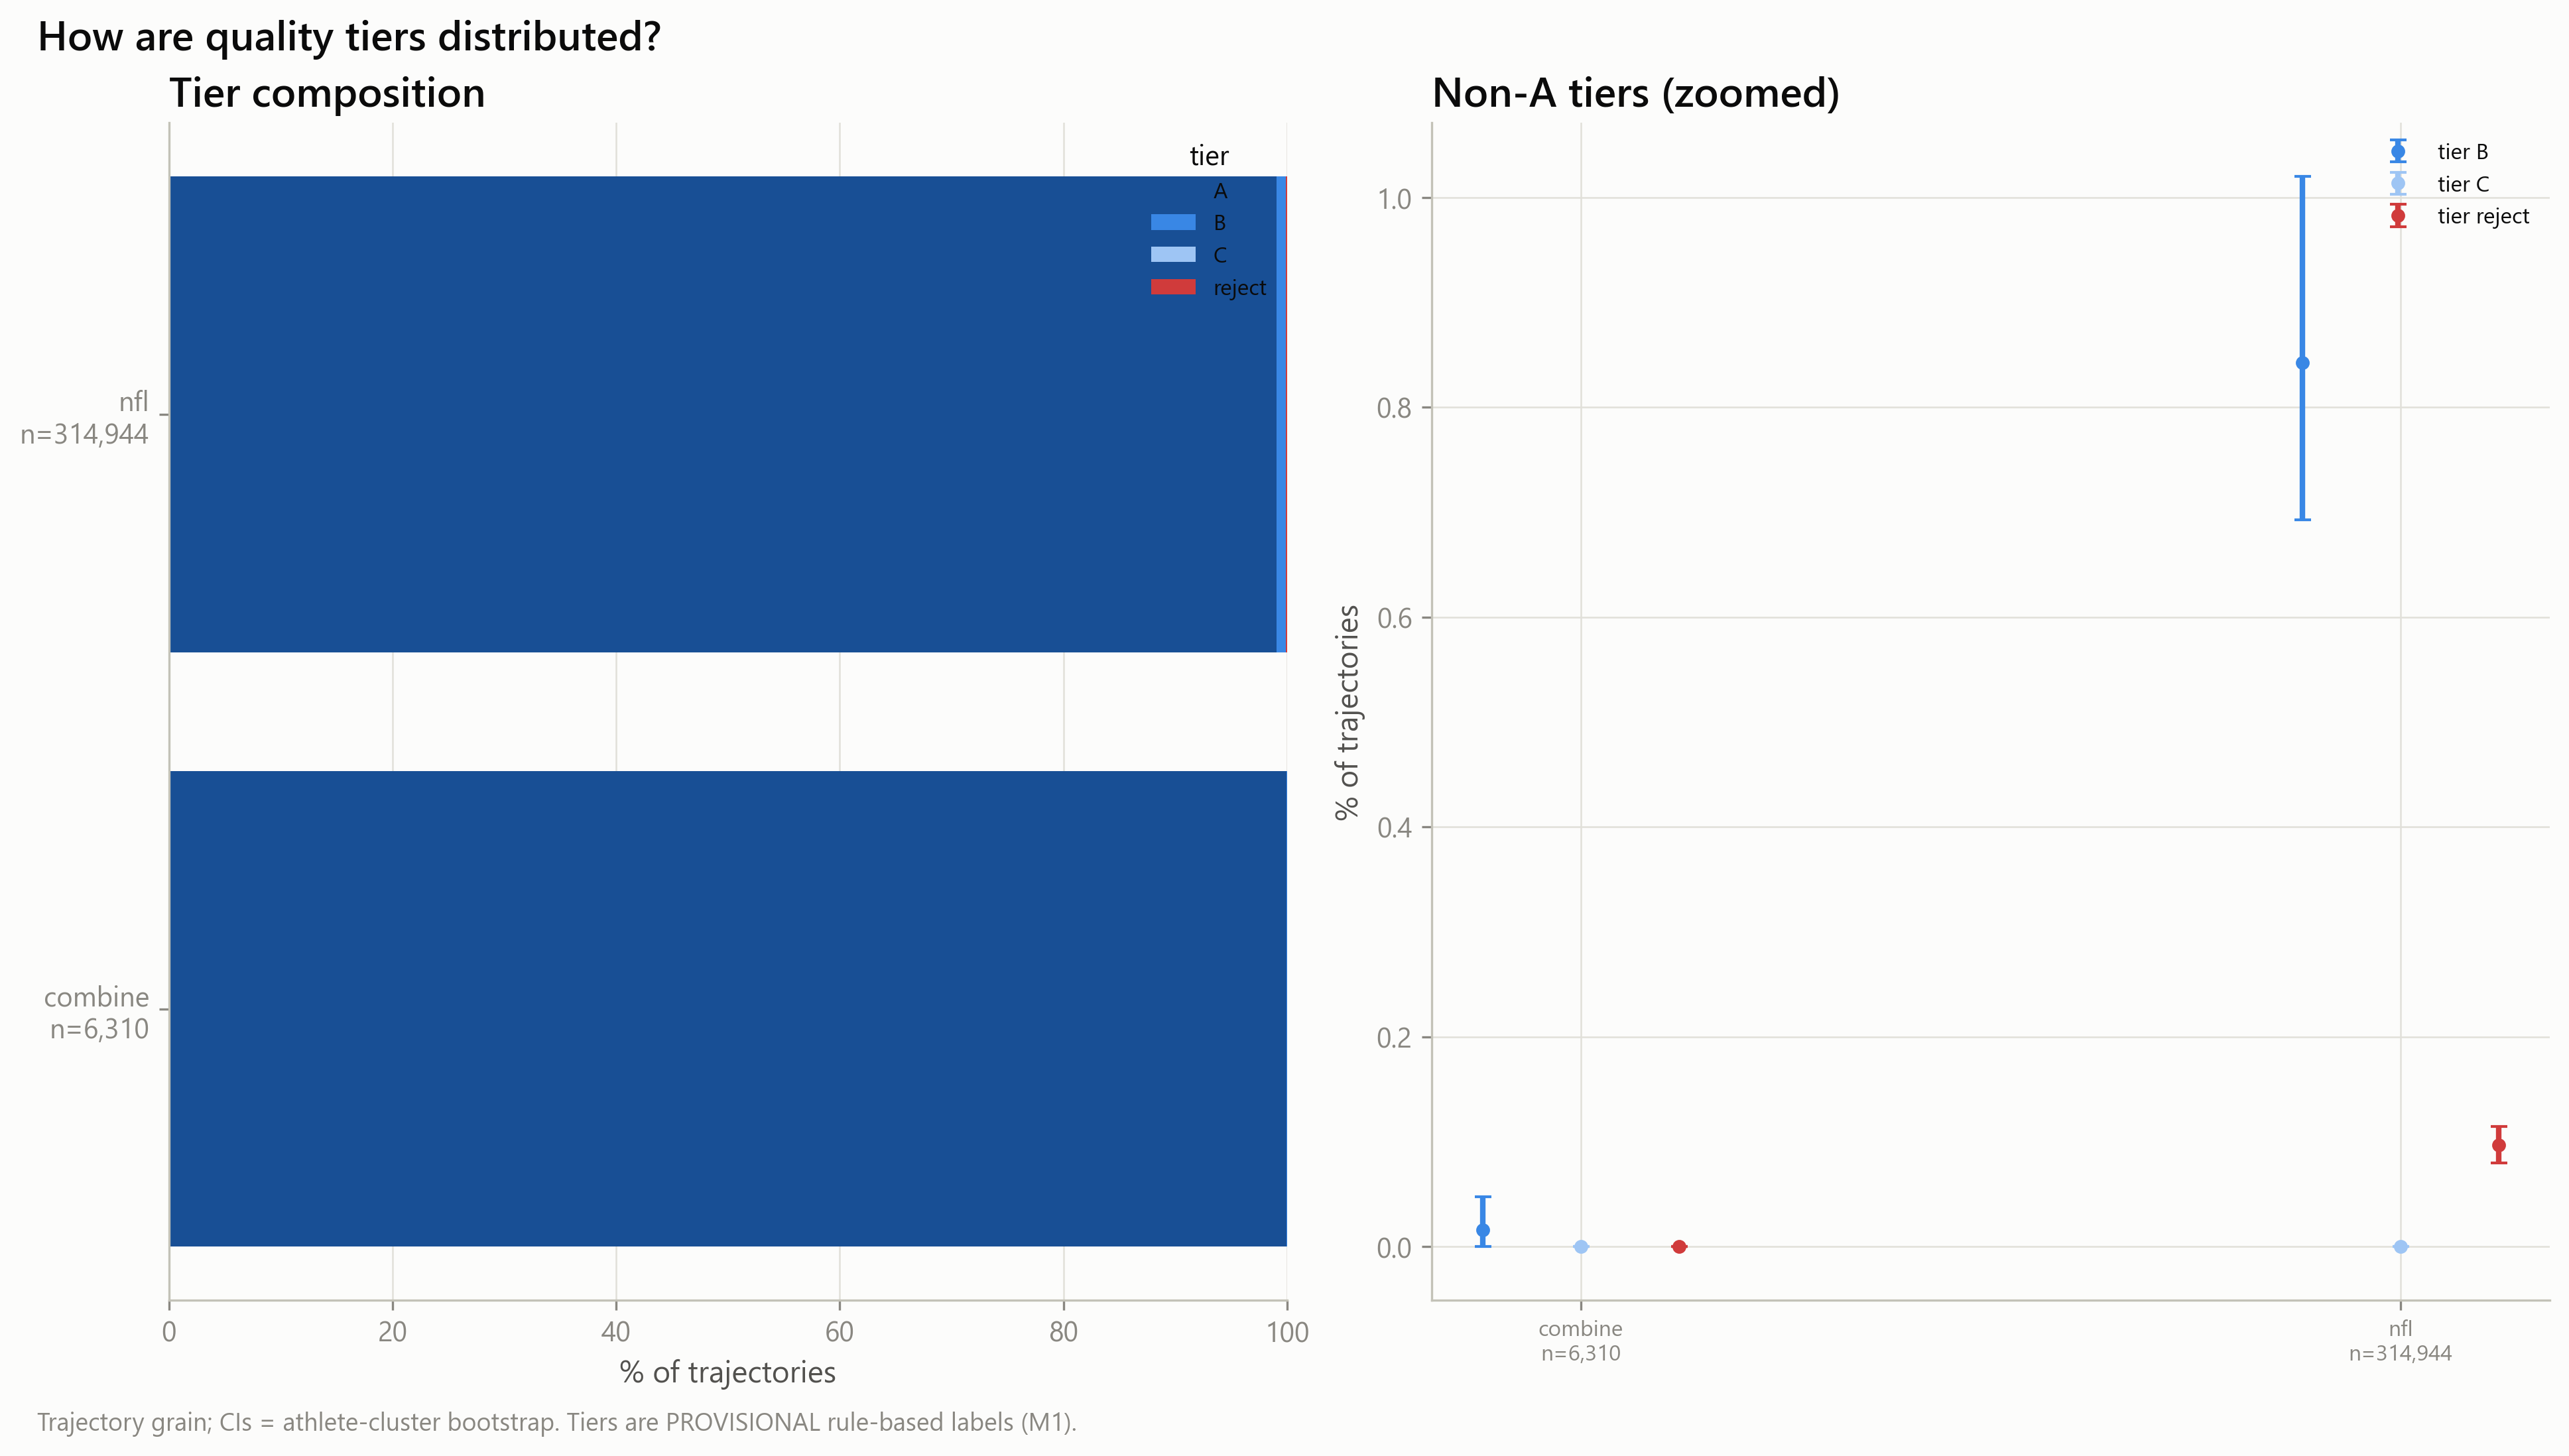

A1_02_quality_by_cohort.png


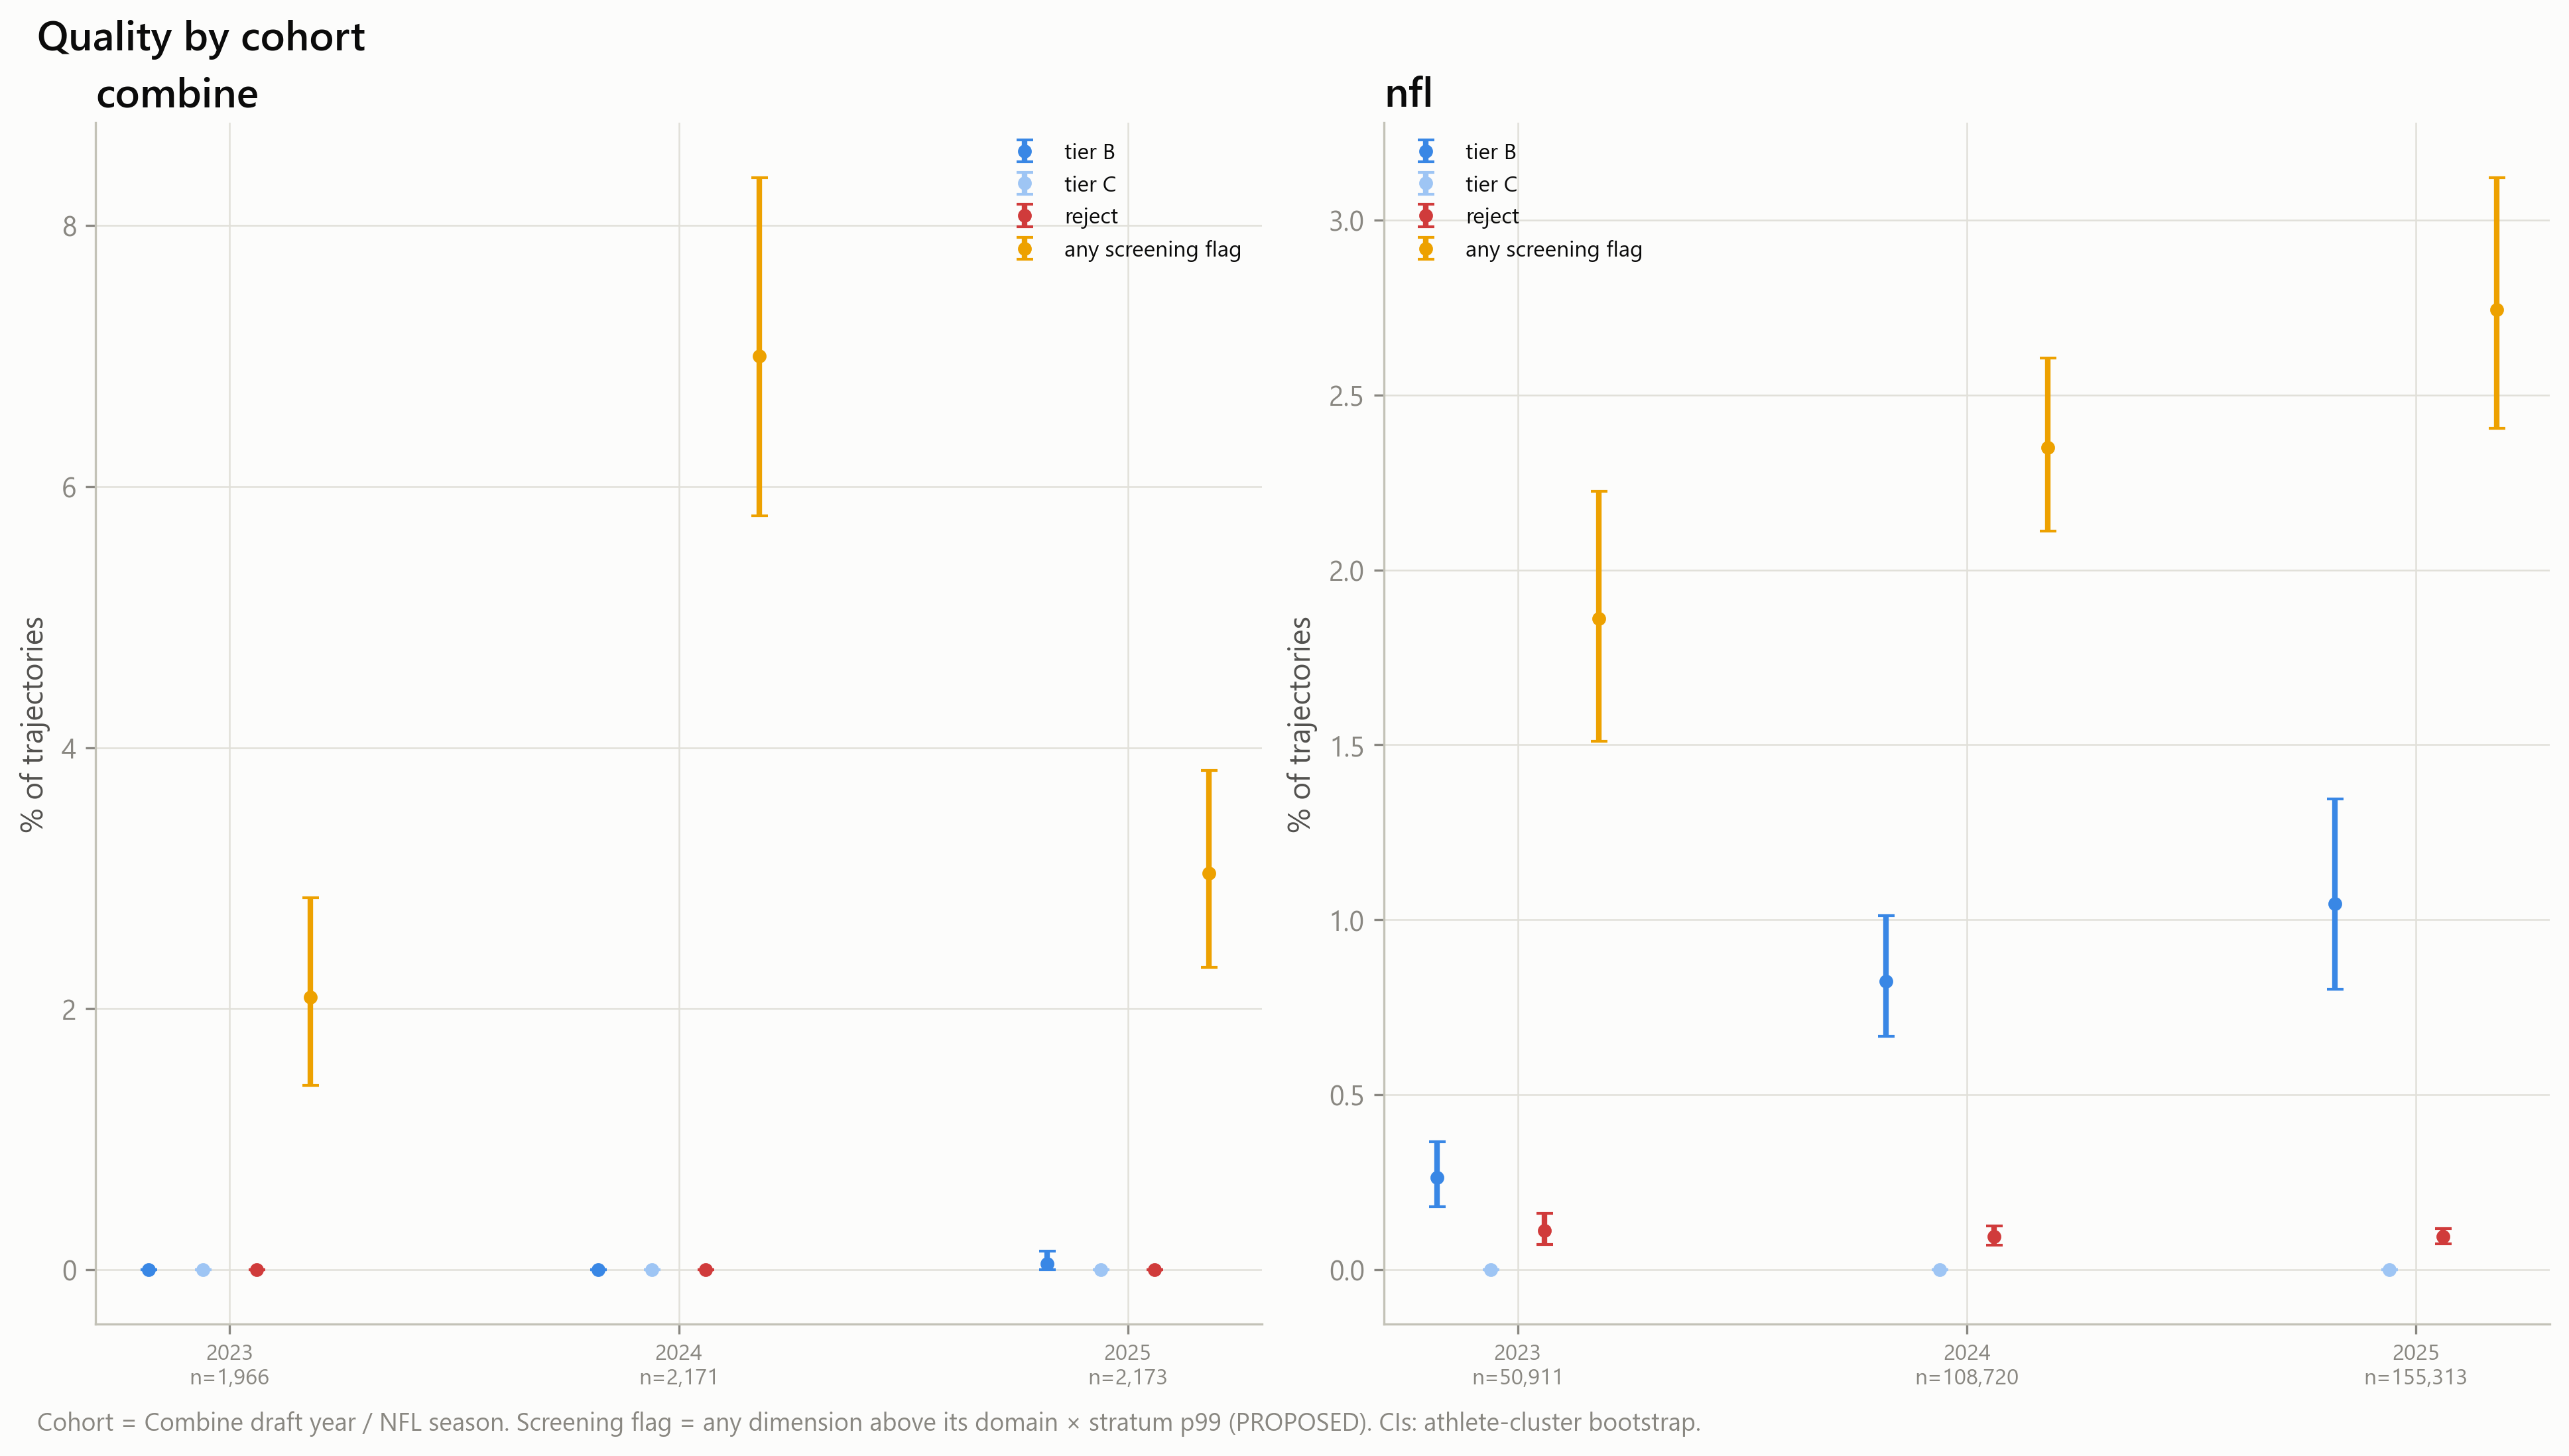

A1_03_quality_by_drill.png


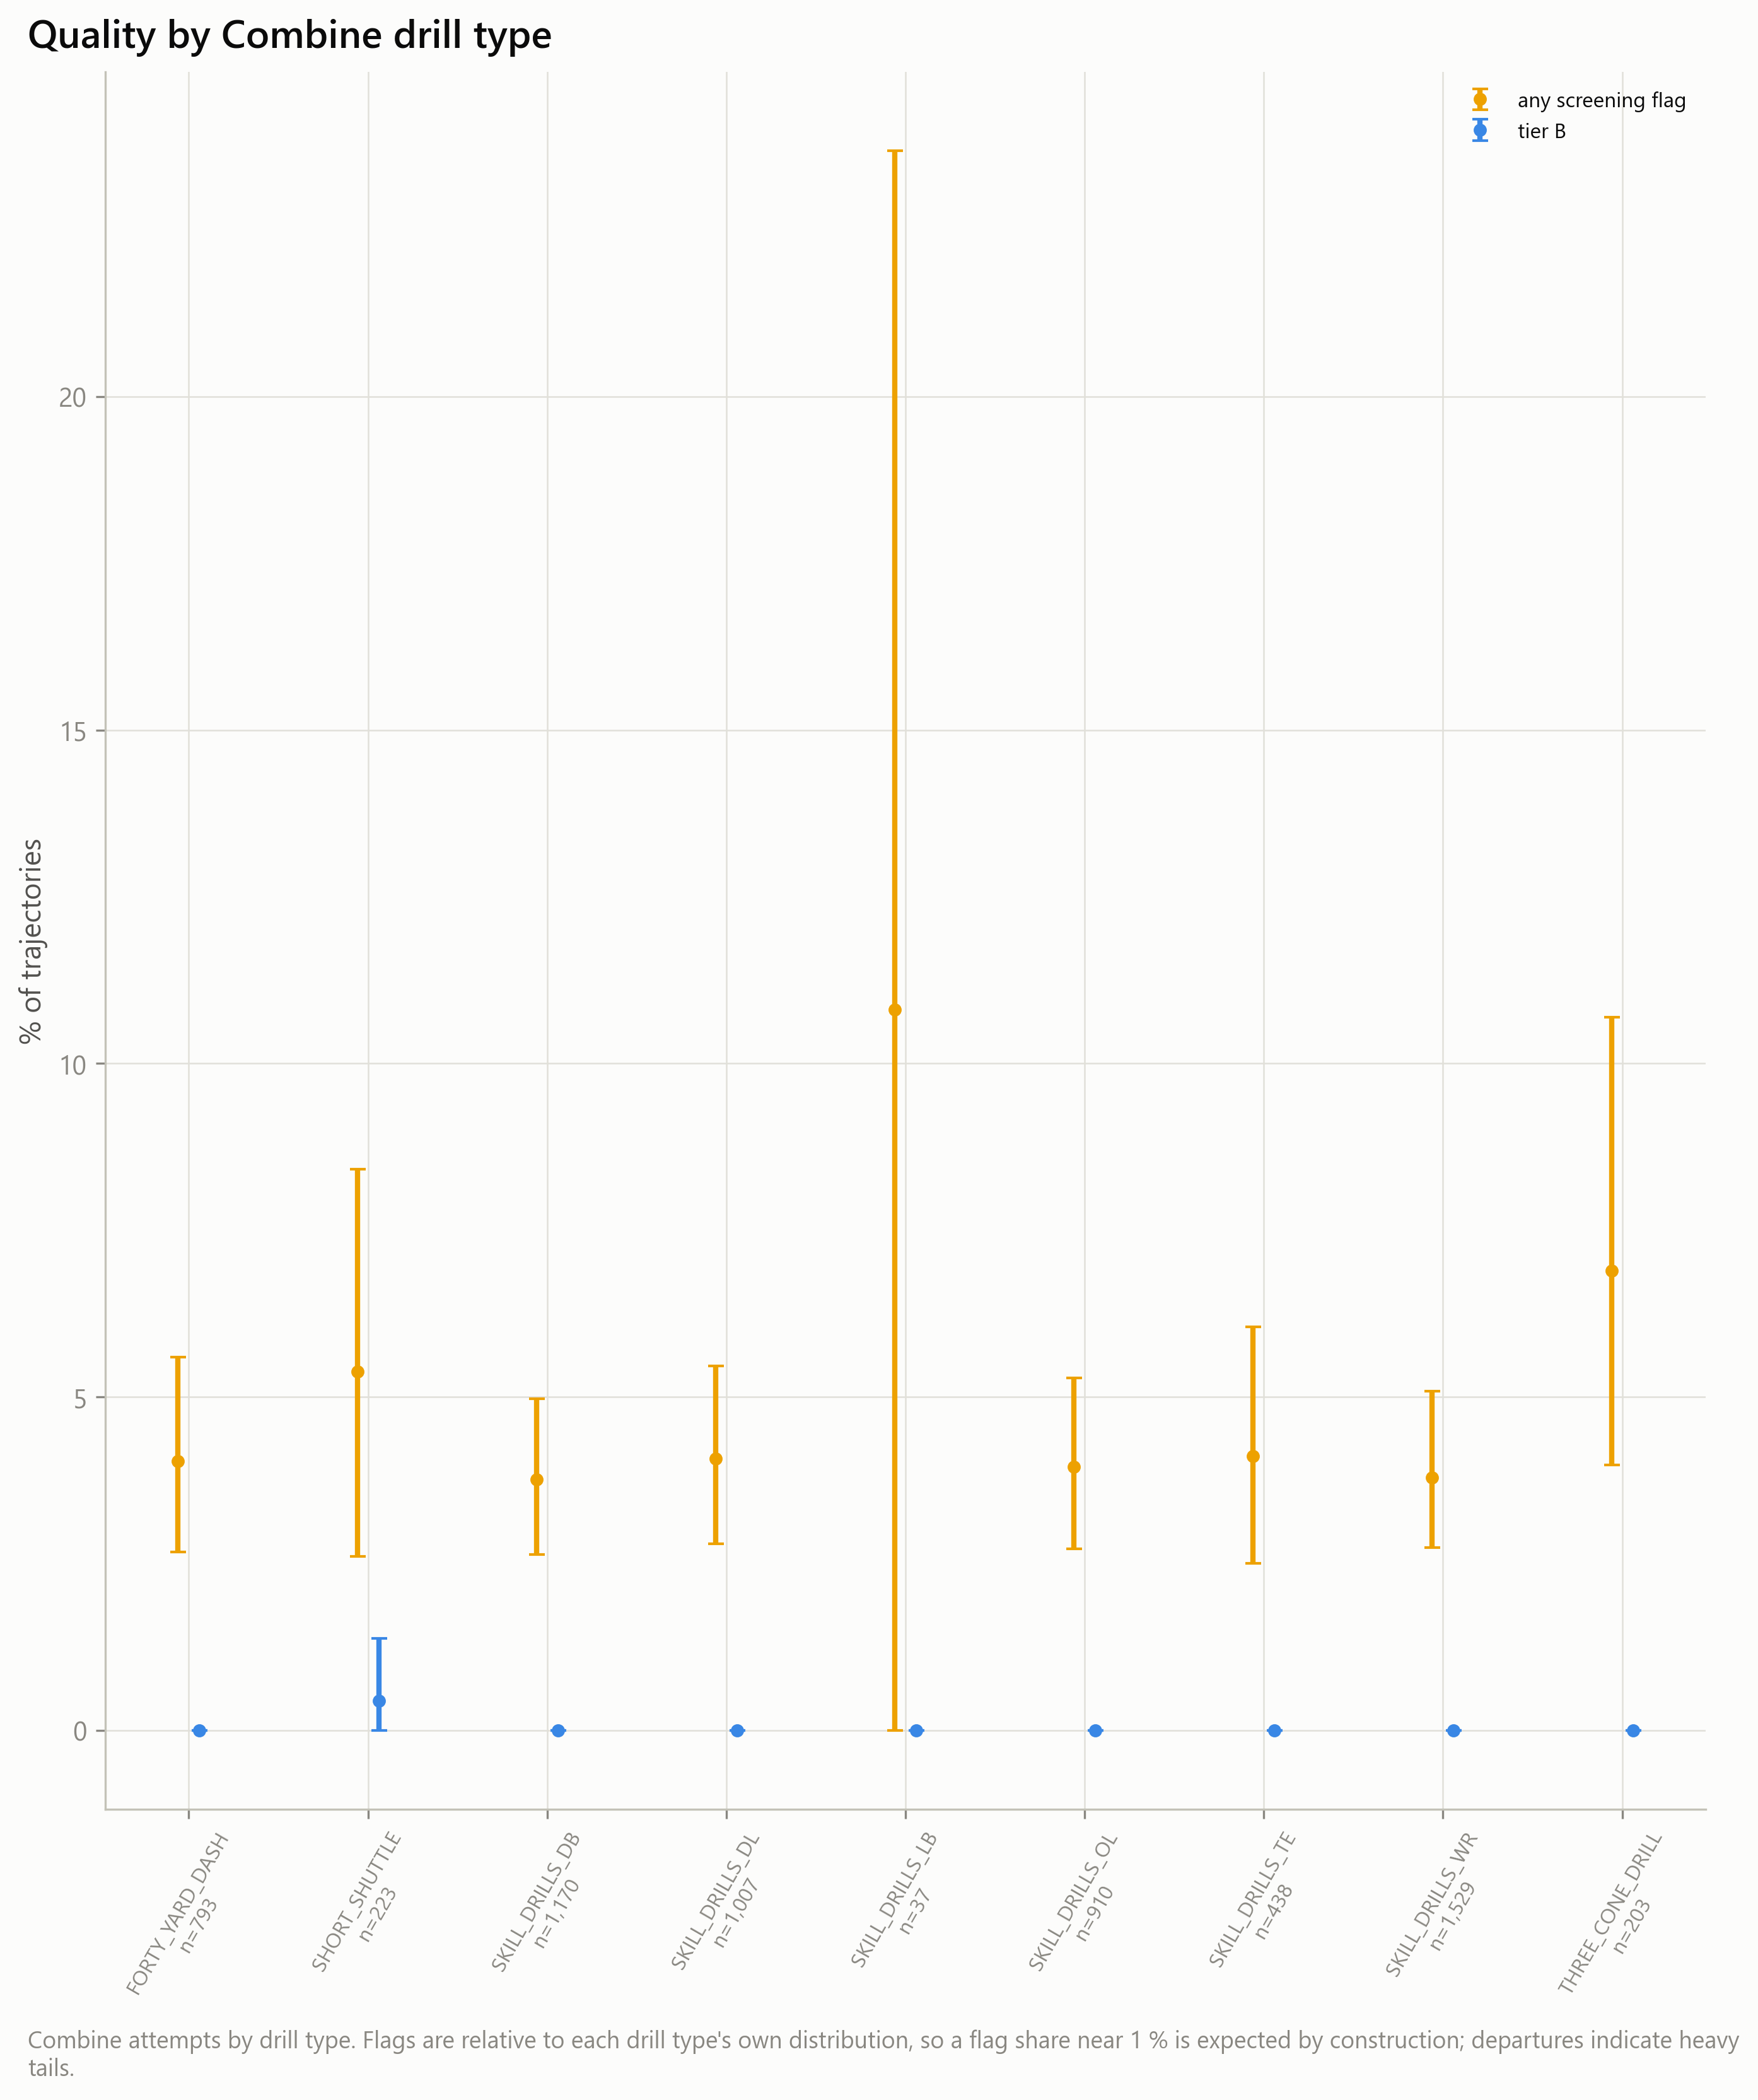

A1_04_vendor_residual_by_tier.png


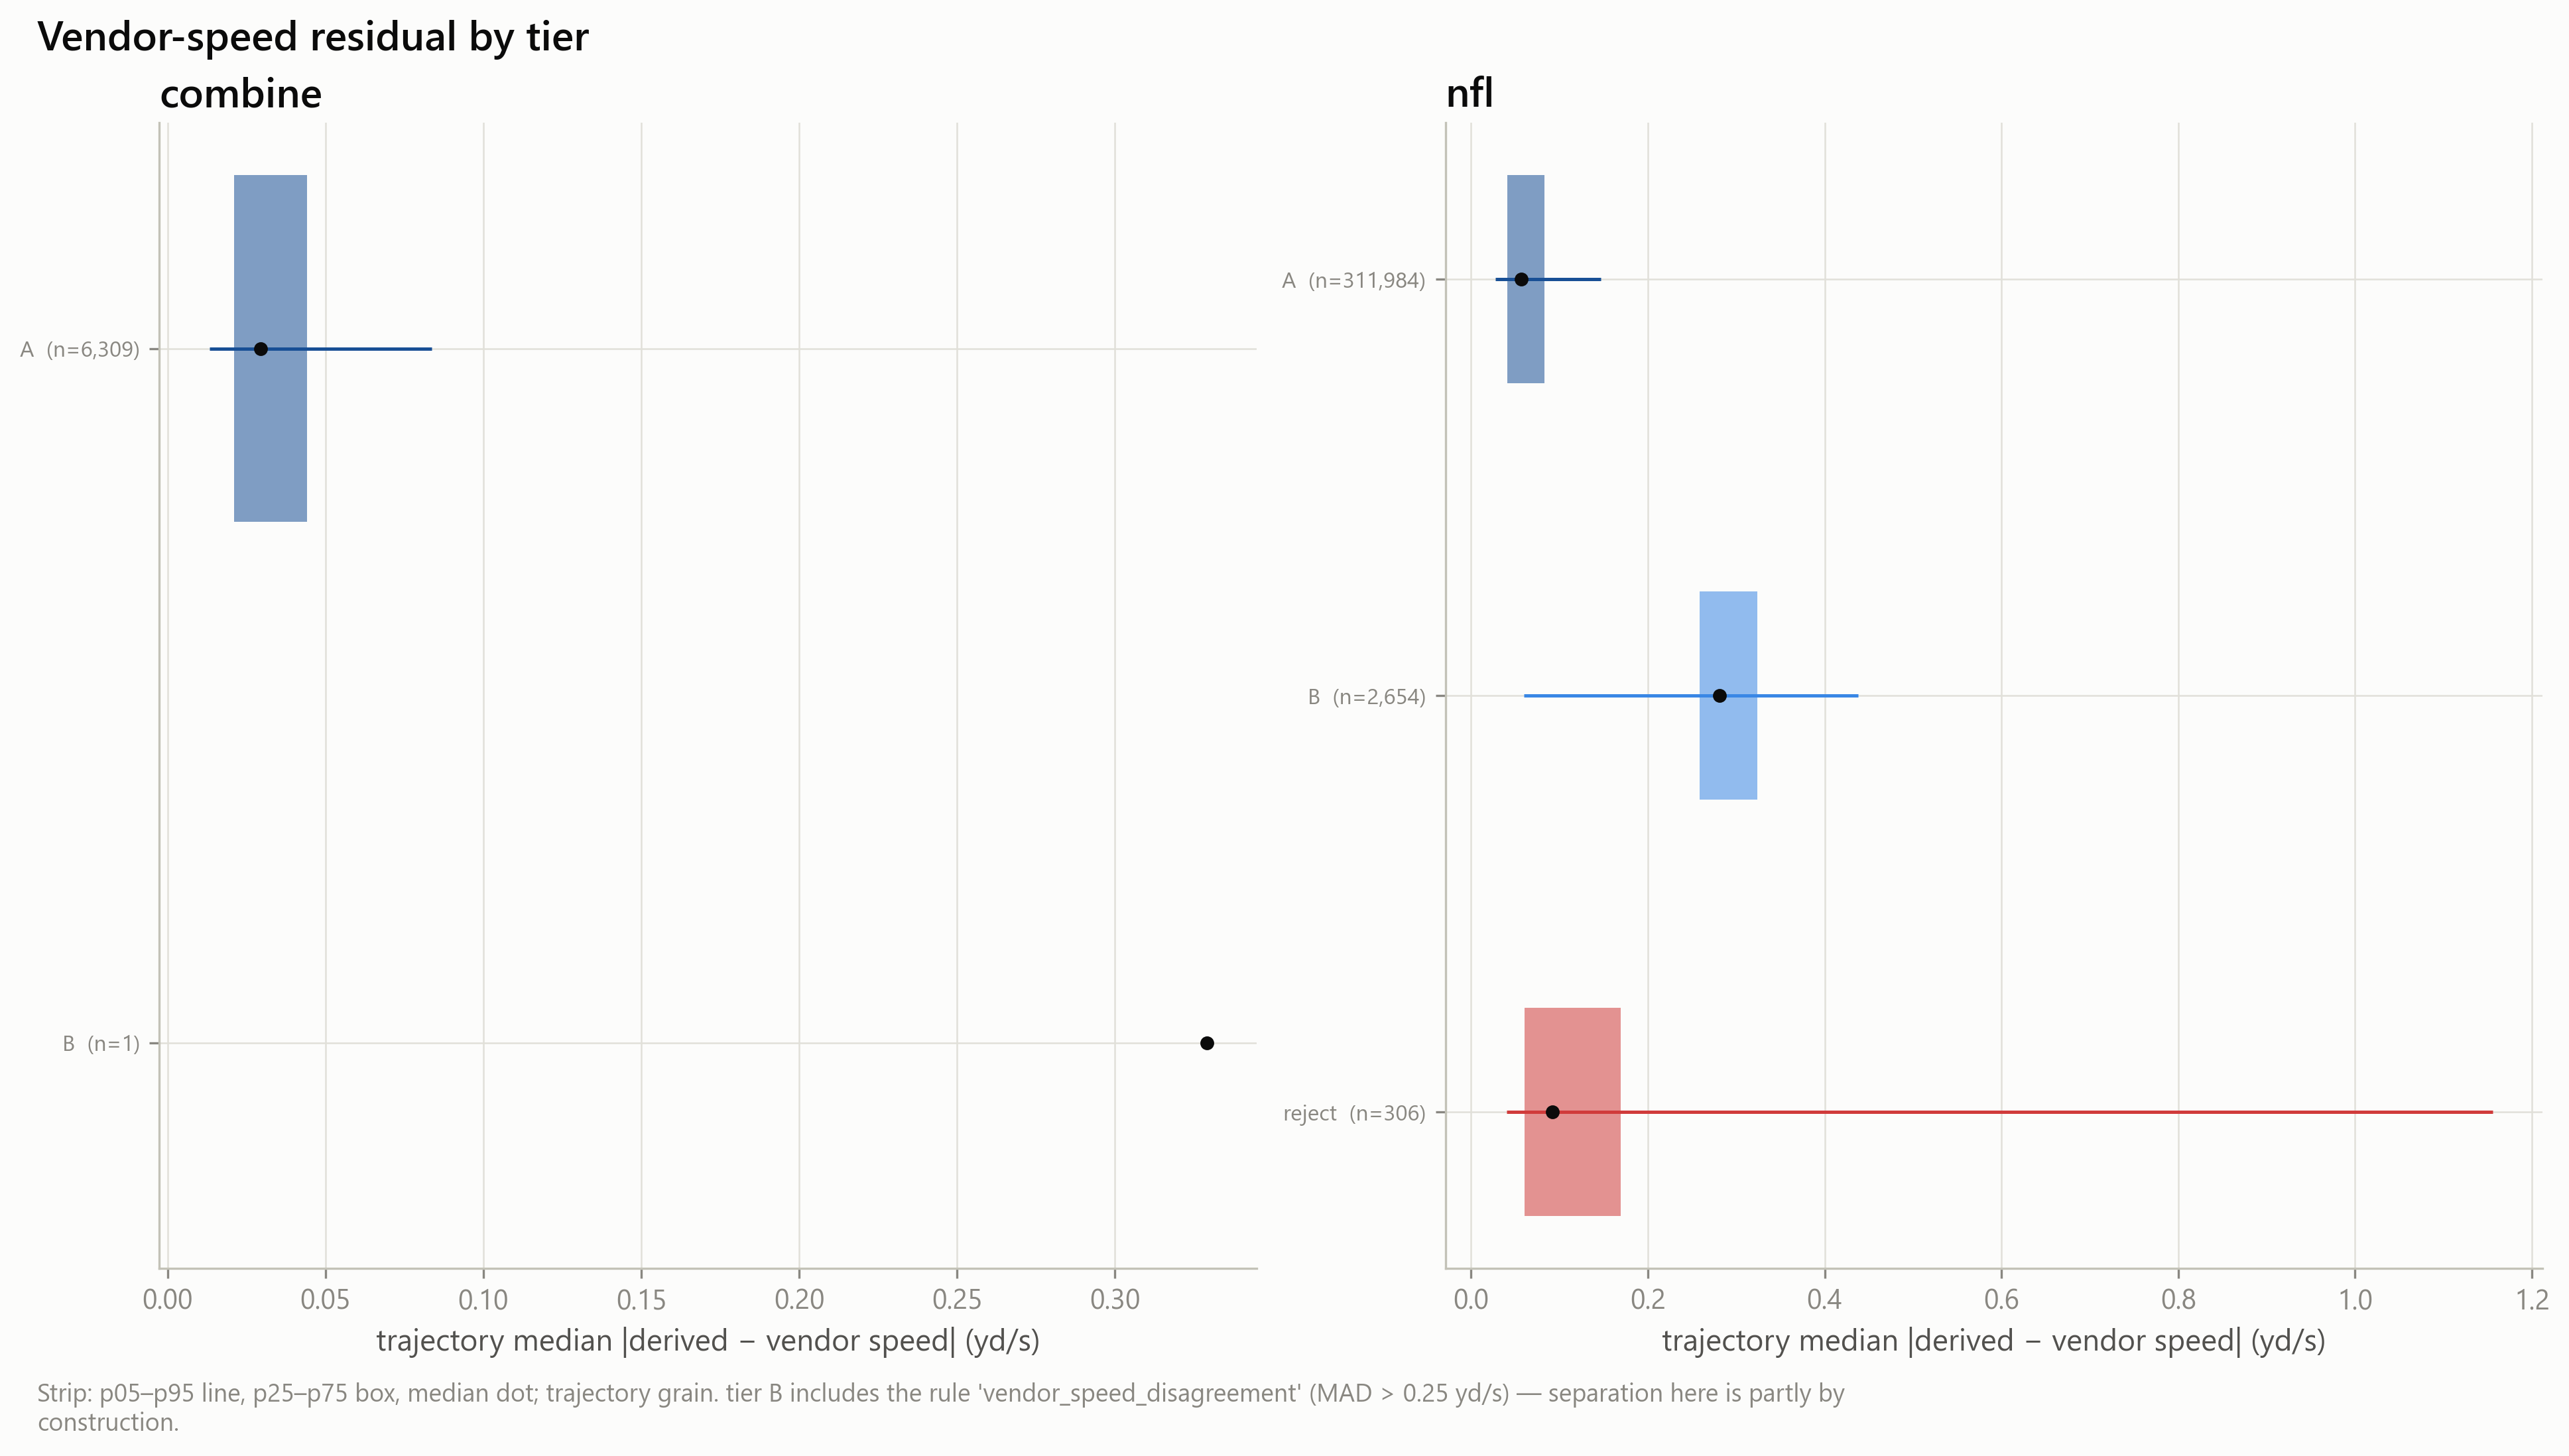

A1_05_acceleration_outliers_by_tier.png


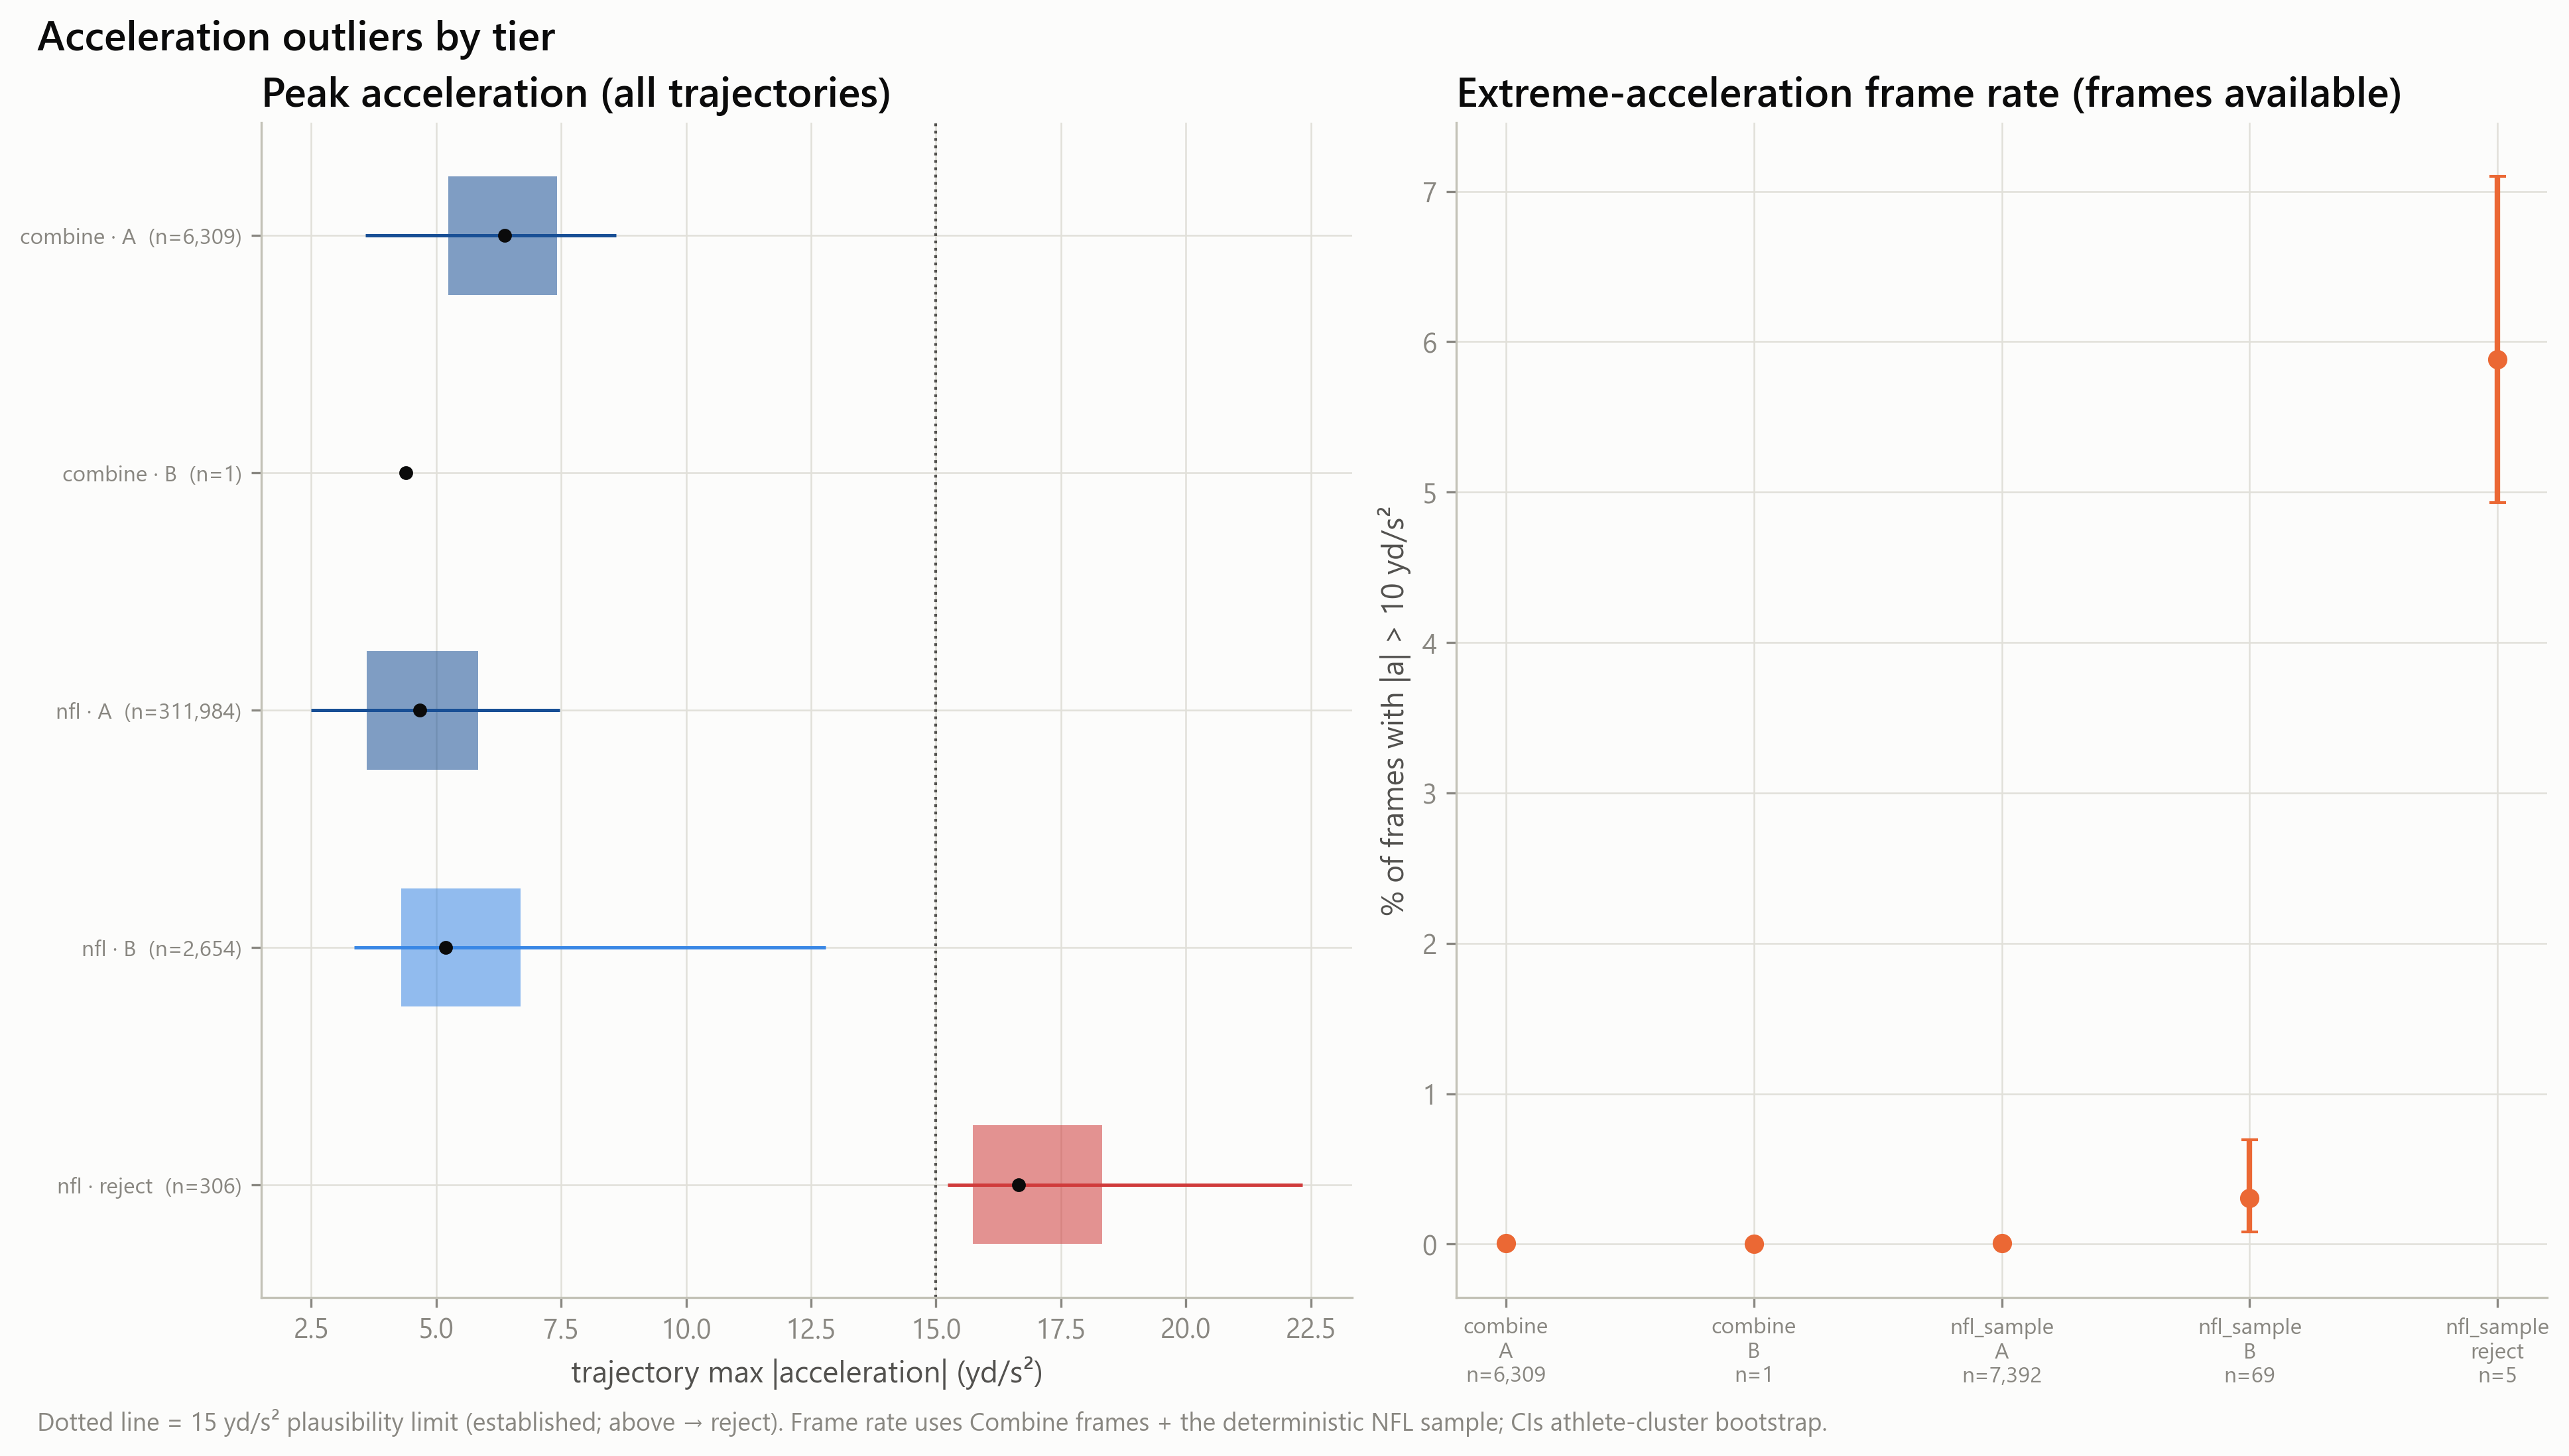

A1_06_duration_vs_quality.png


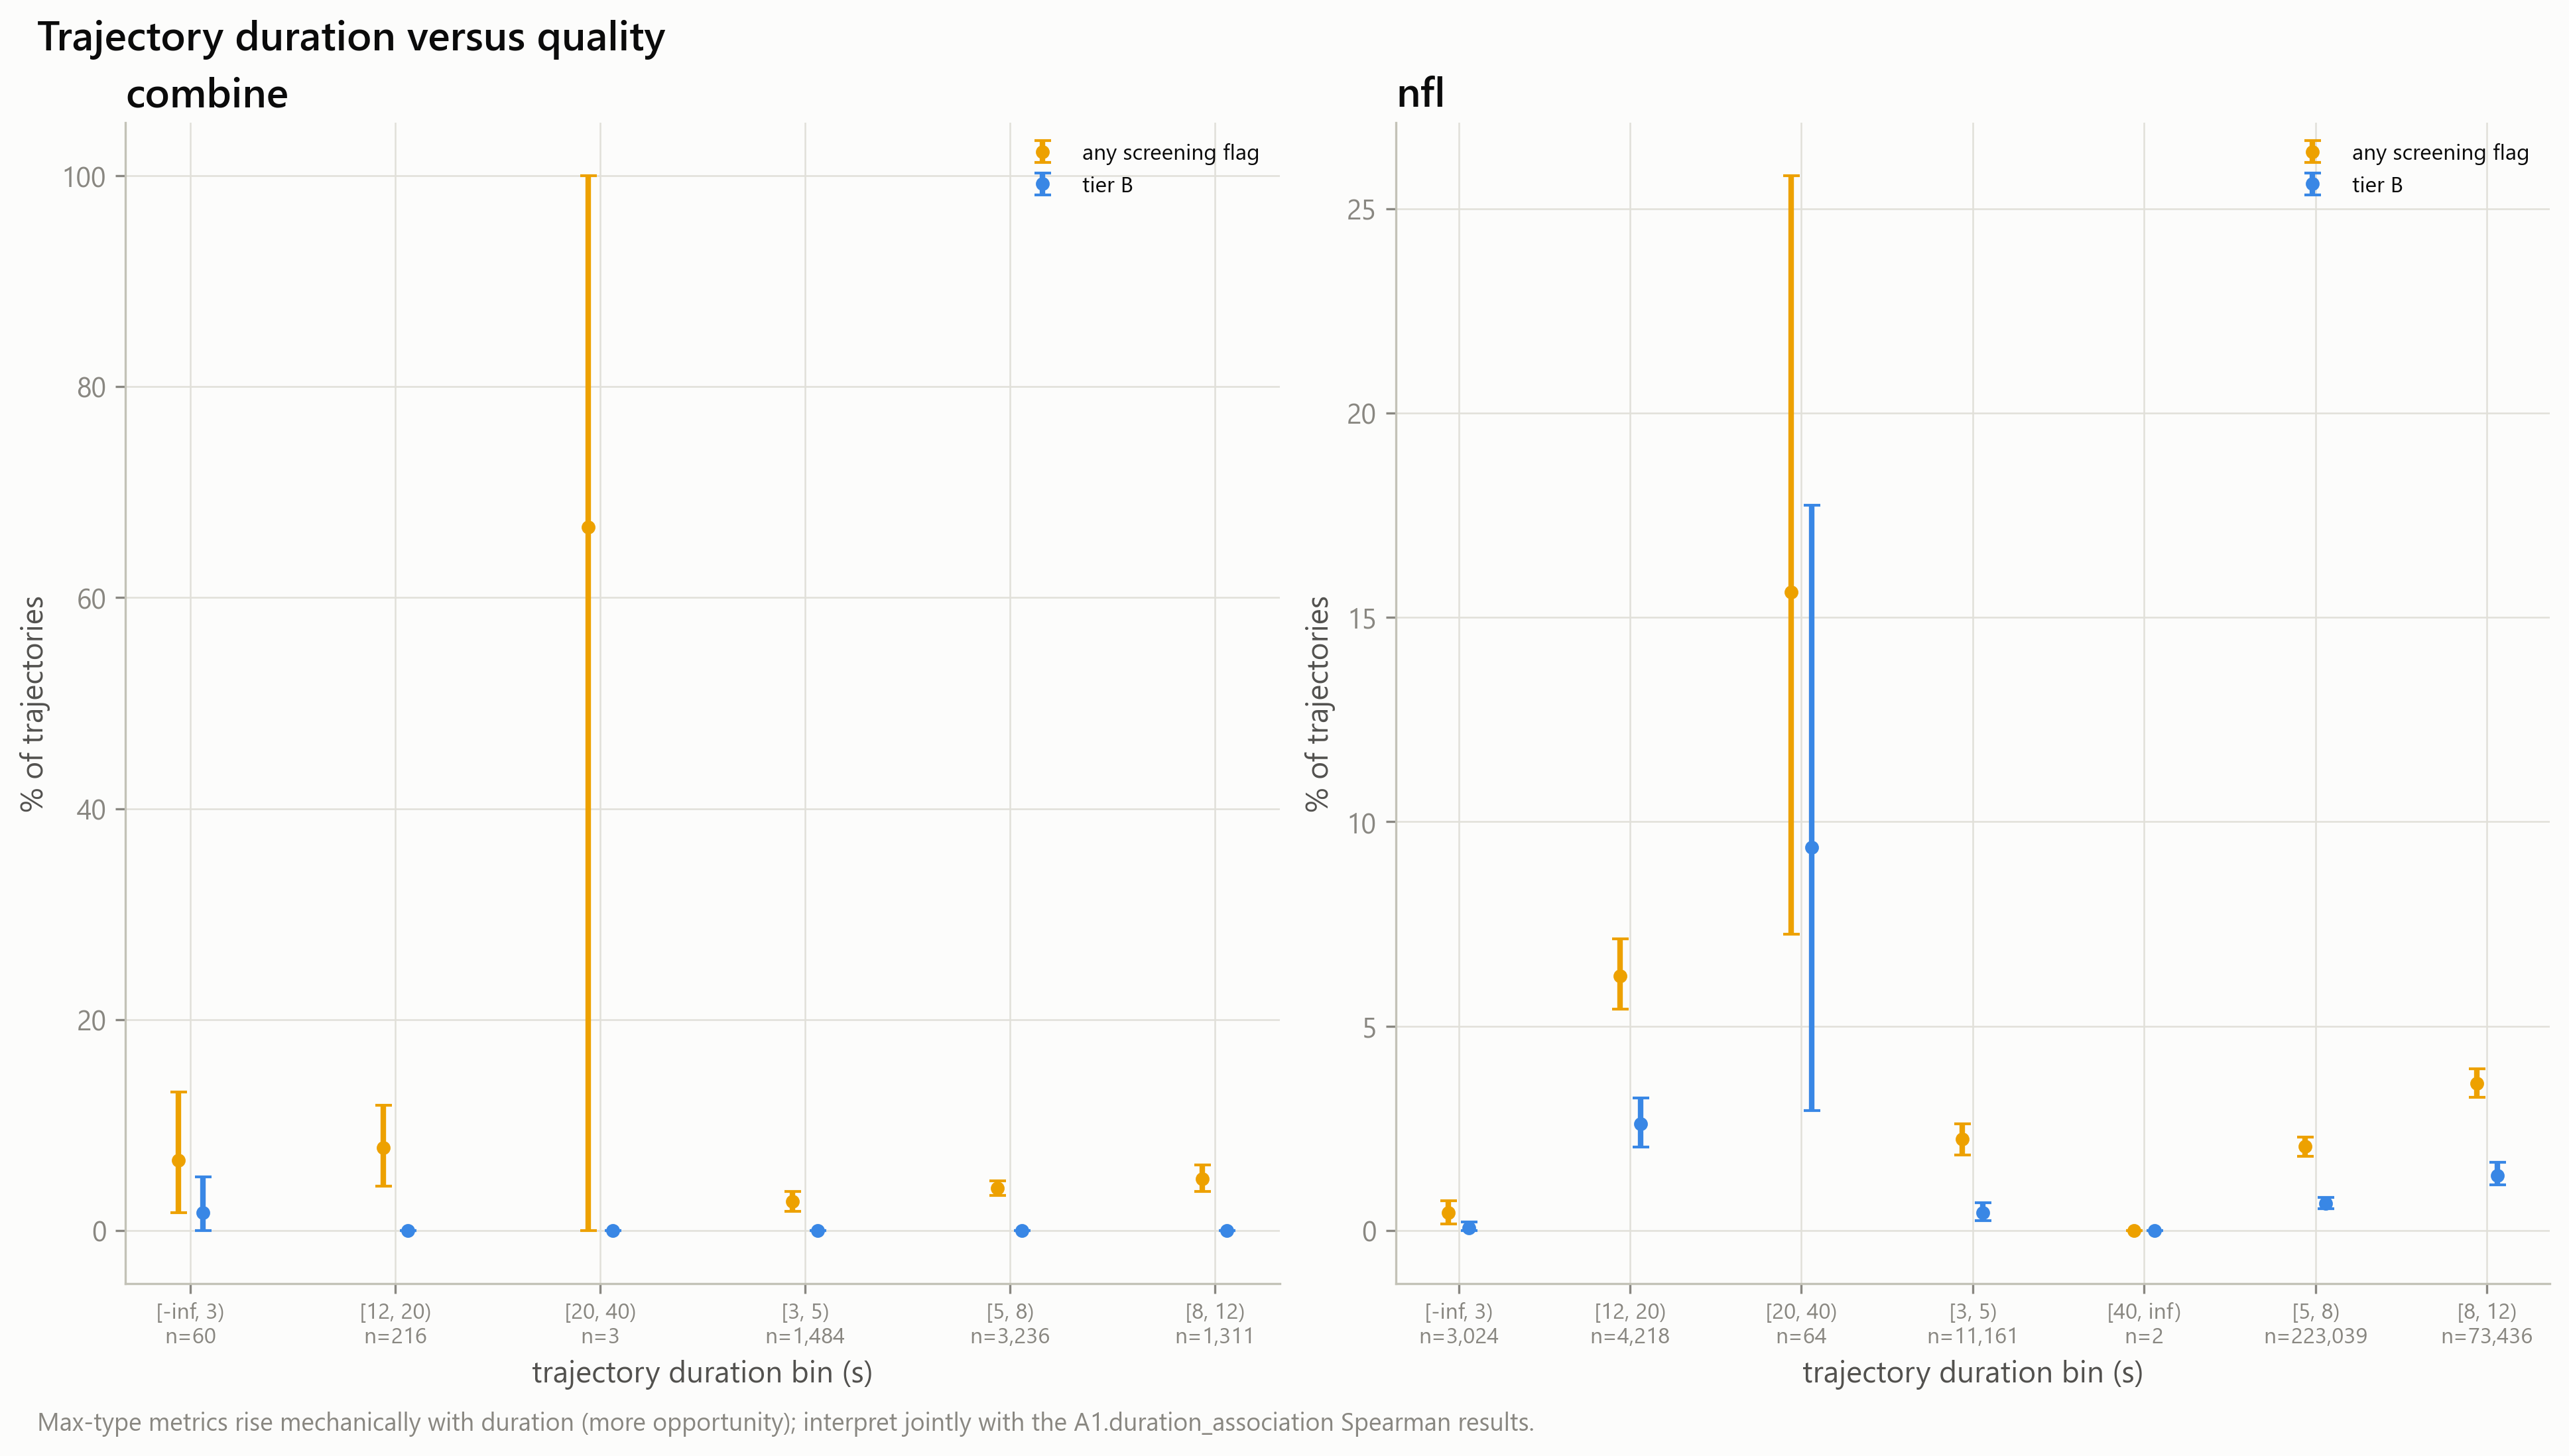

A1_07_failure_reason_heatmap.png


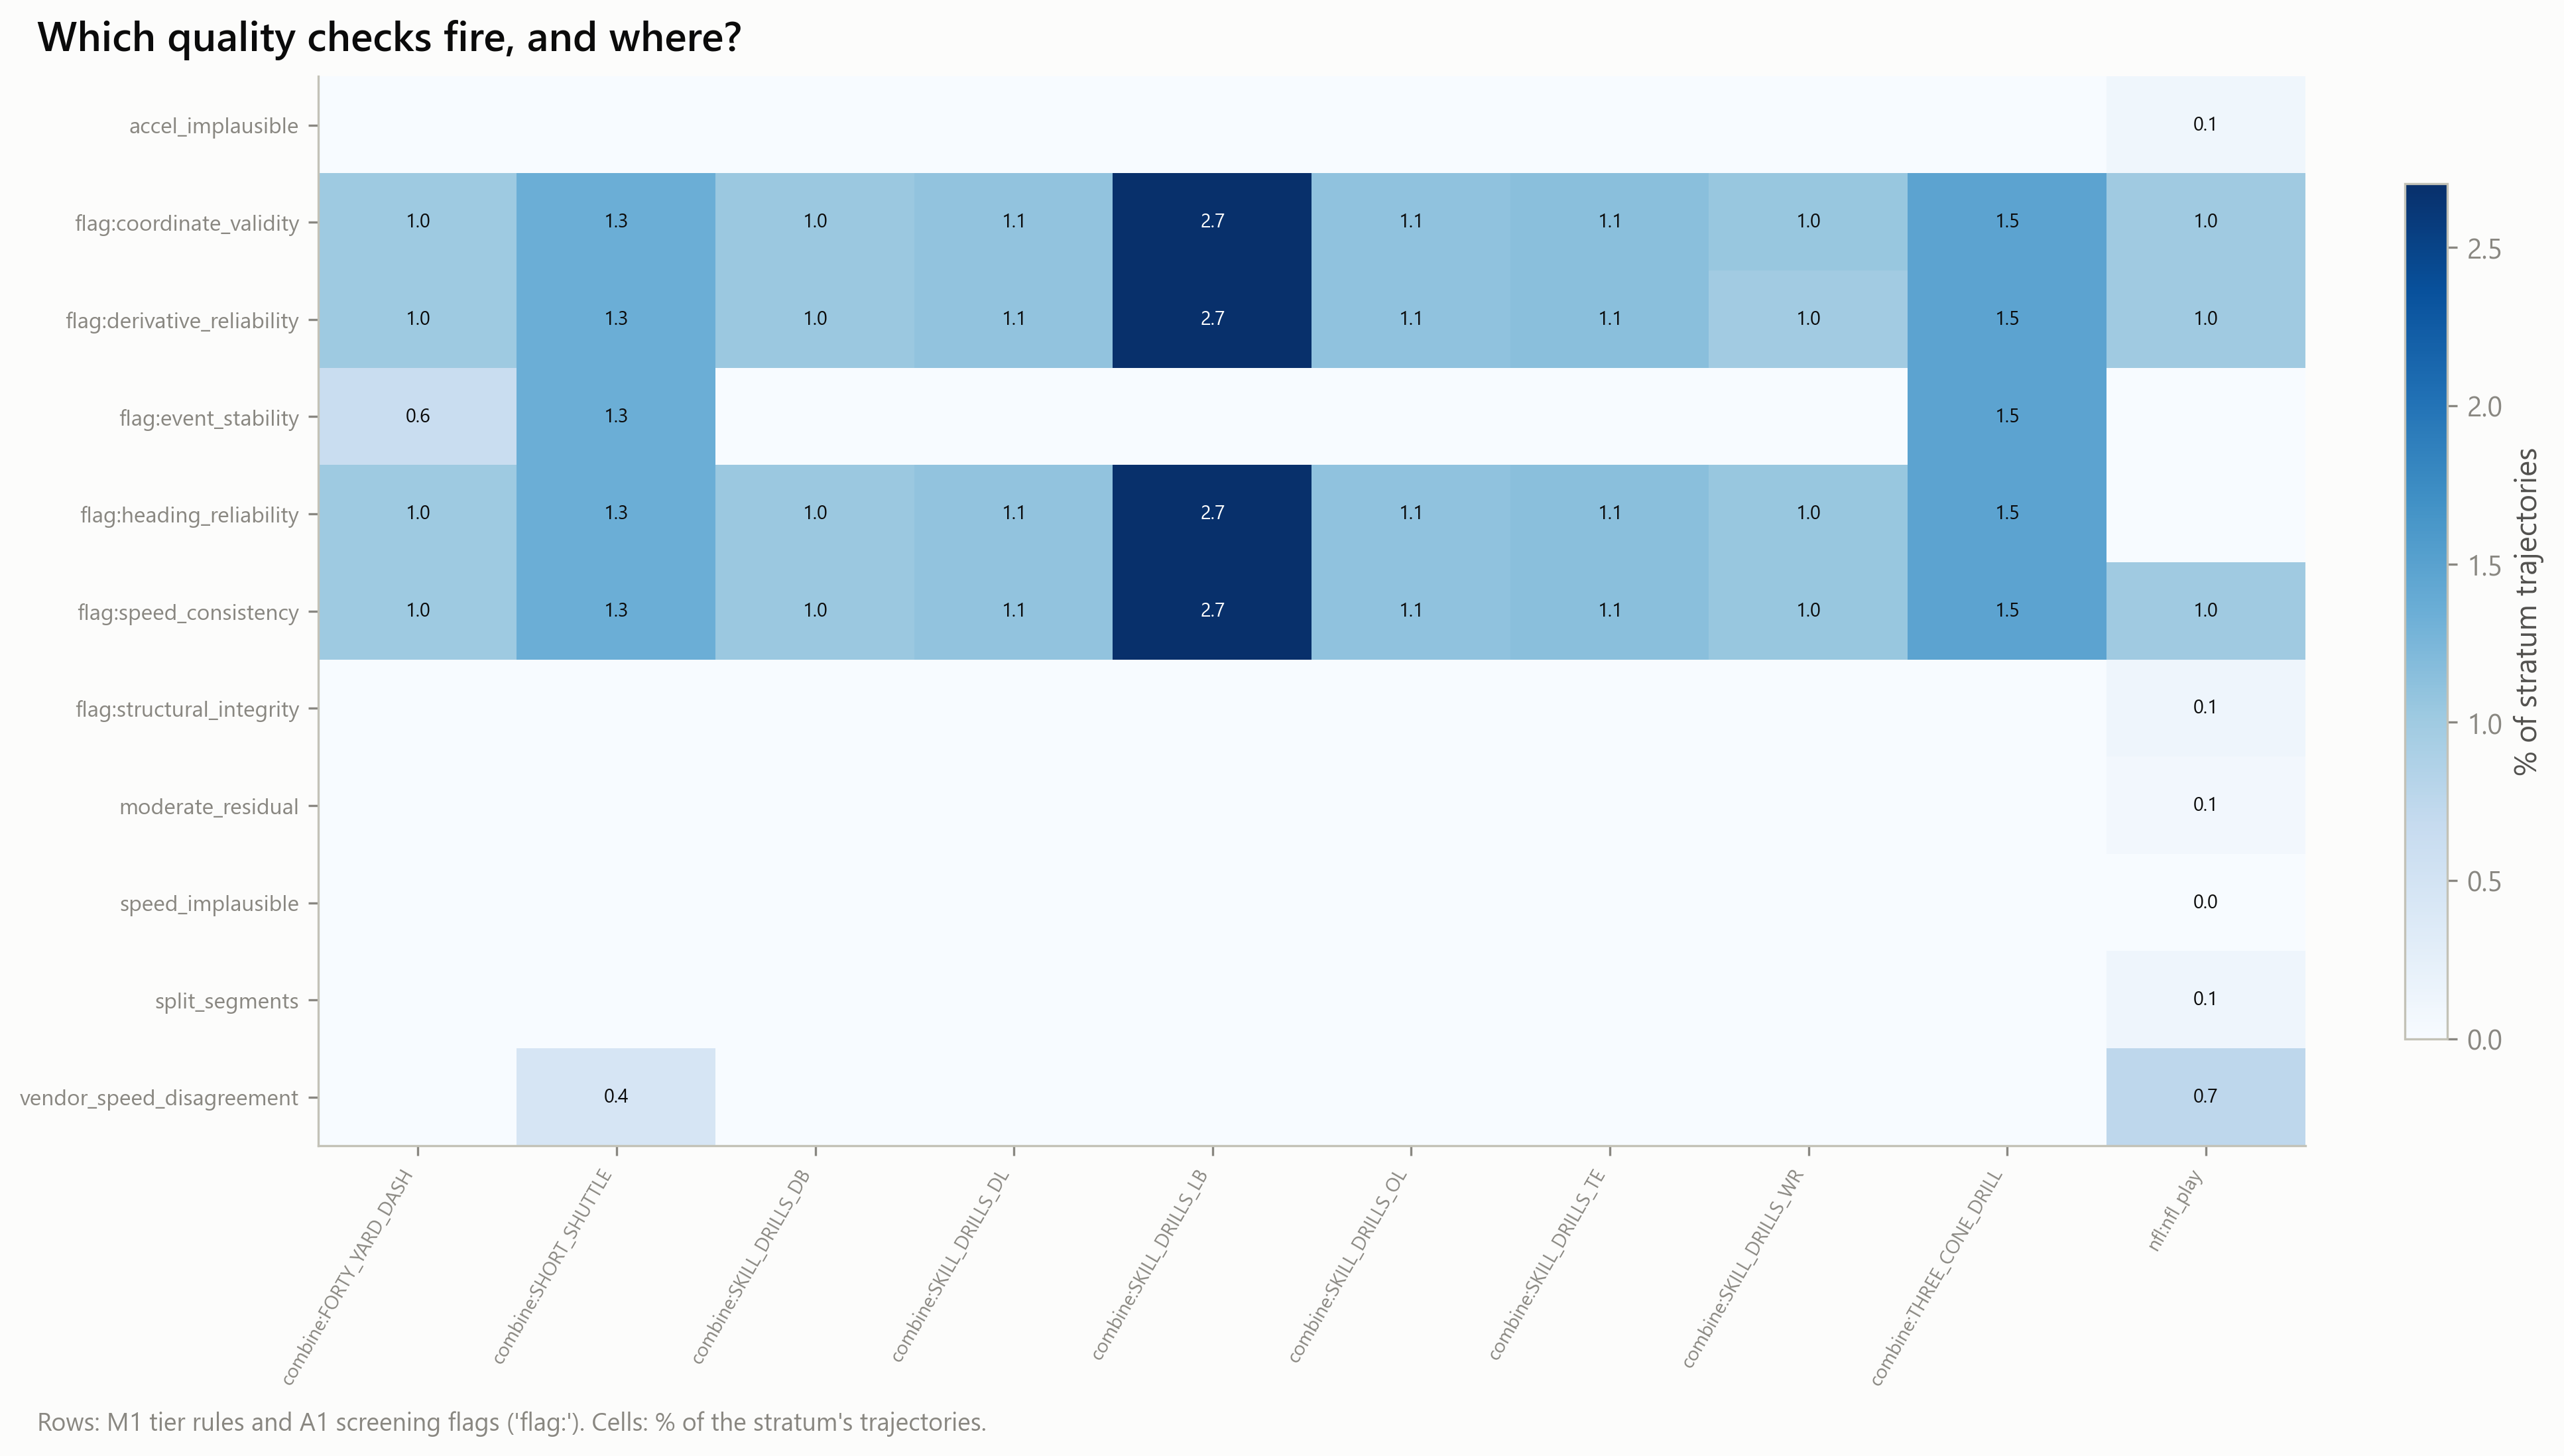

A1_08_quality_vs_smoothing_instability.png


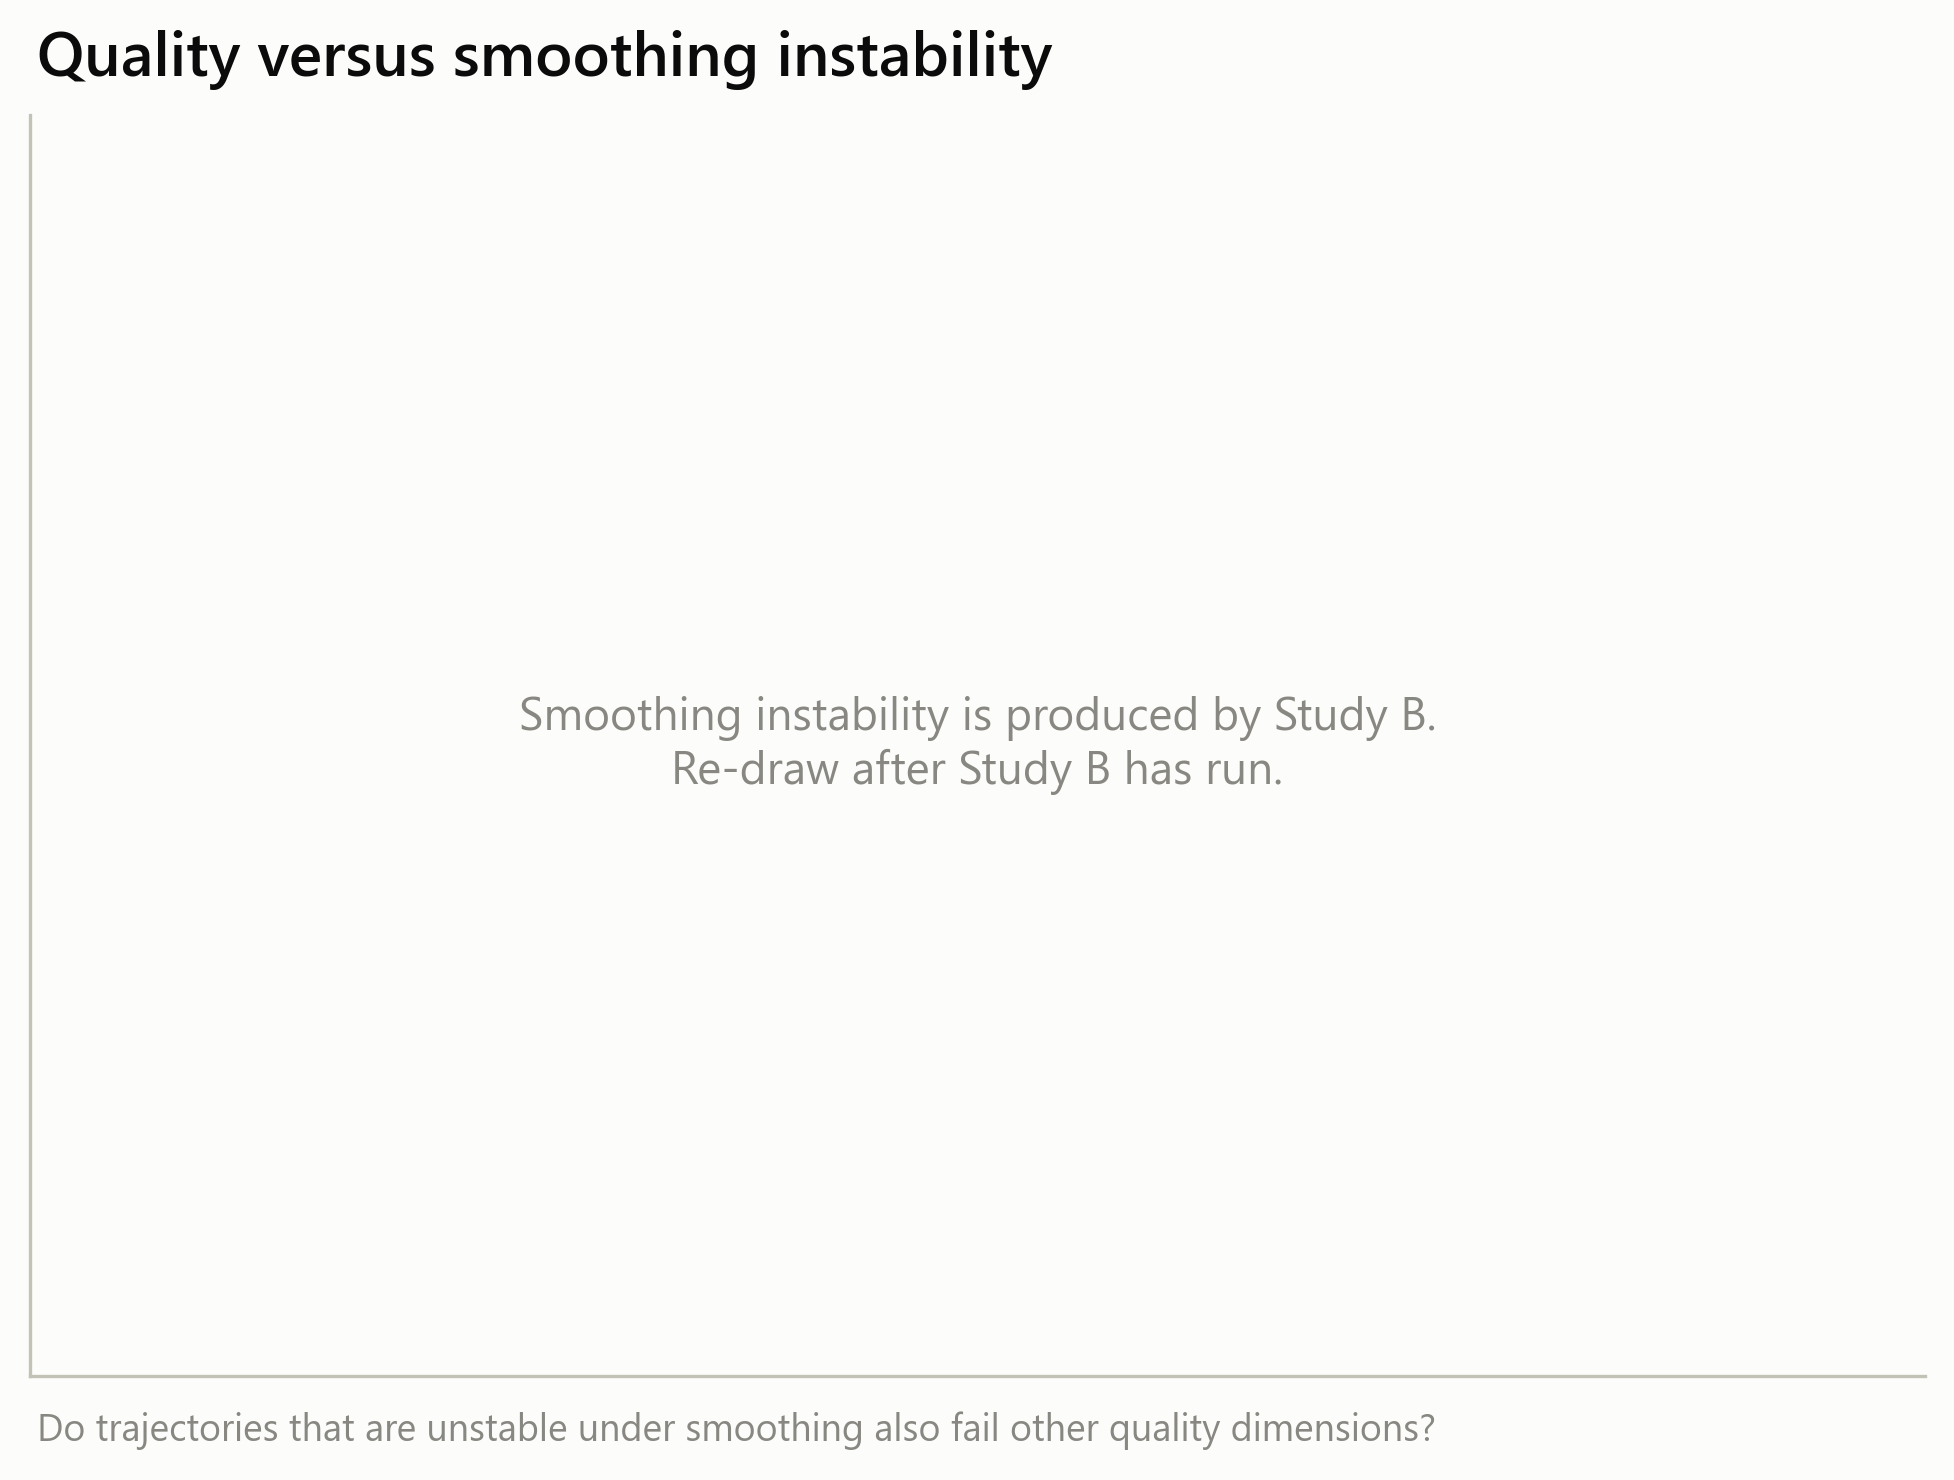

A1_09_representative_trajectories.png


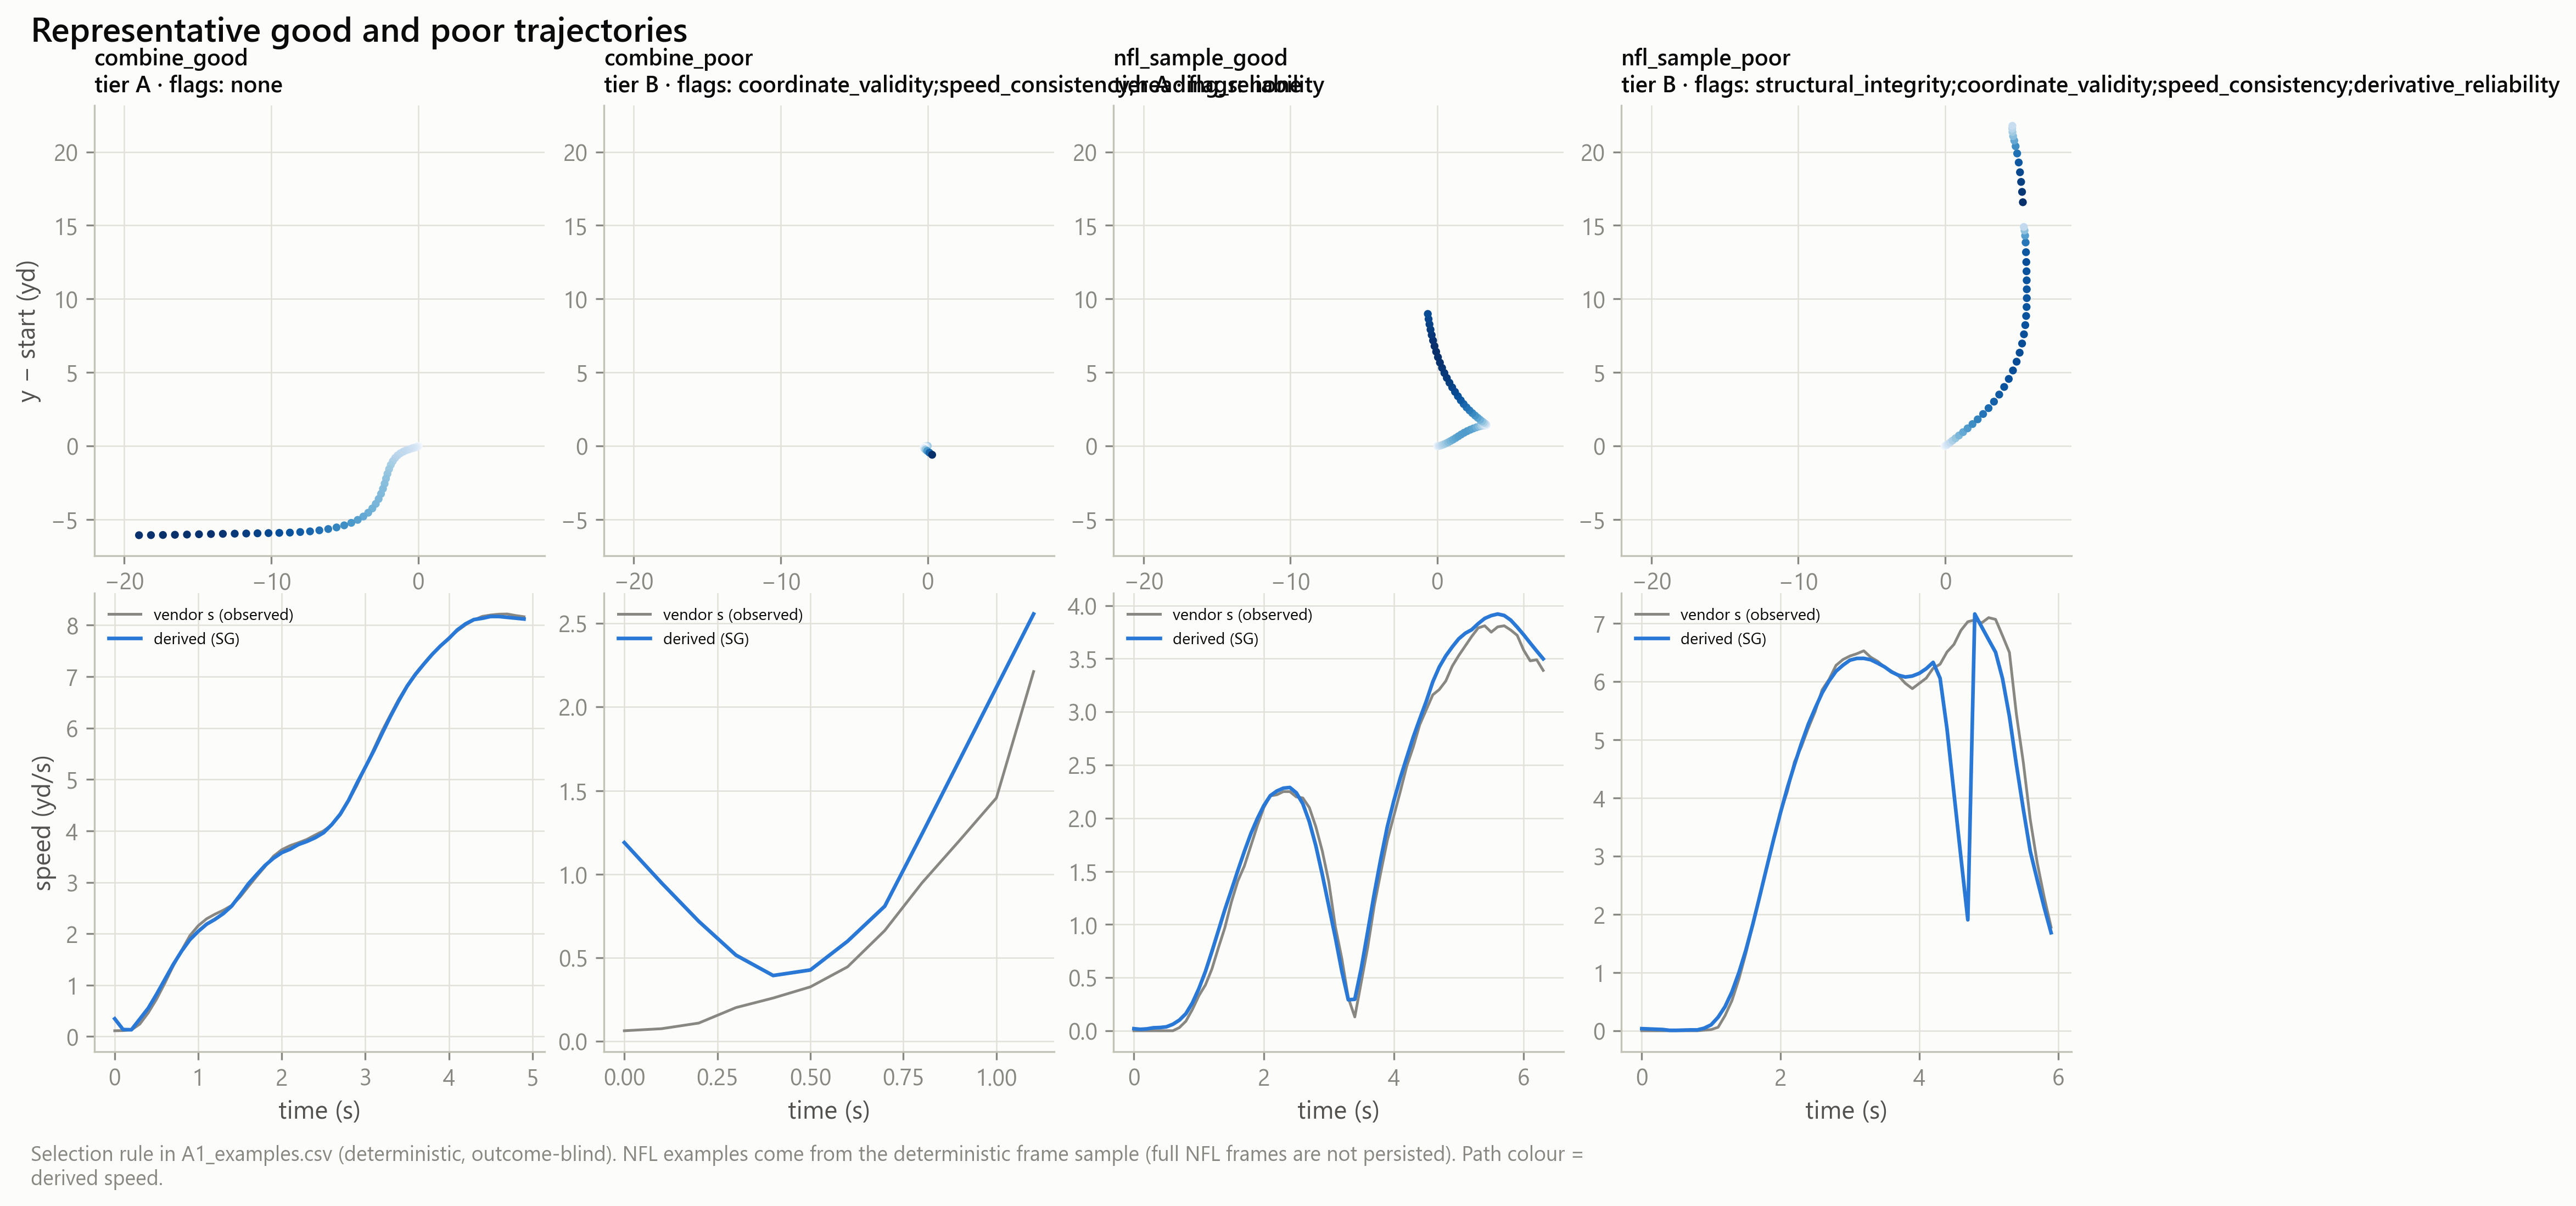

A1_10_filter_impact.png


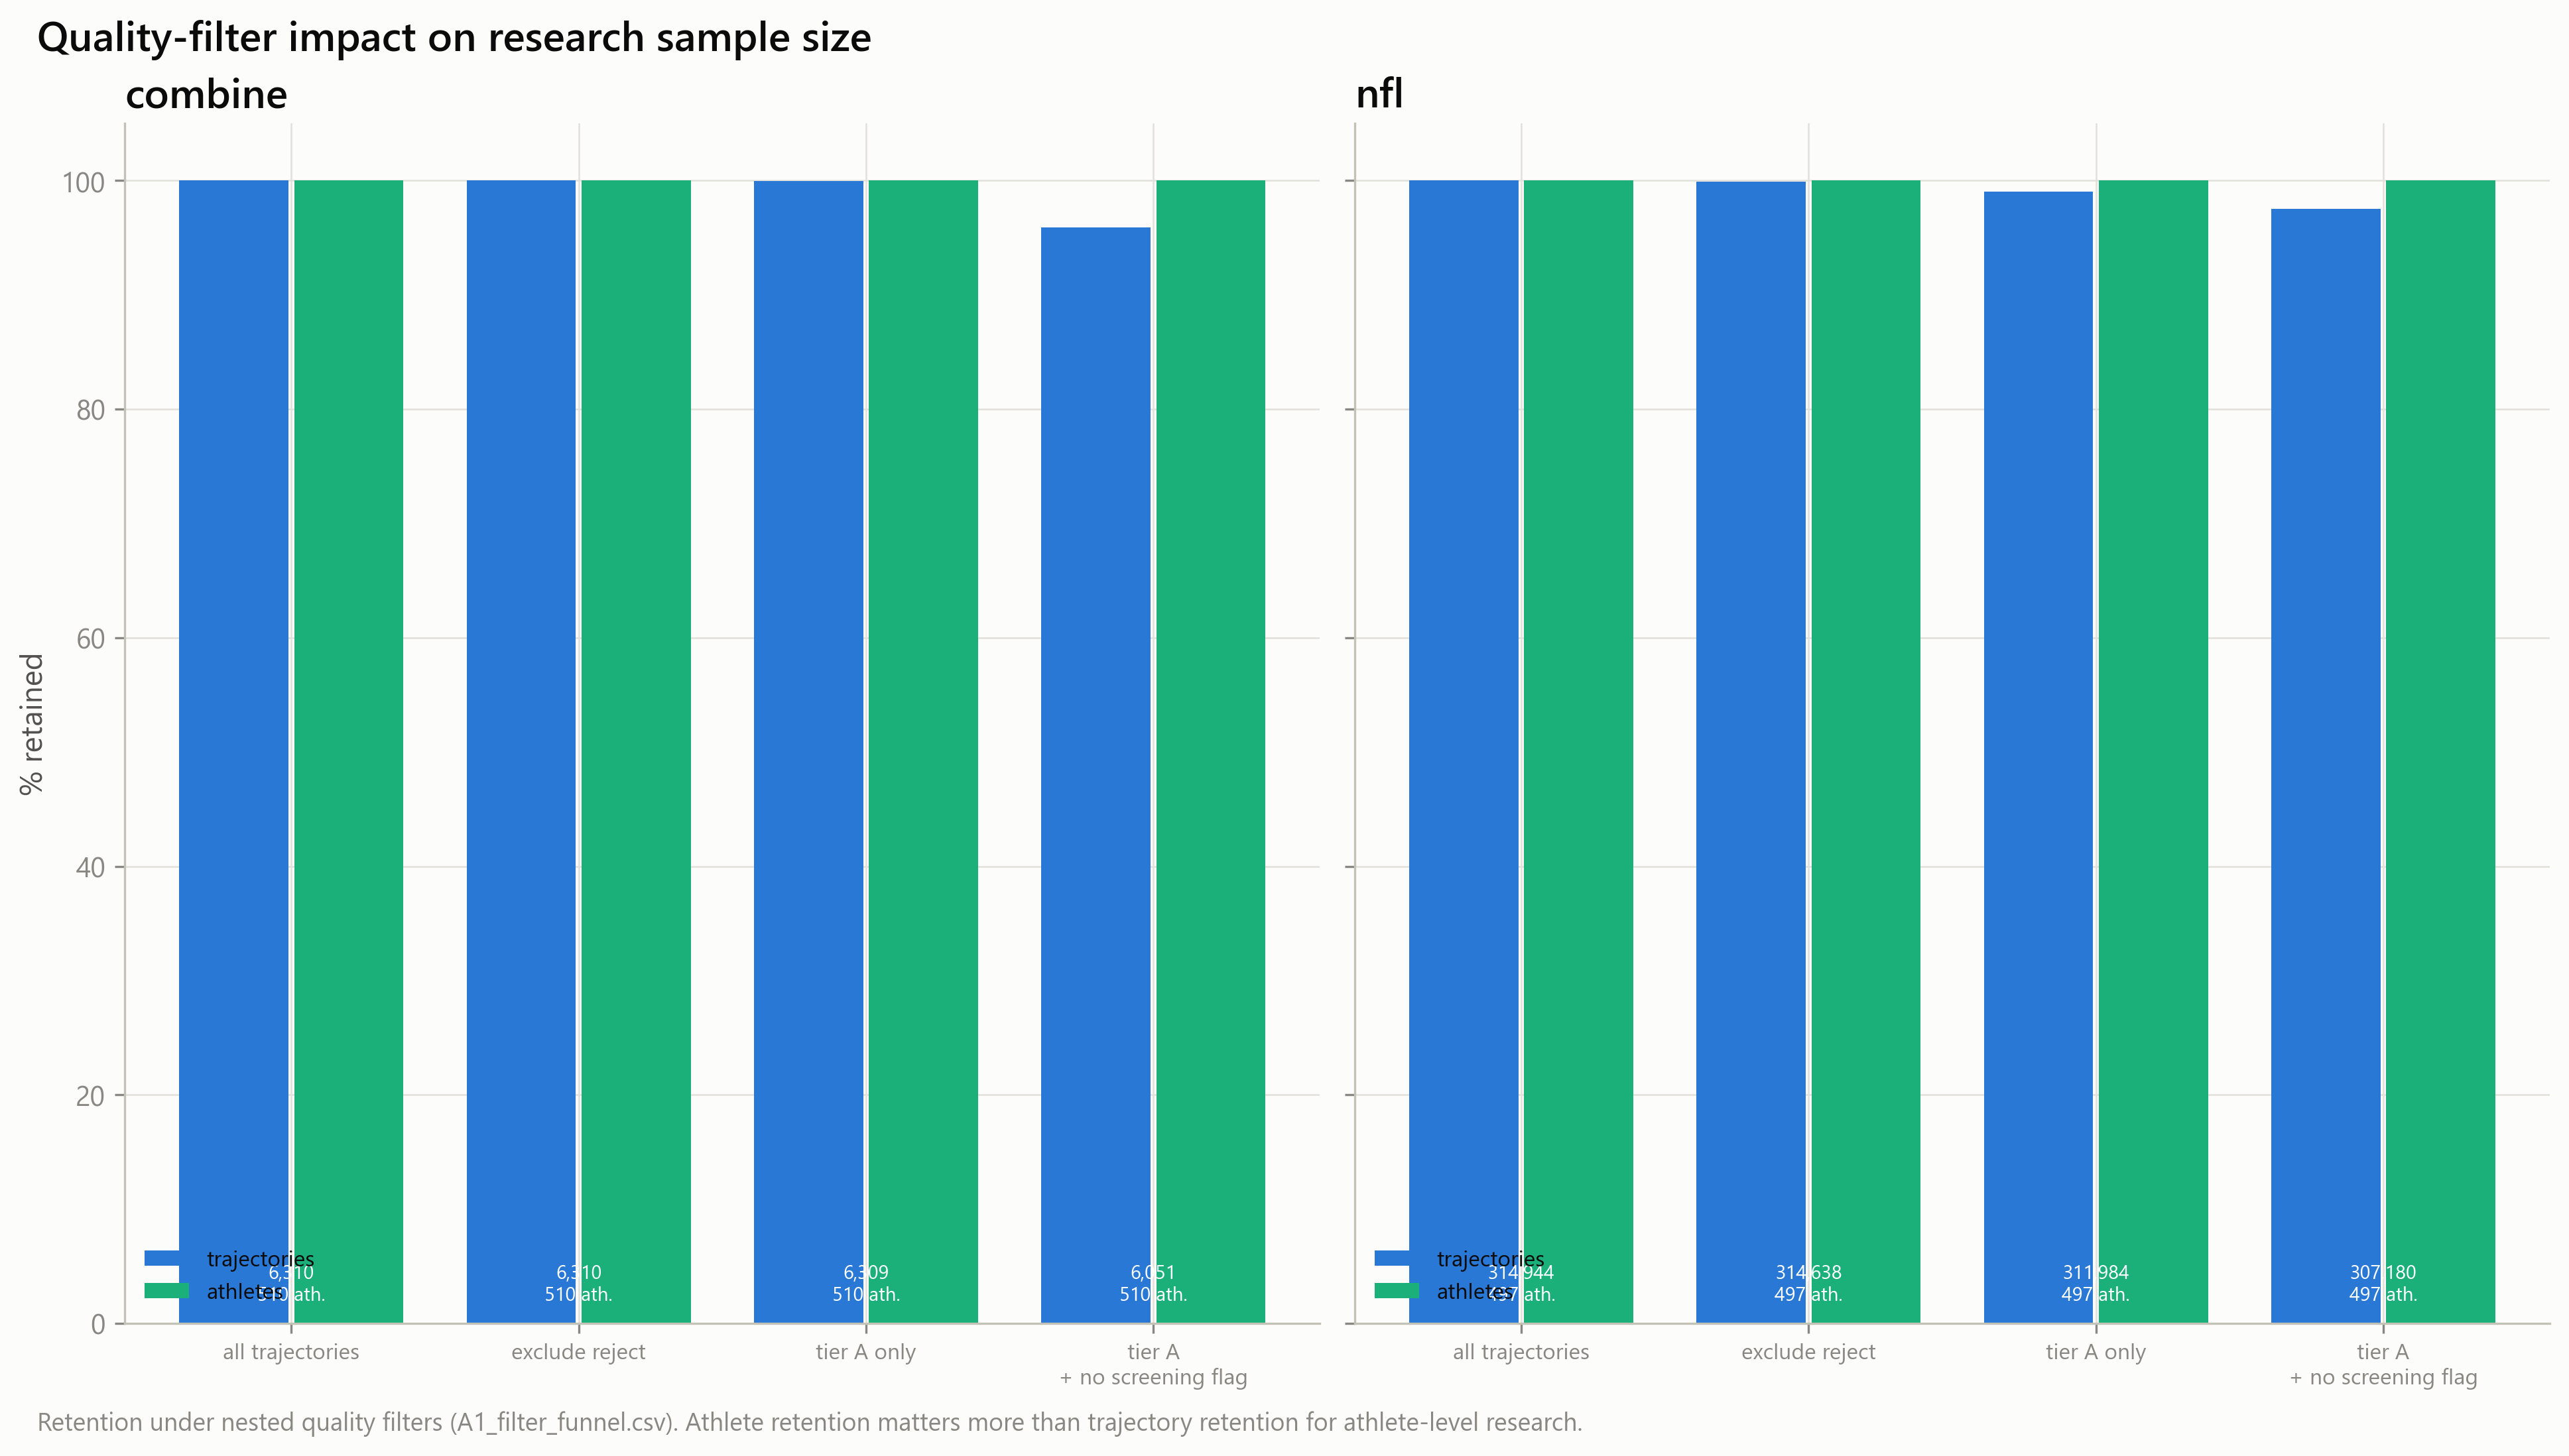

A2_01_vendor_vs_derived_hist.png


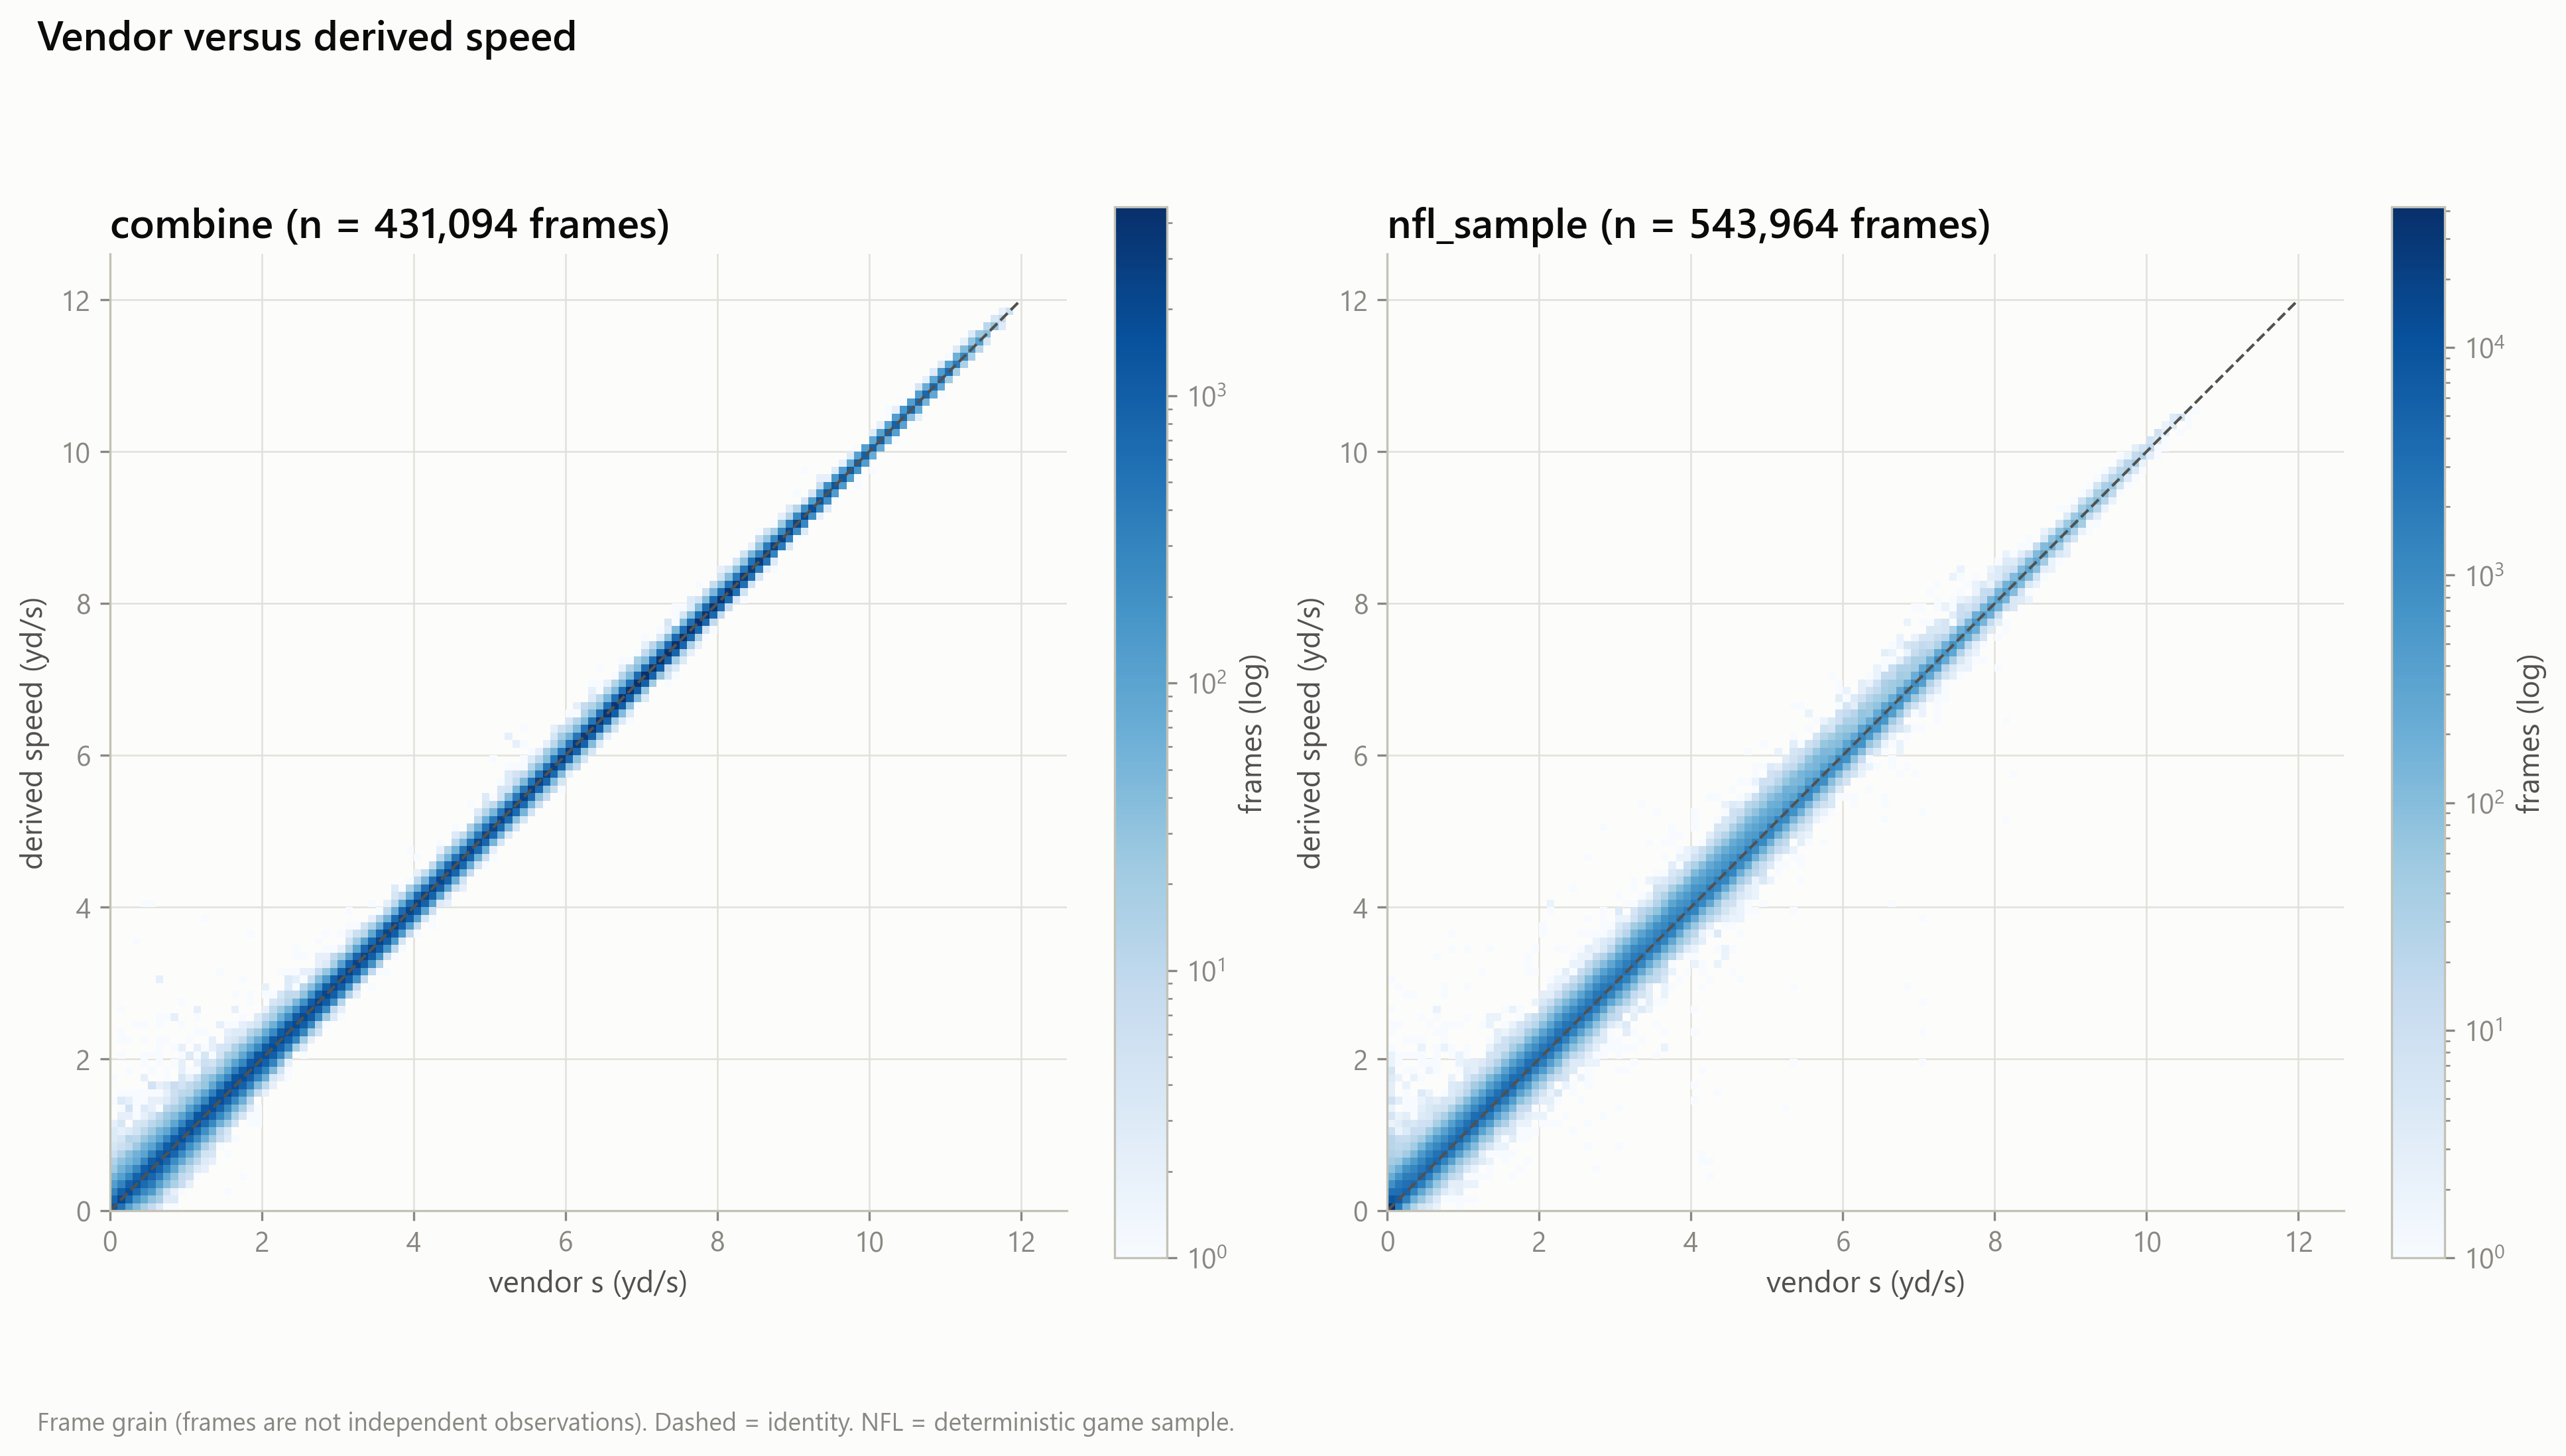

A2_02_residual_vs_speed.png


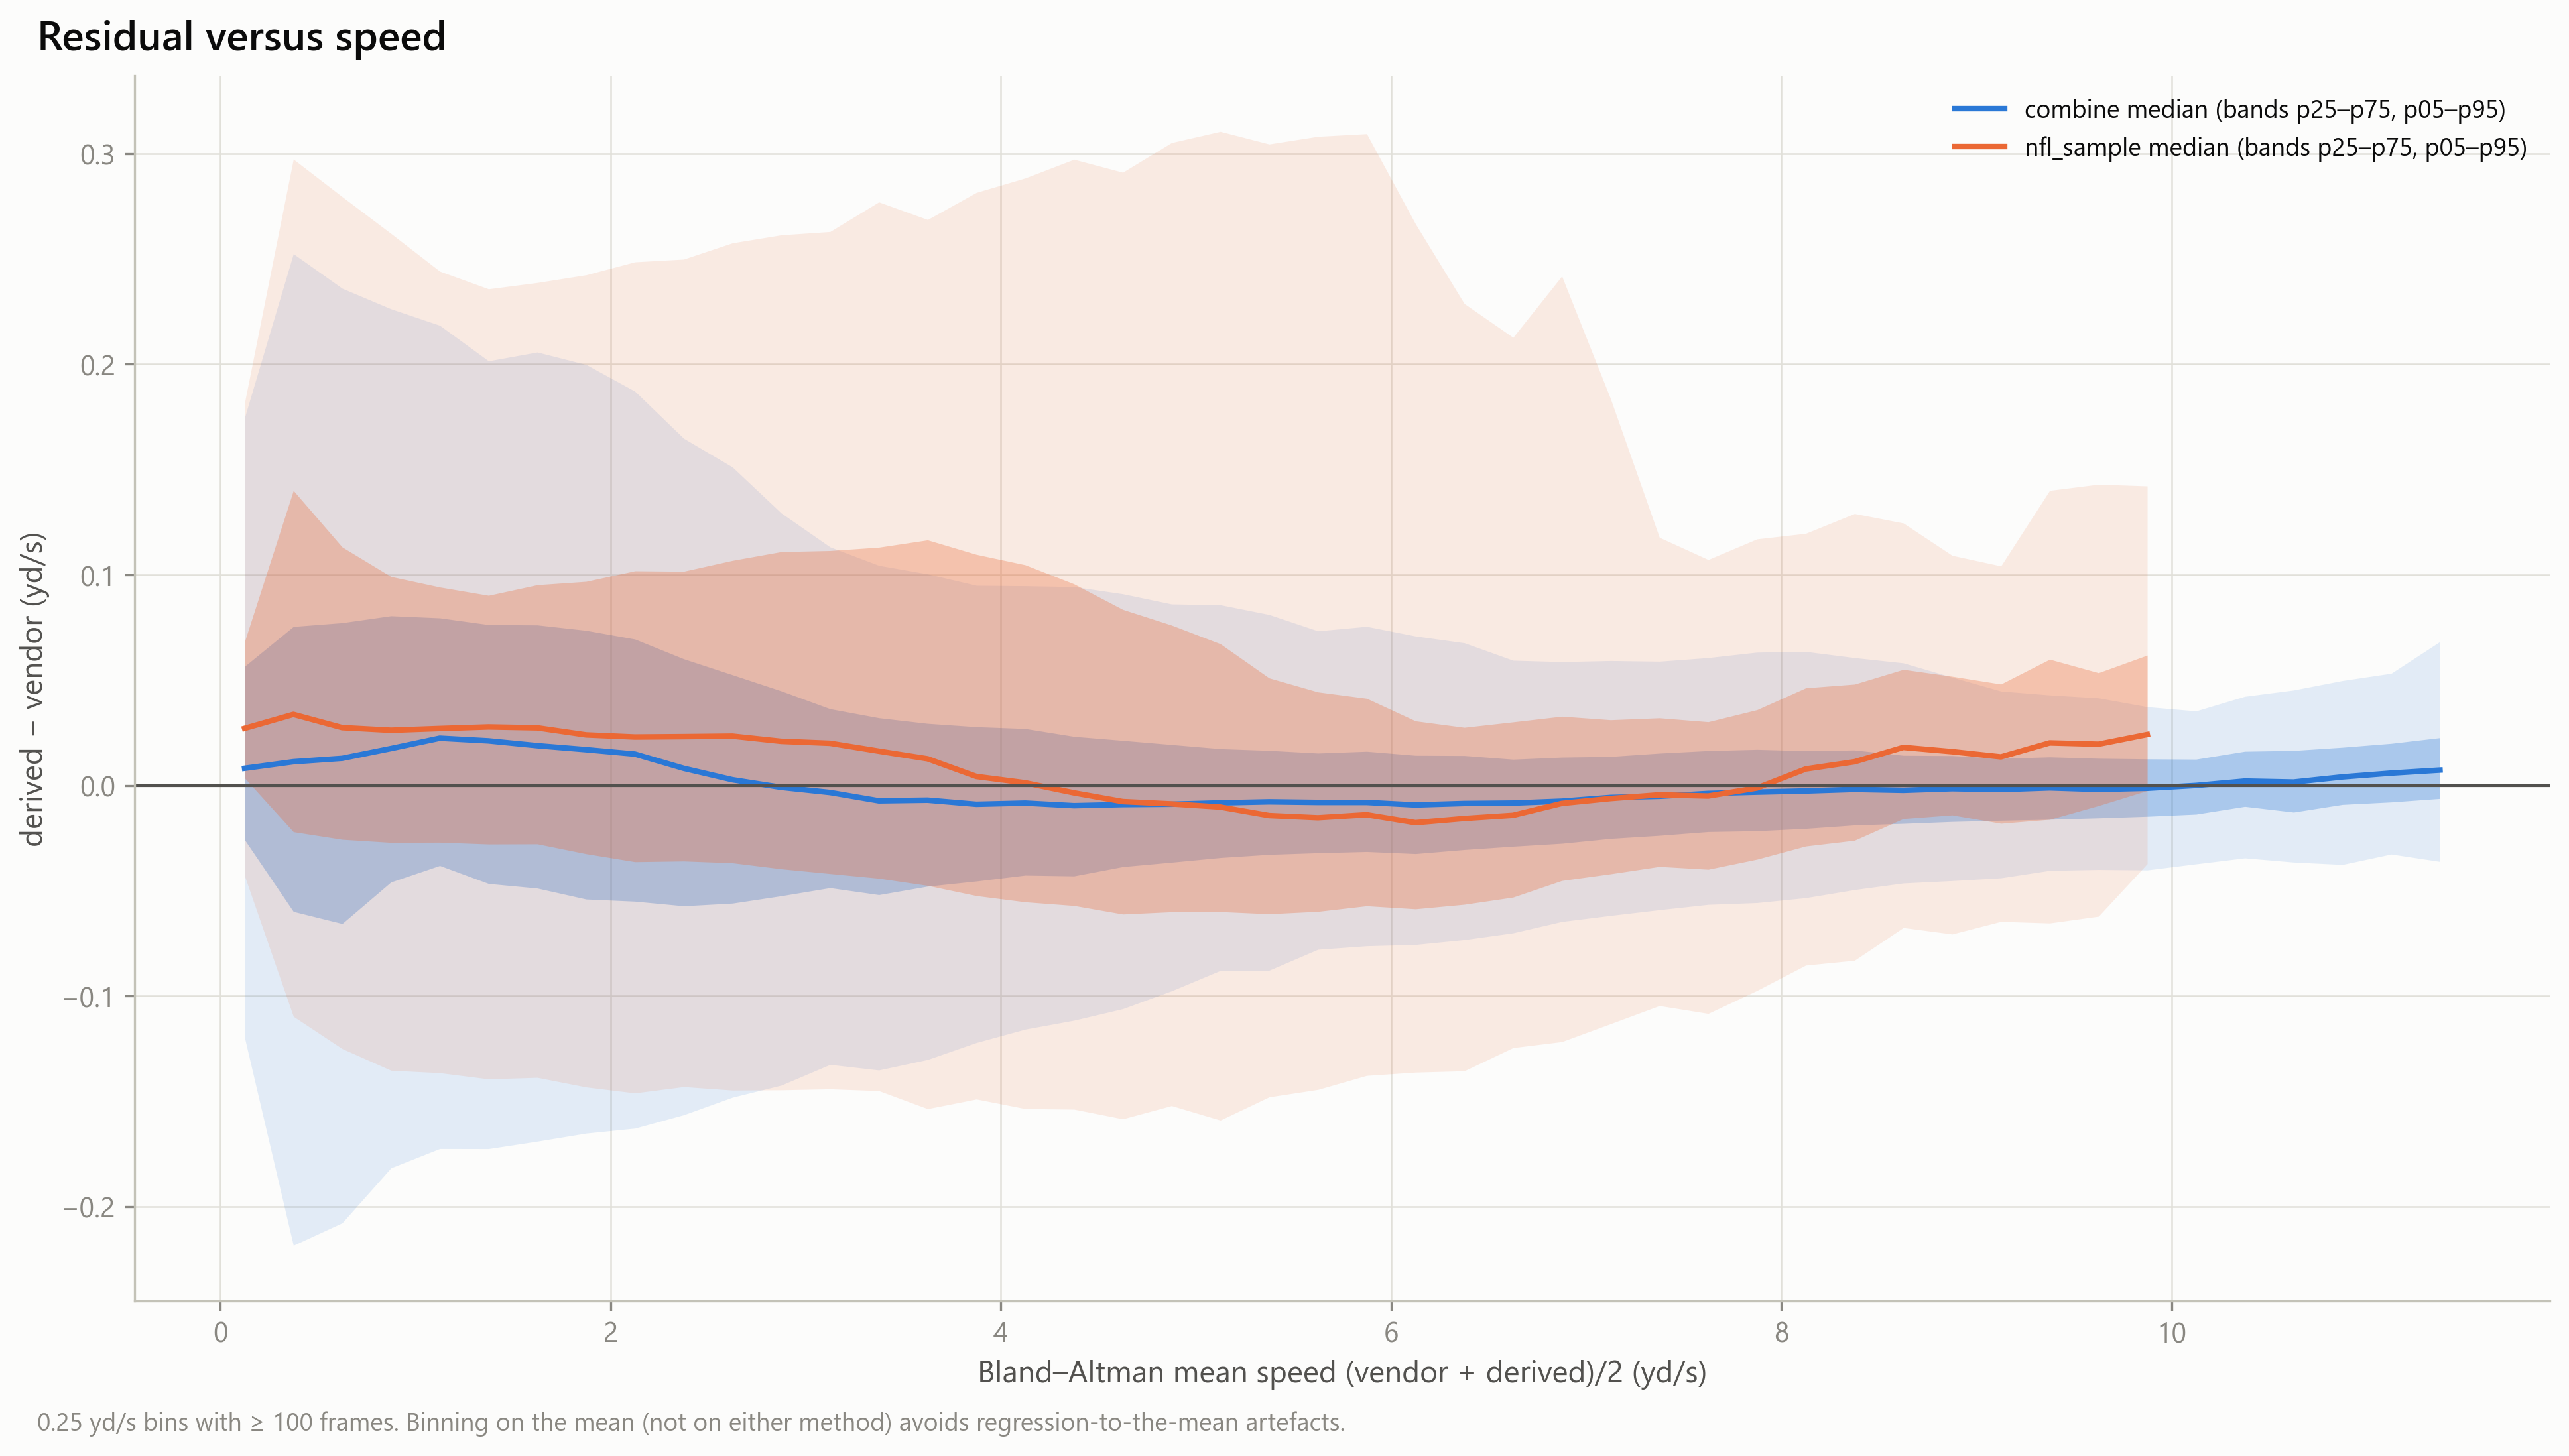

A2_03_abs_error_vs_speed.png


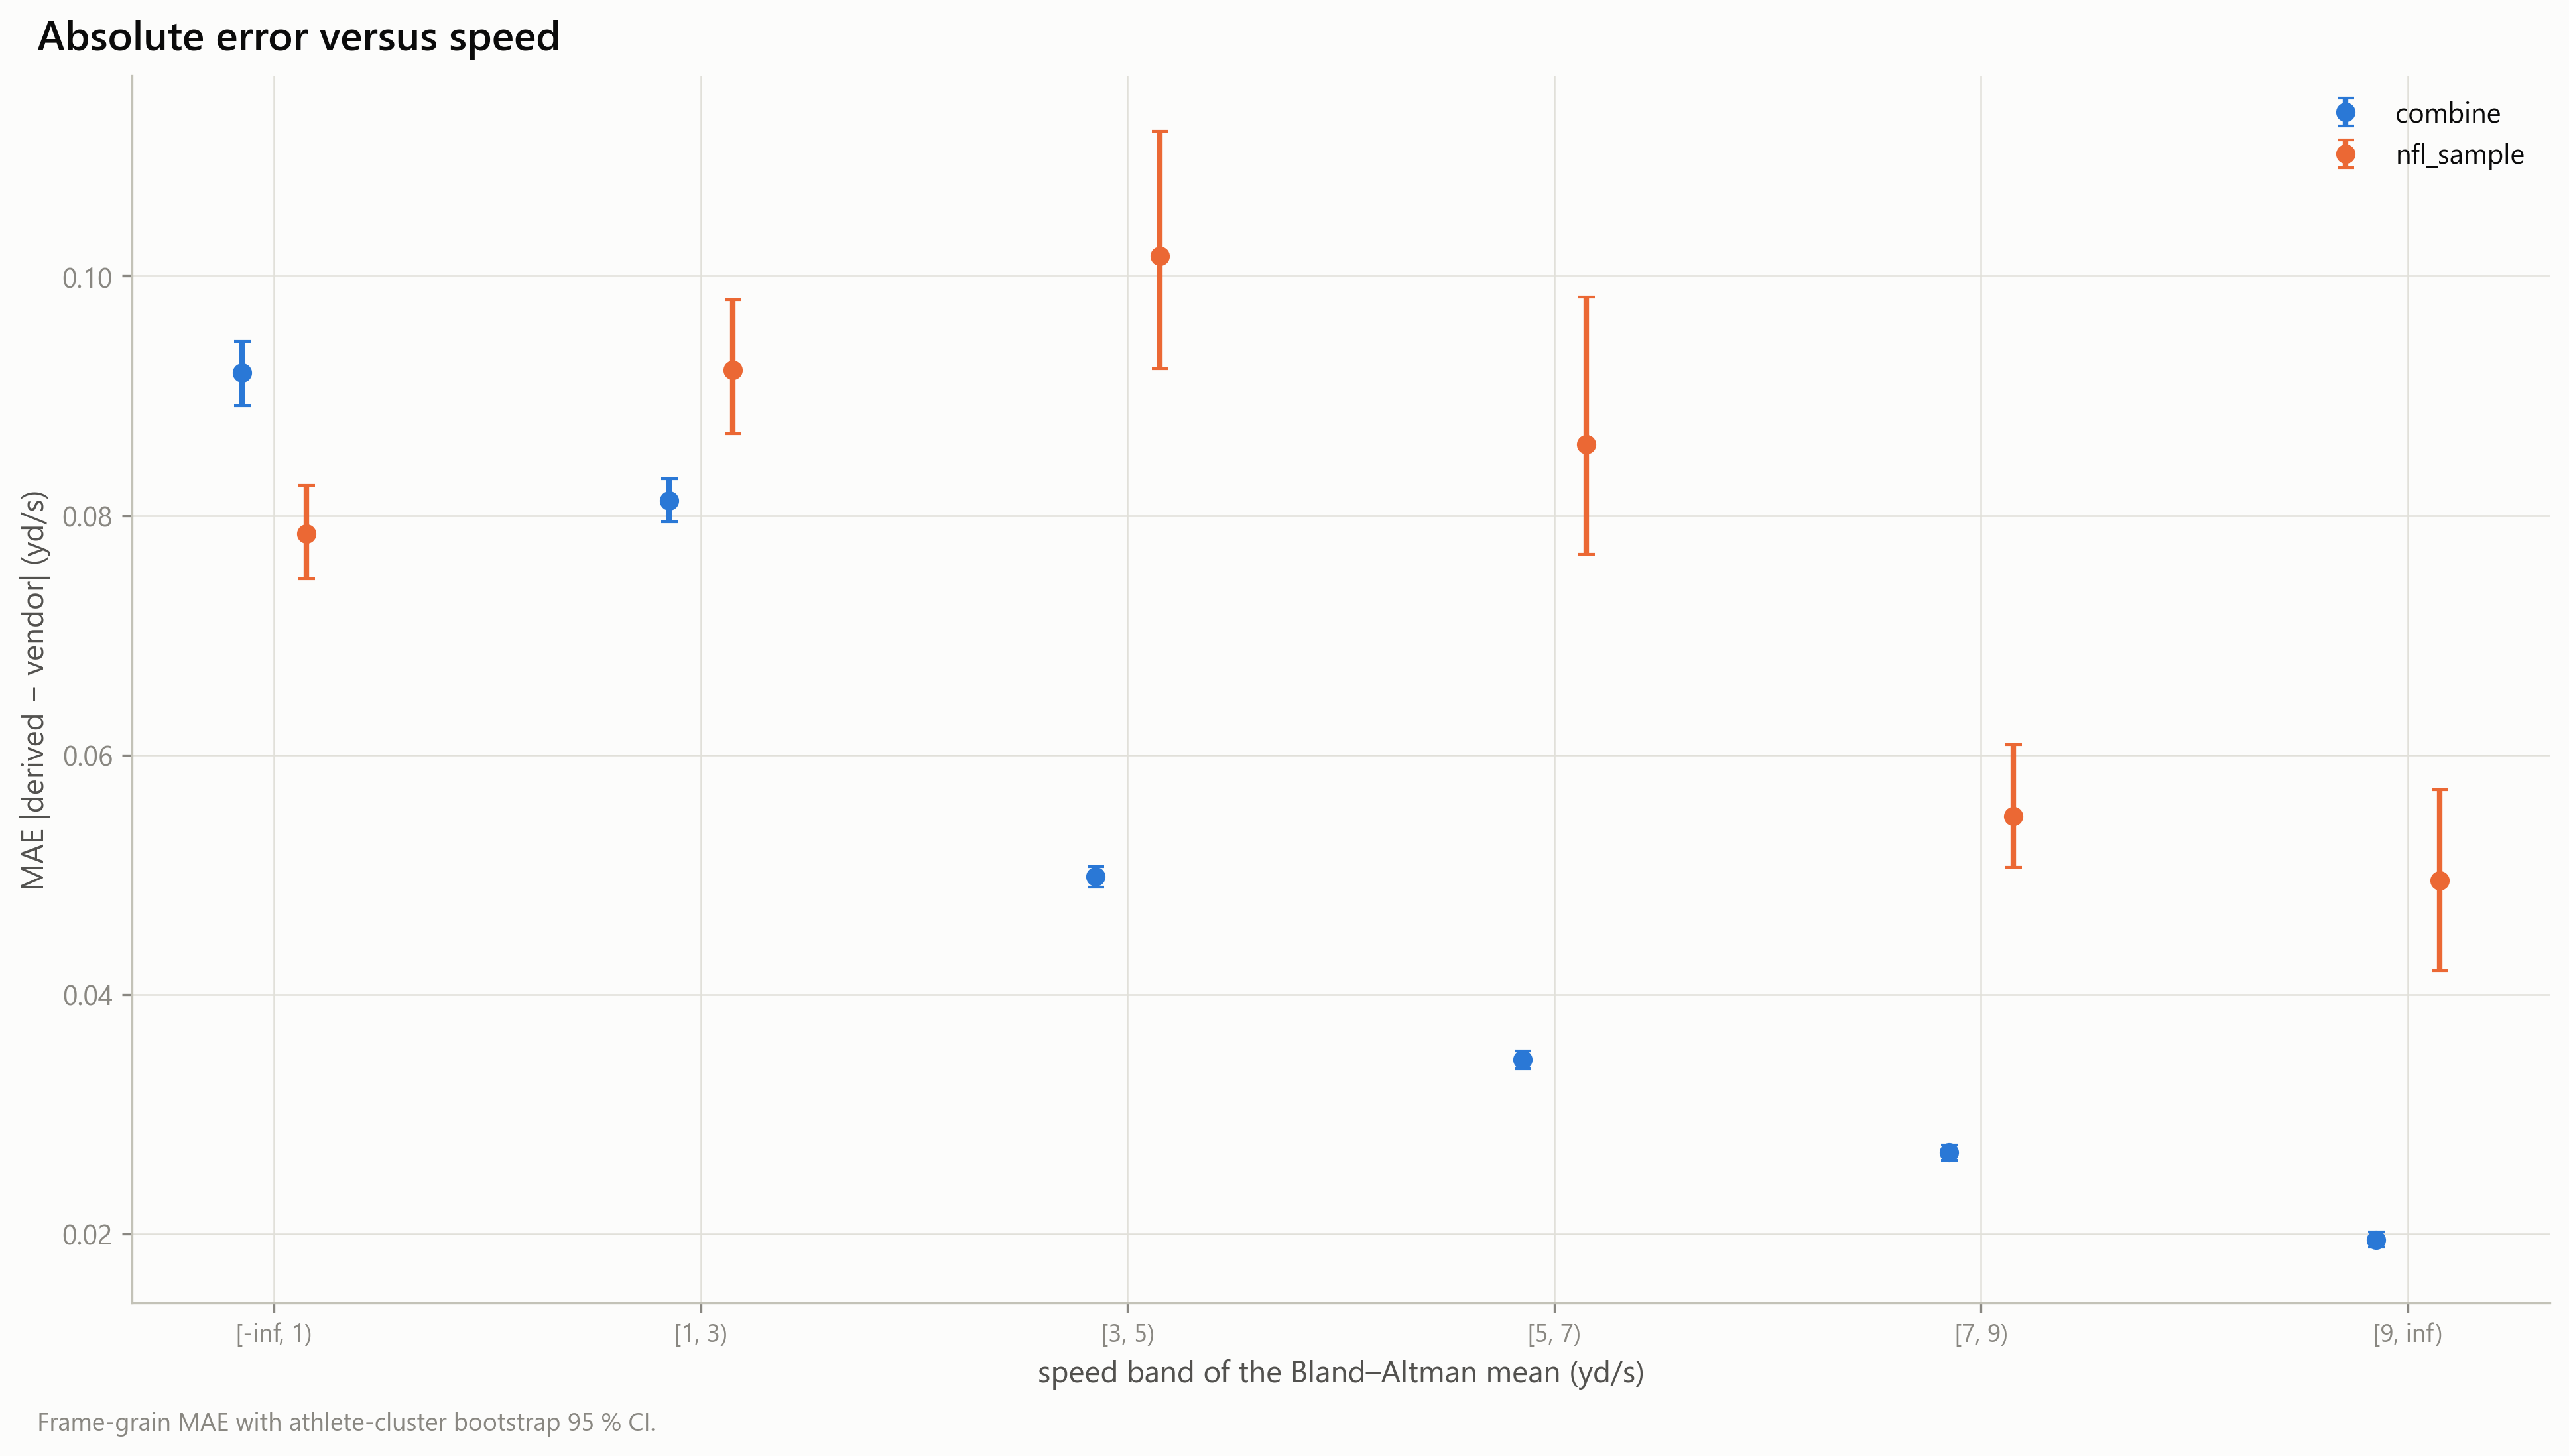

A2_04_residual_by_domain.png


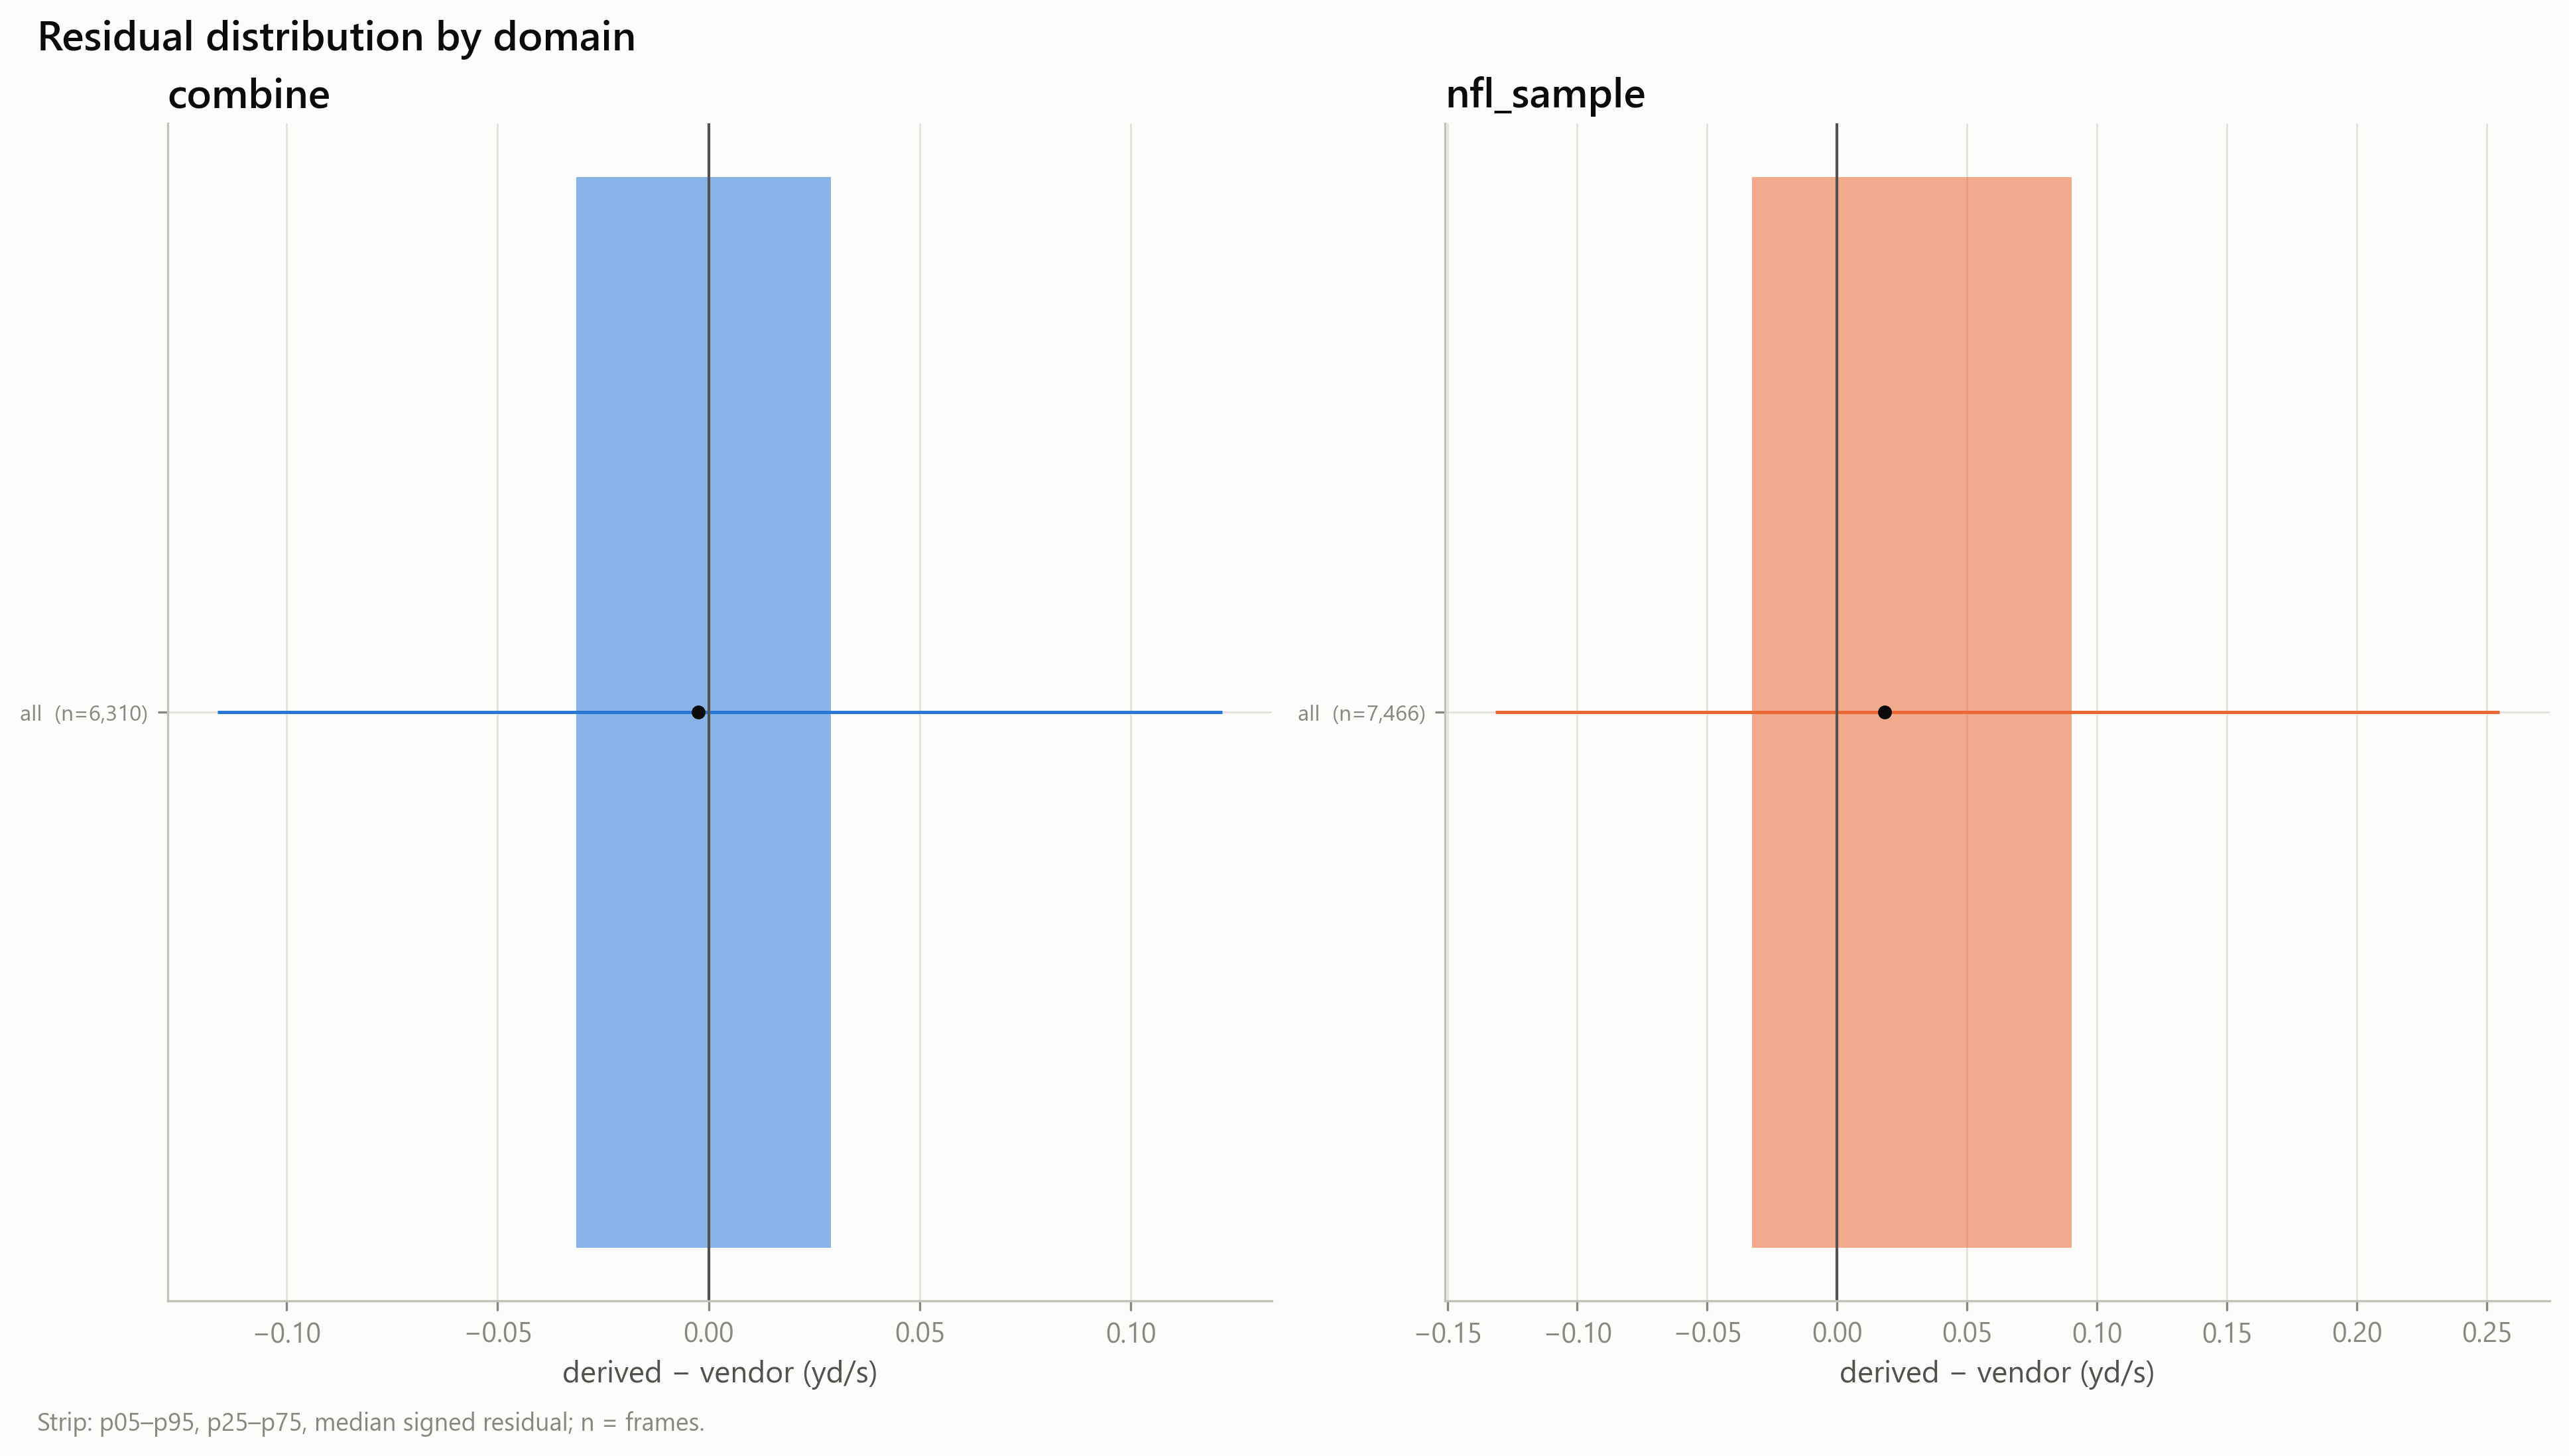

A2_05_residual_by_position.png


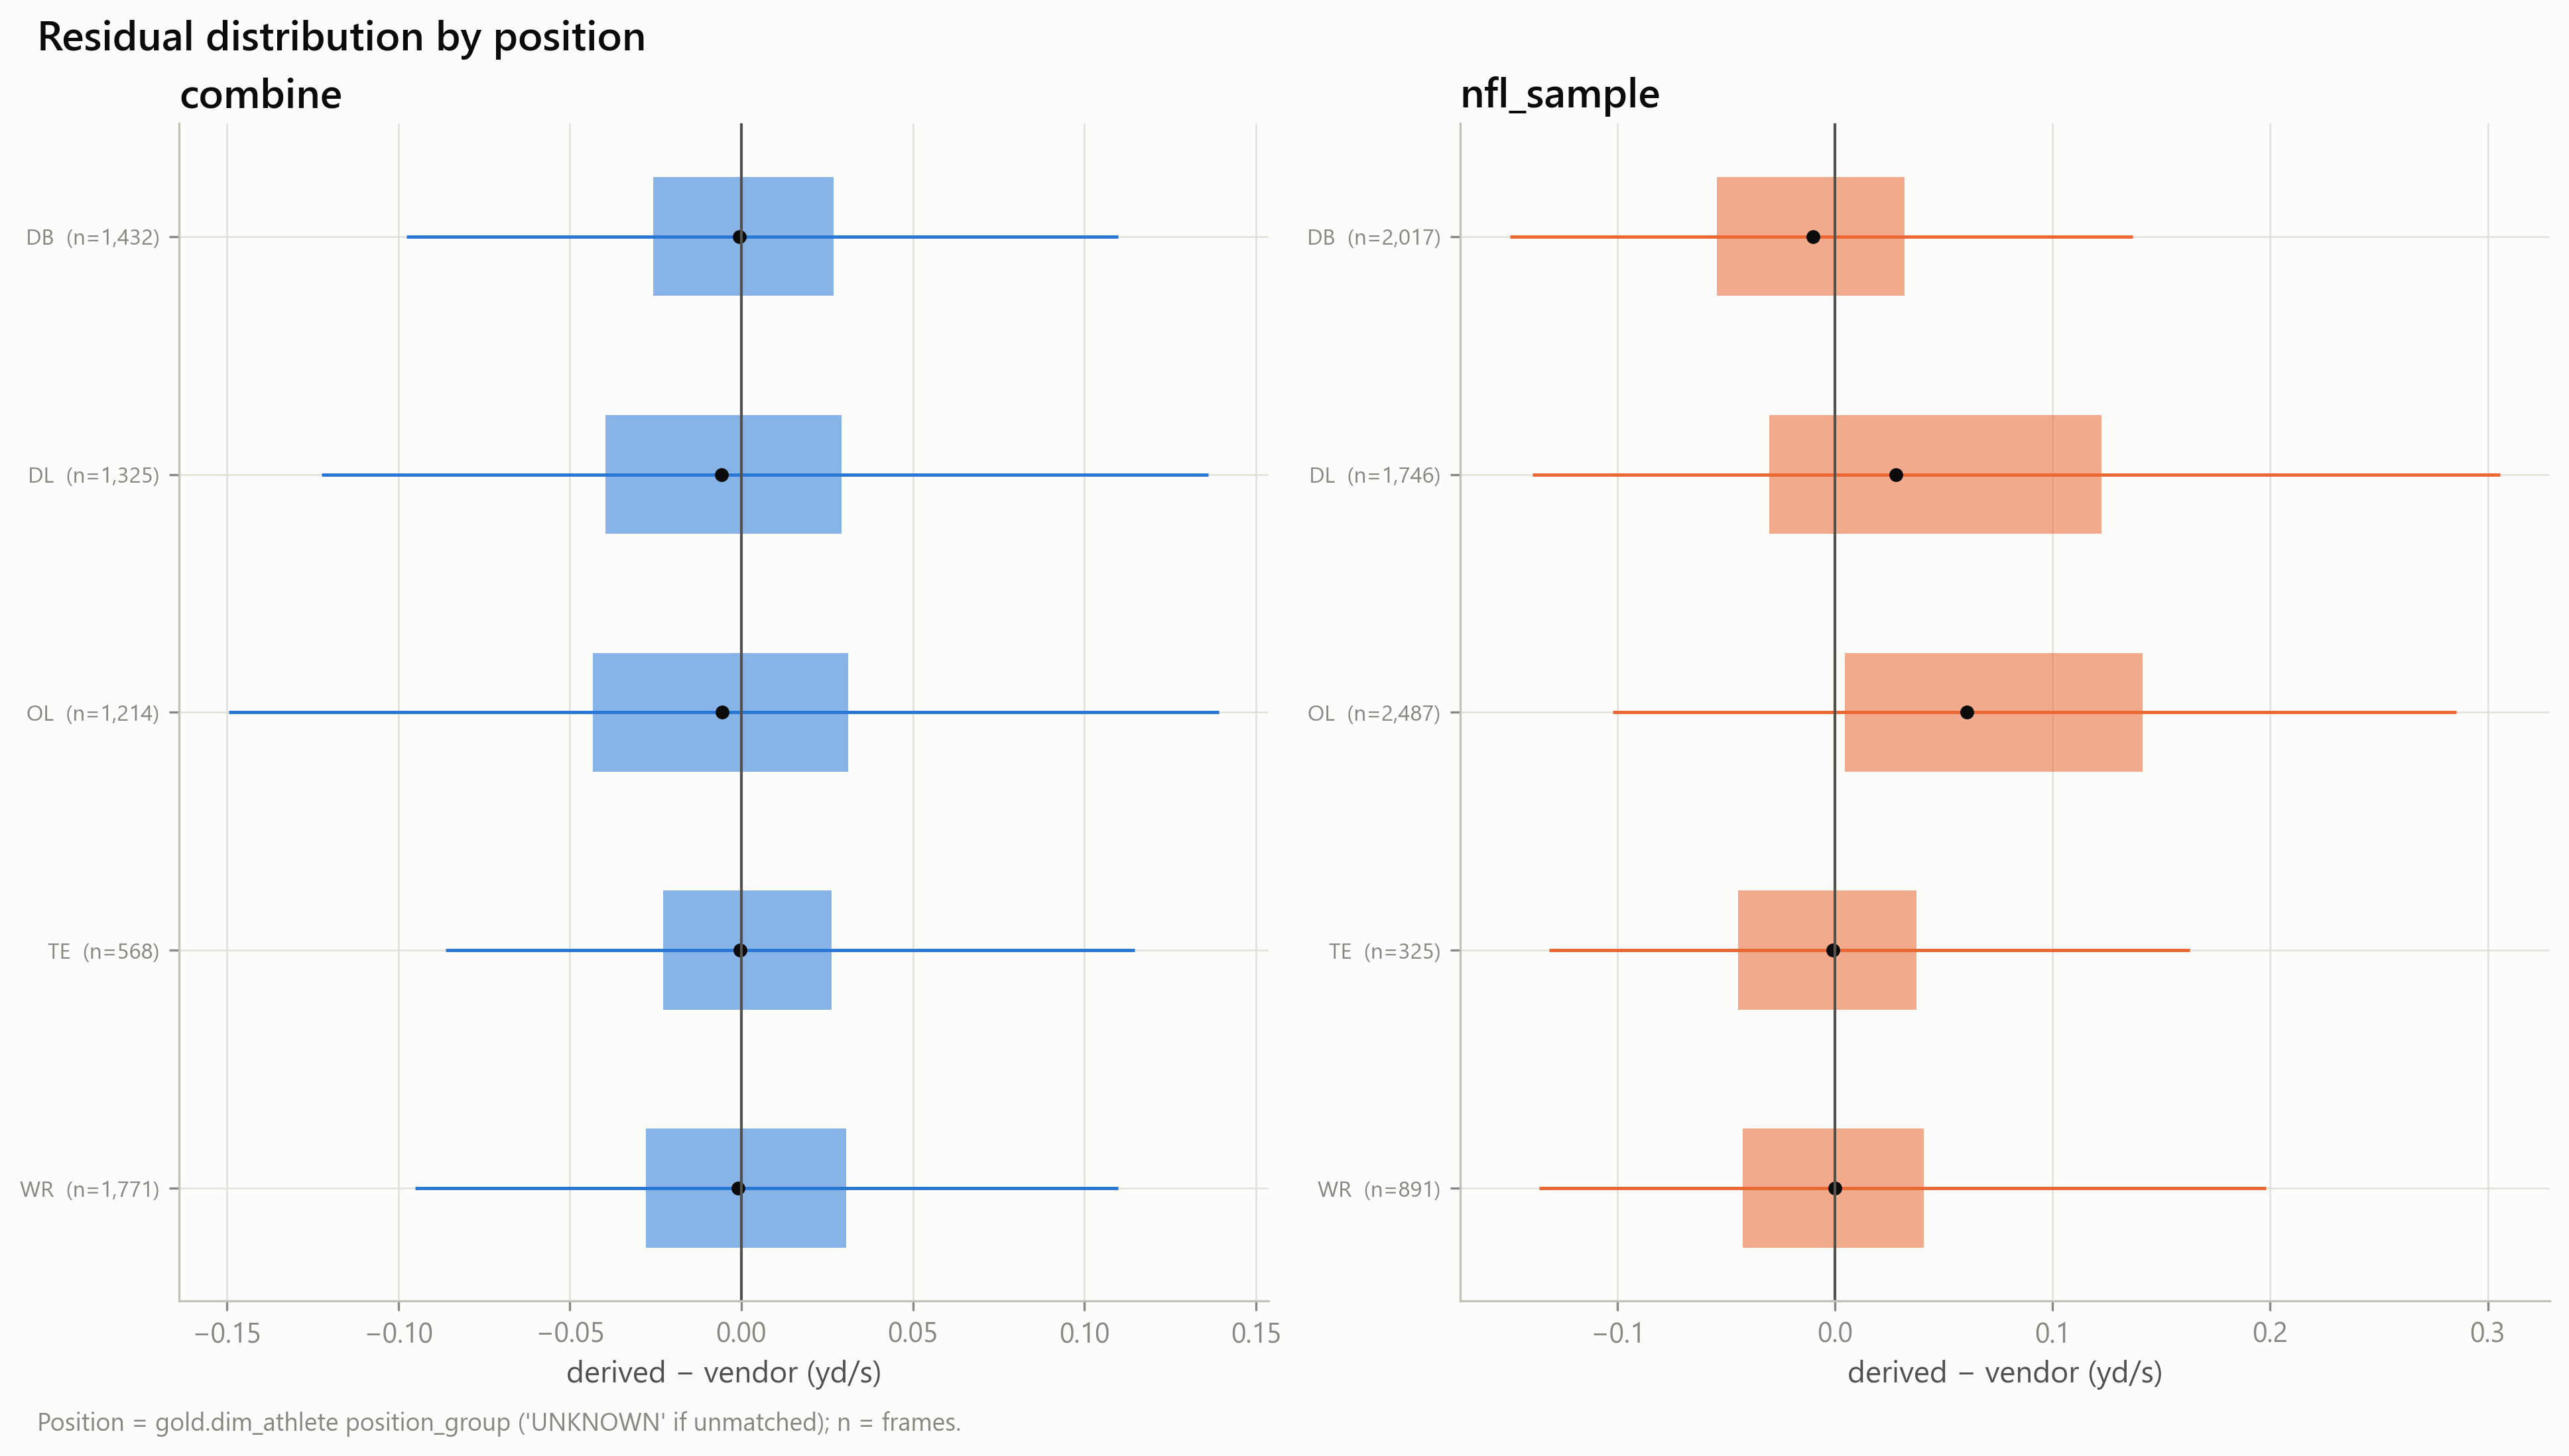

A2_06_residual_by_drill.png


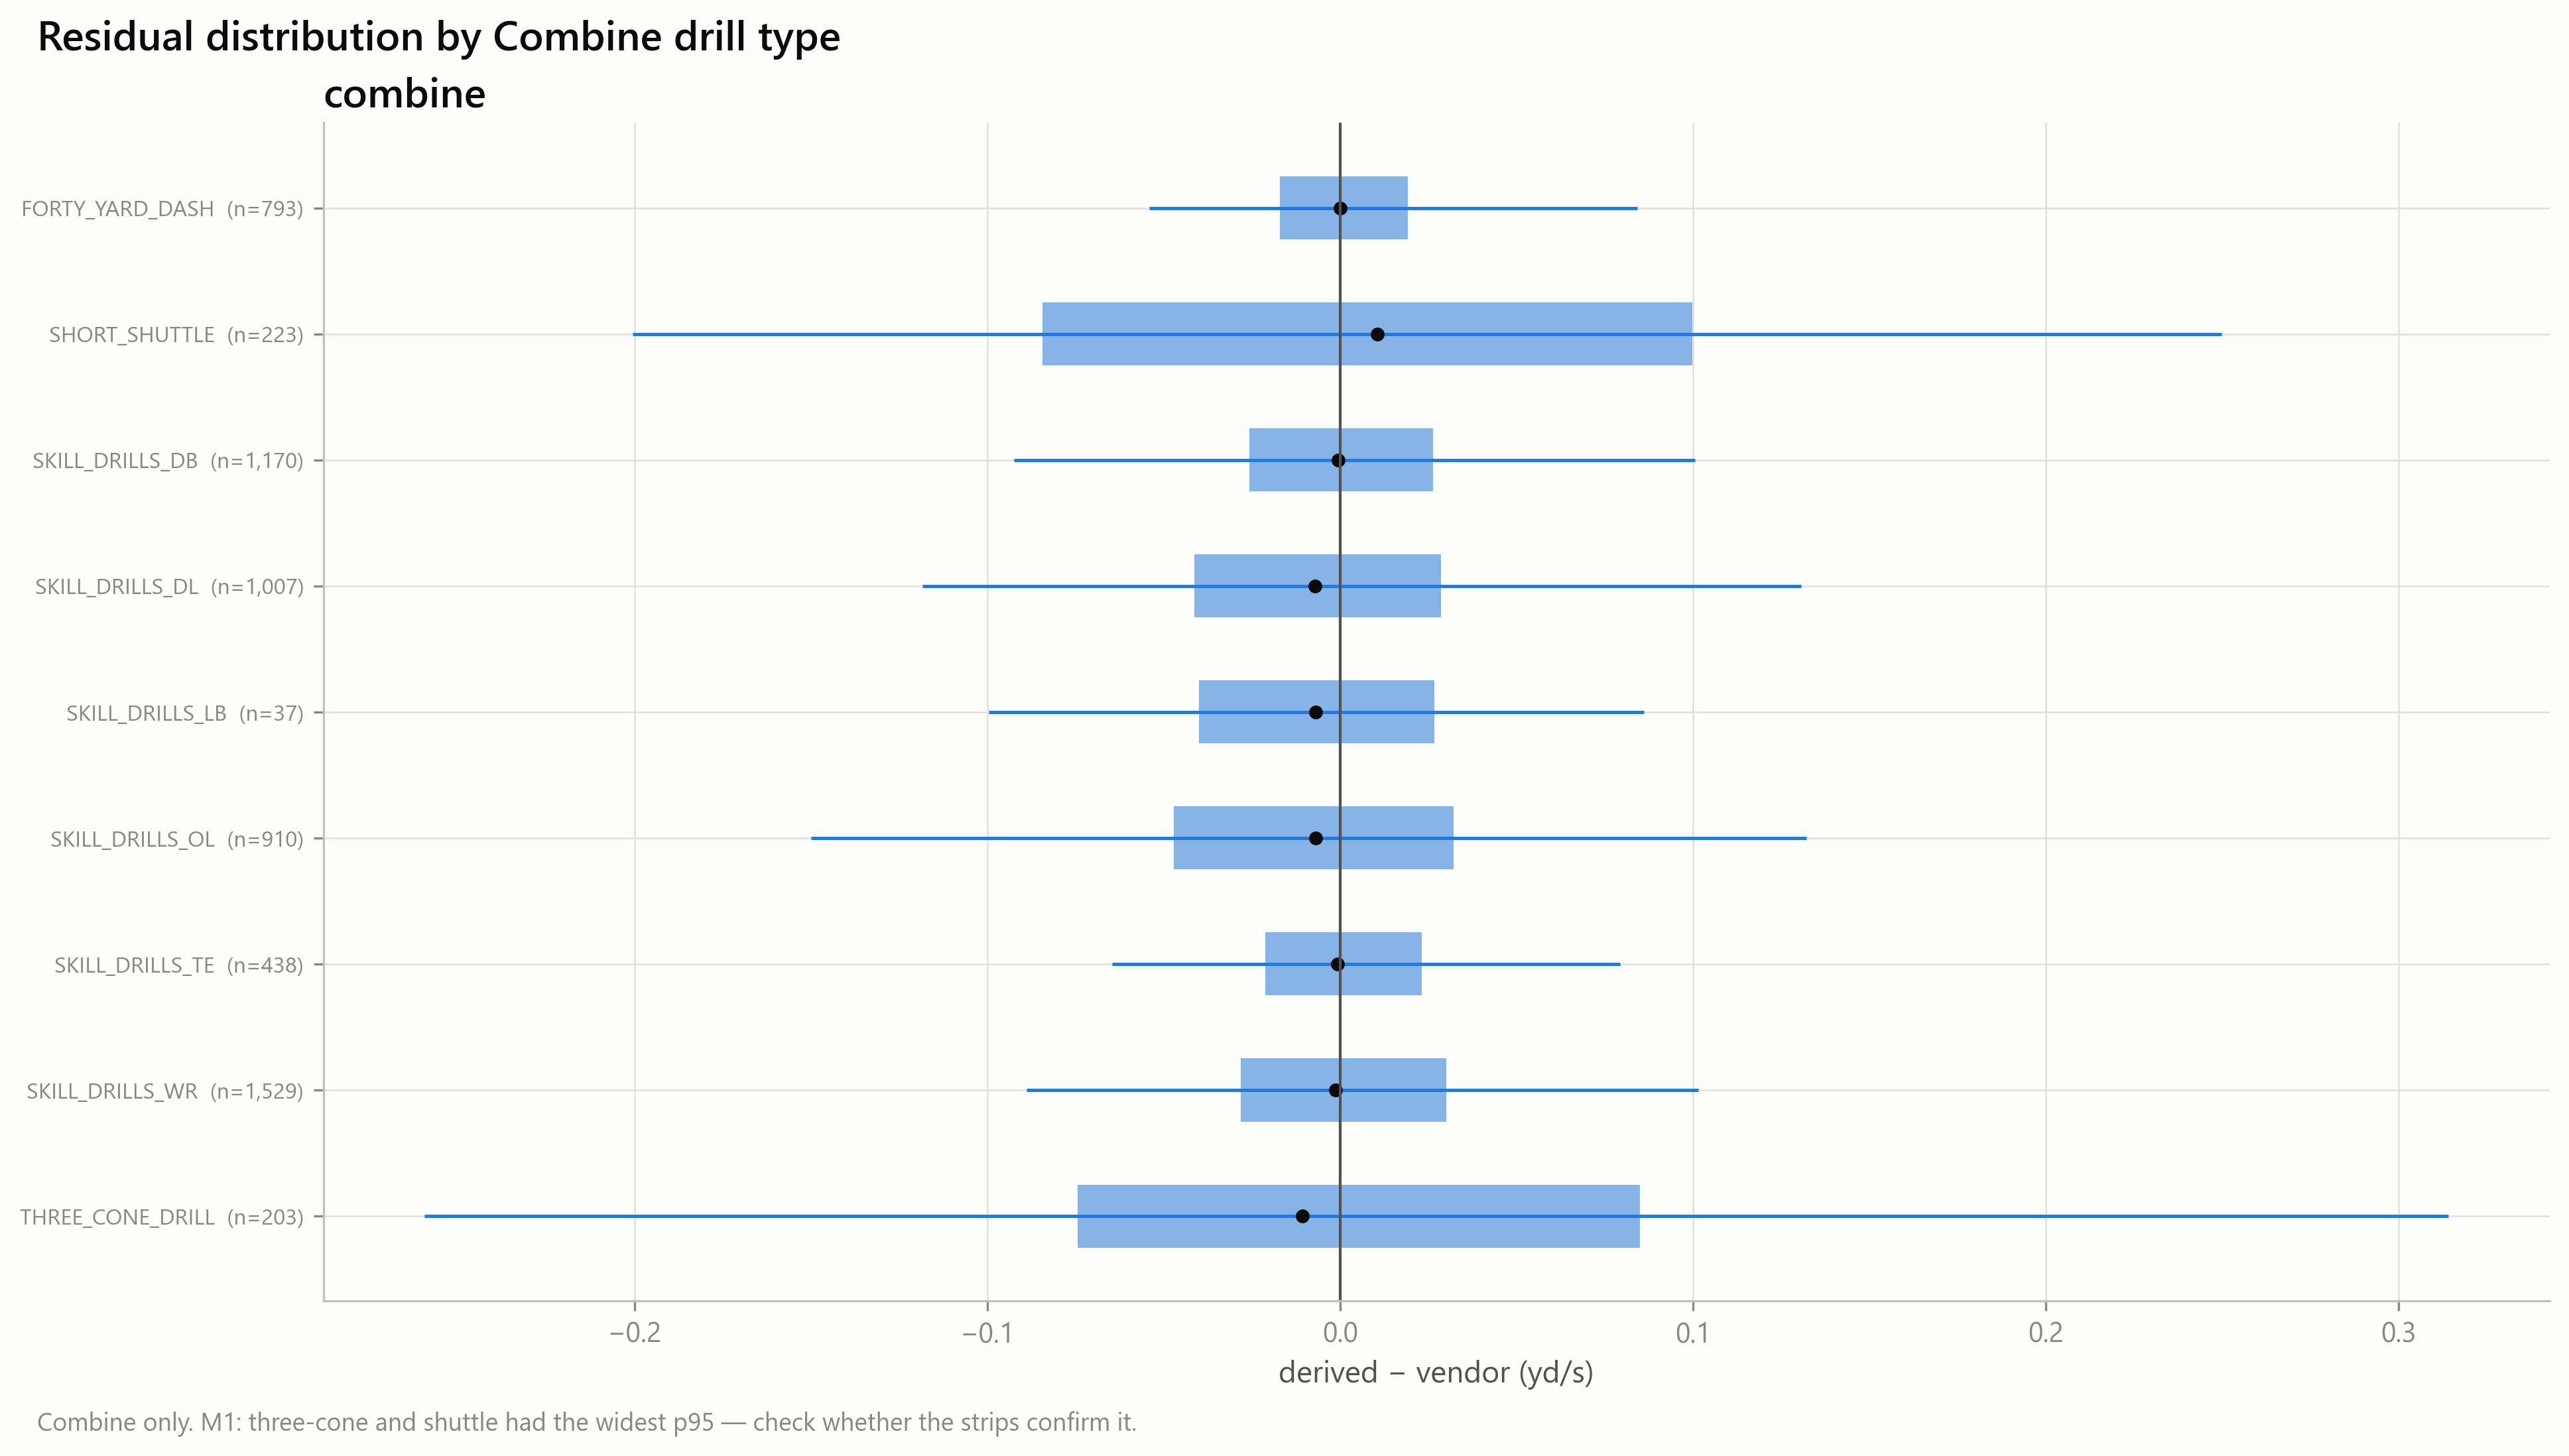

A2_07_error_vs_duration.png


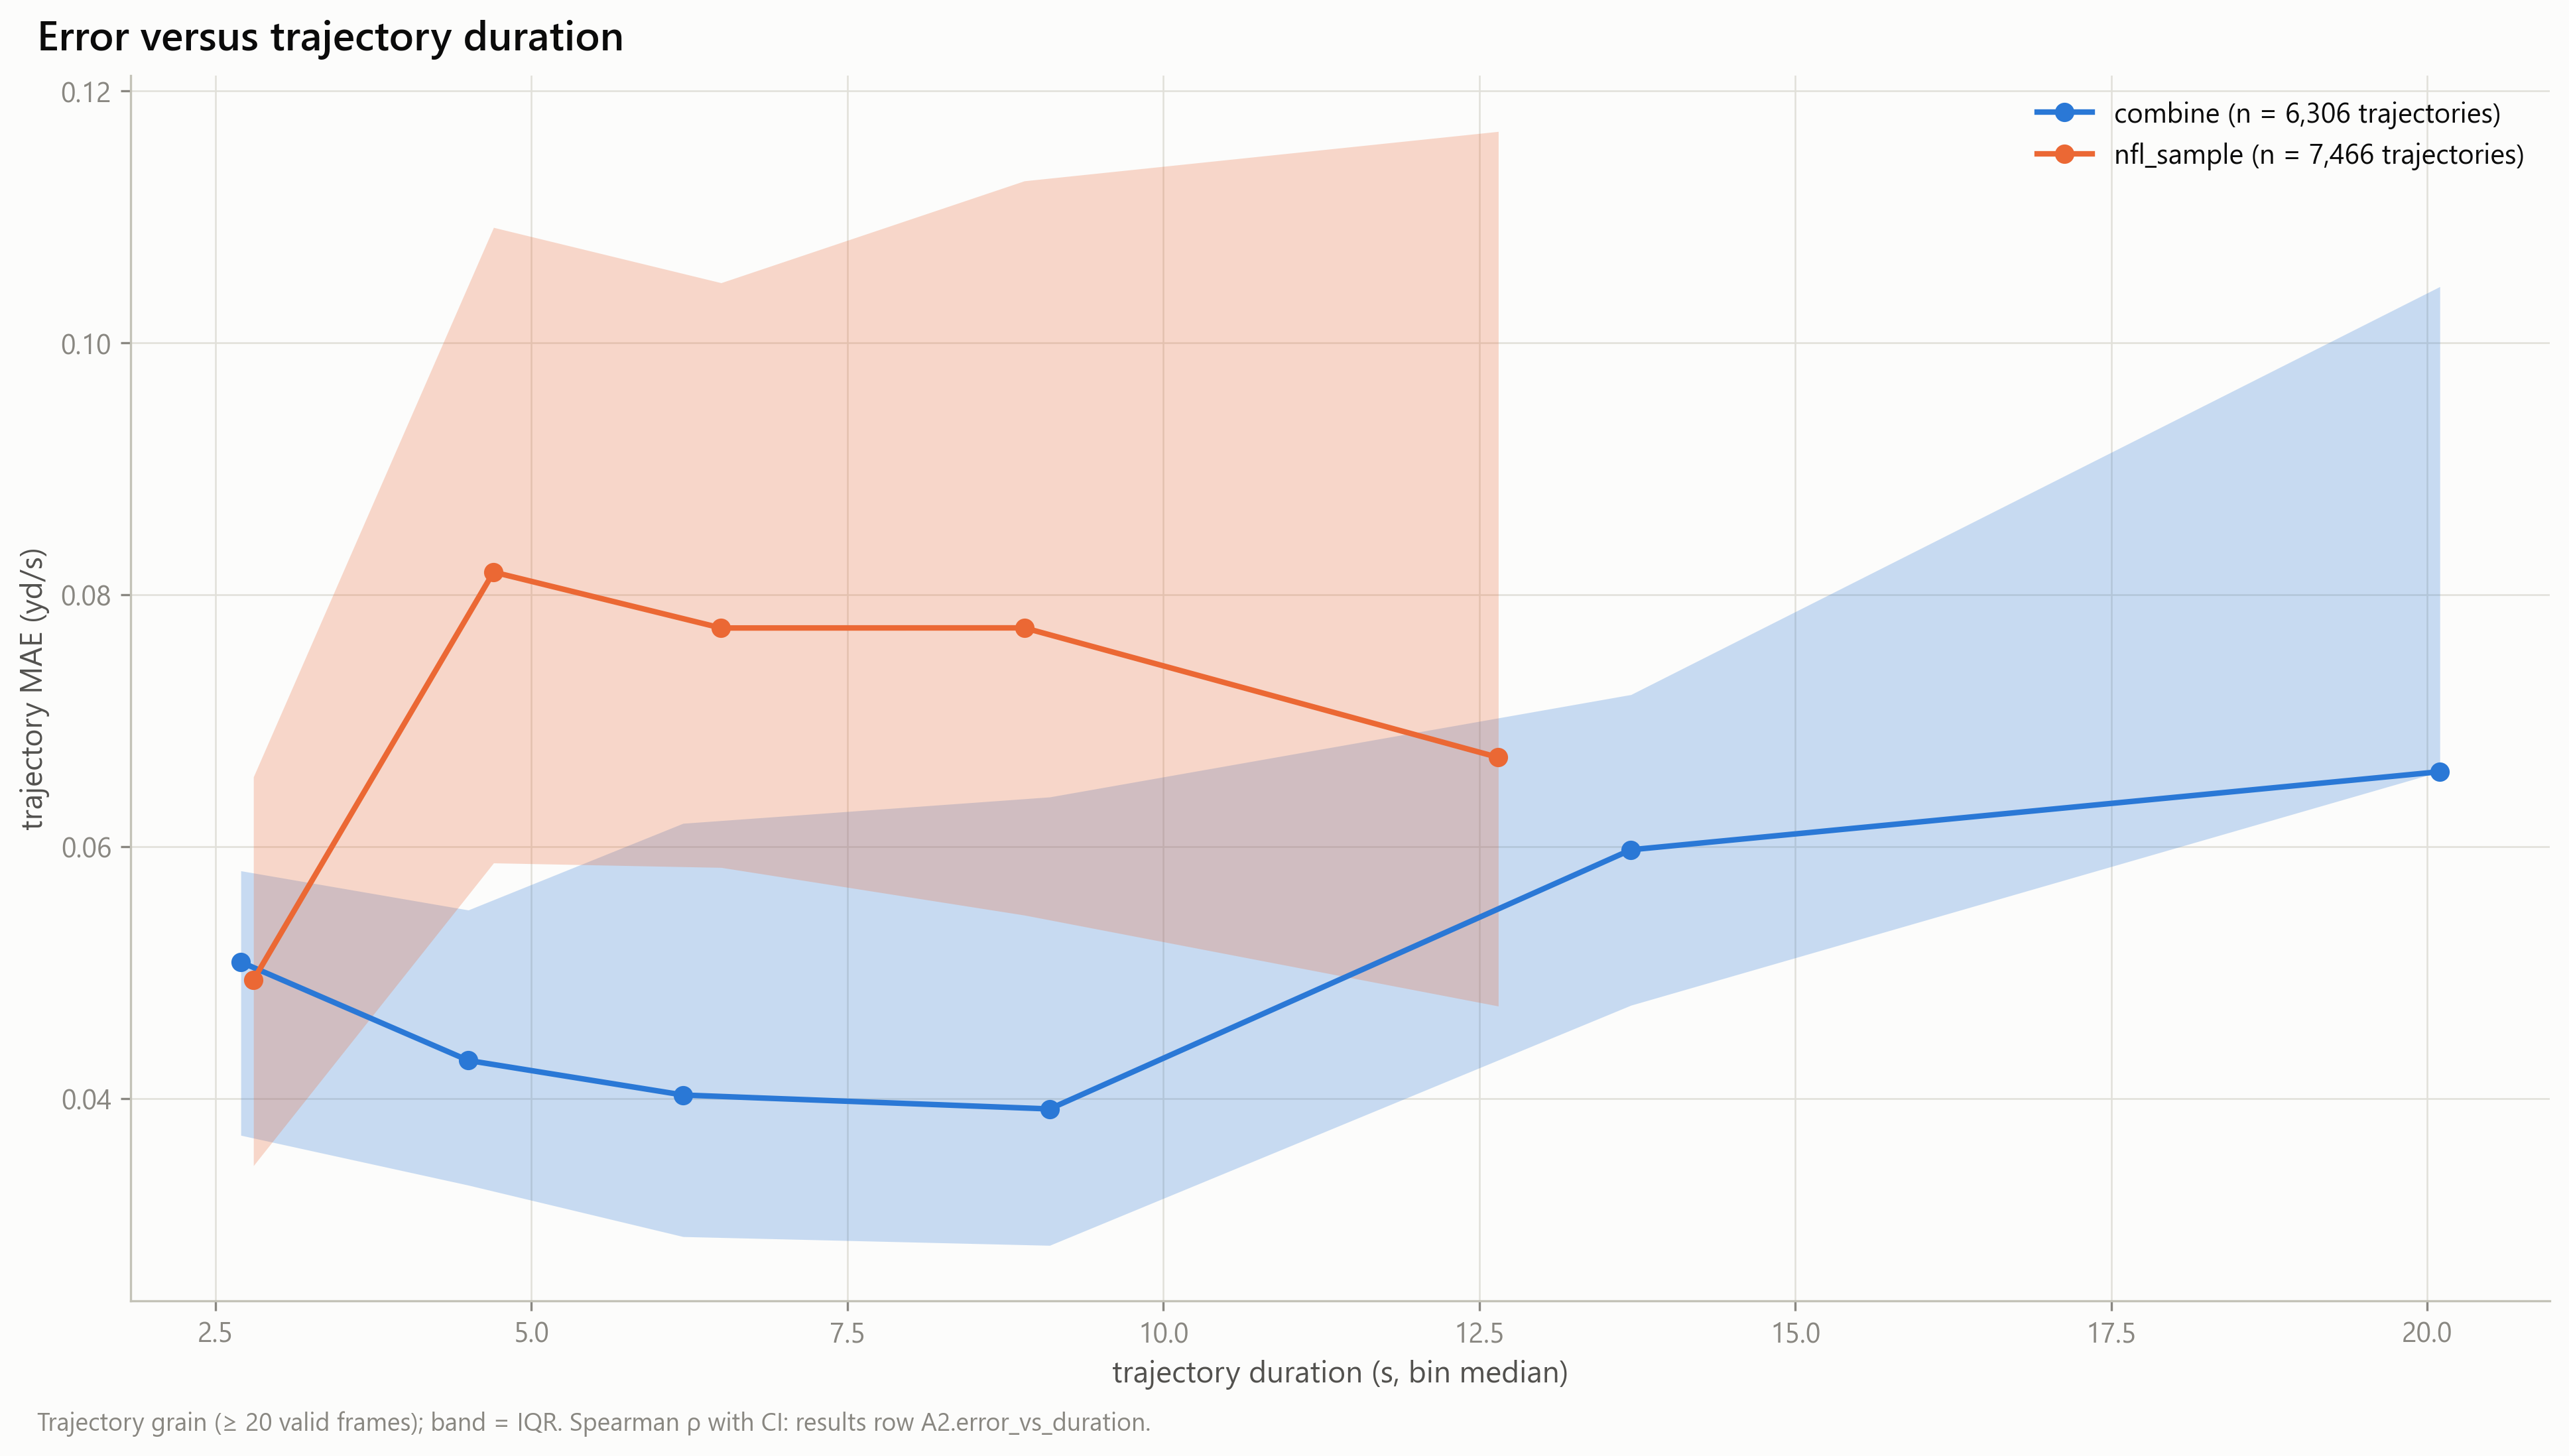

A2_08_bland_altman.png


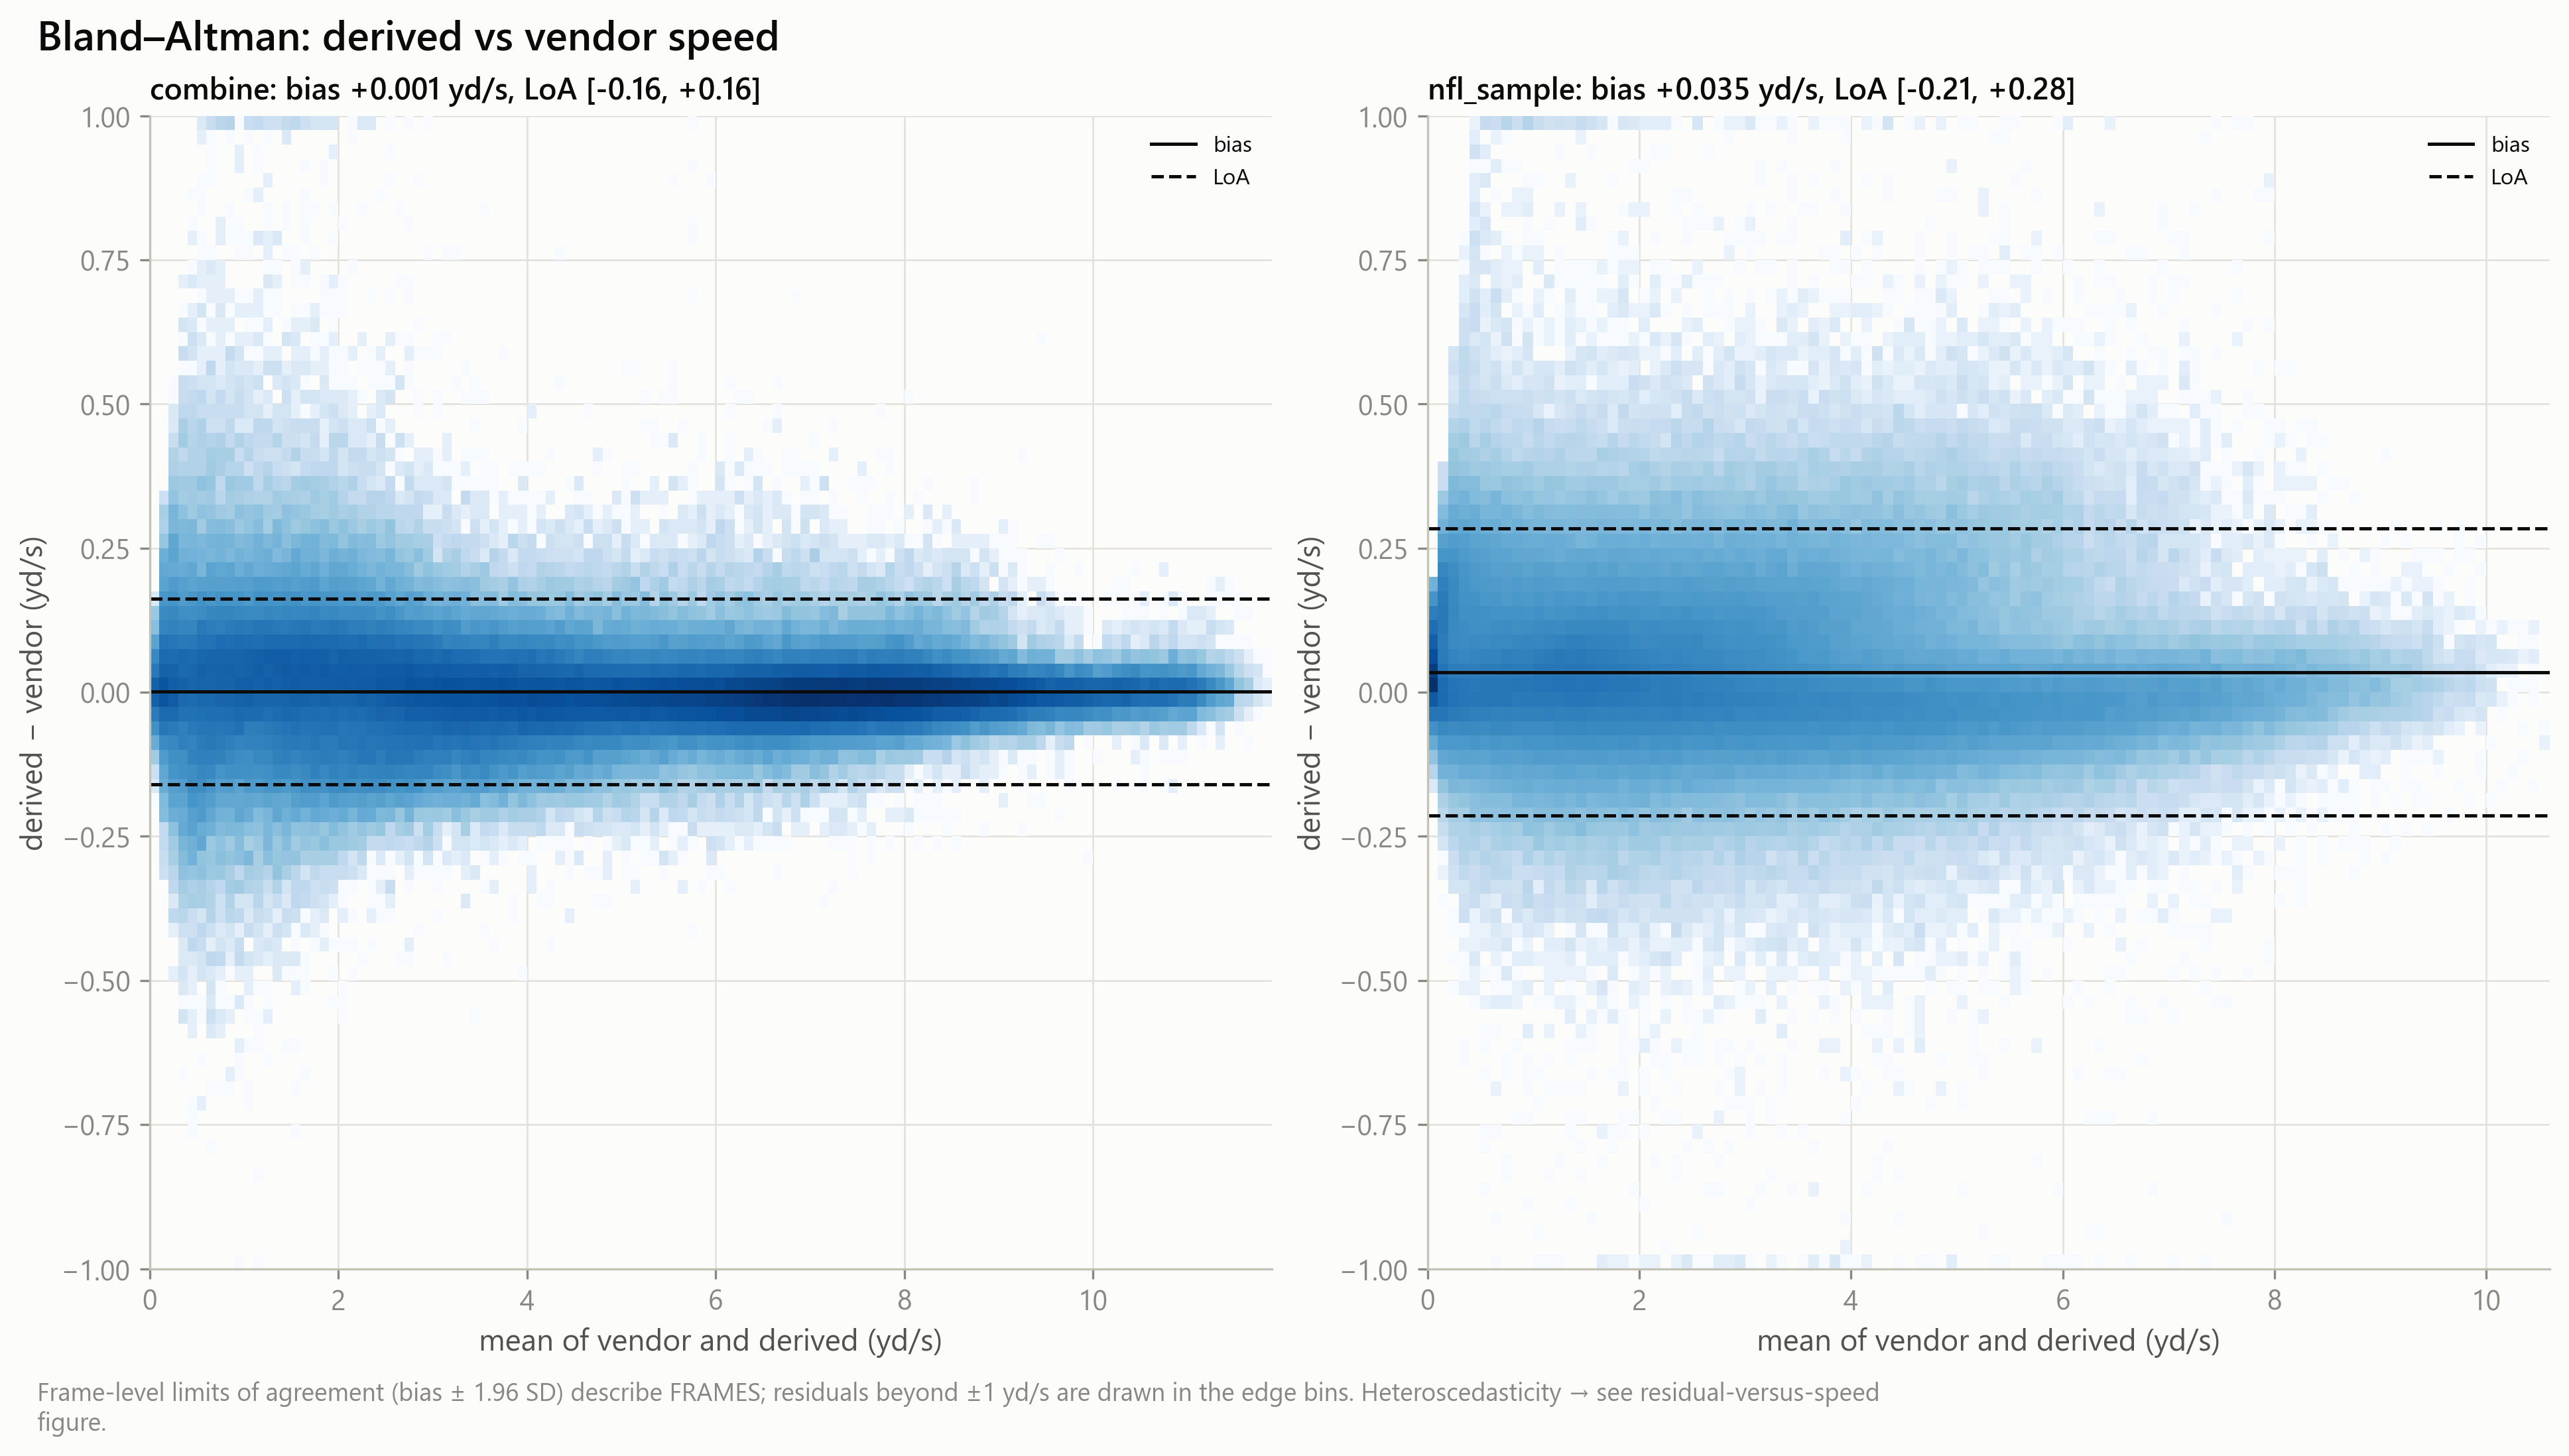

A2_09_high_disagreement_trajectories.png


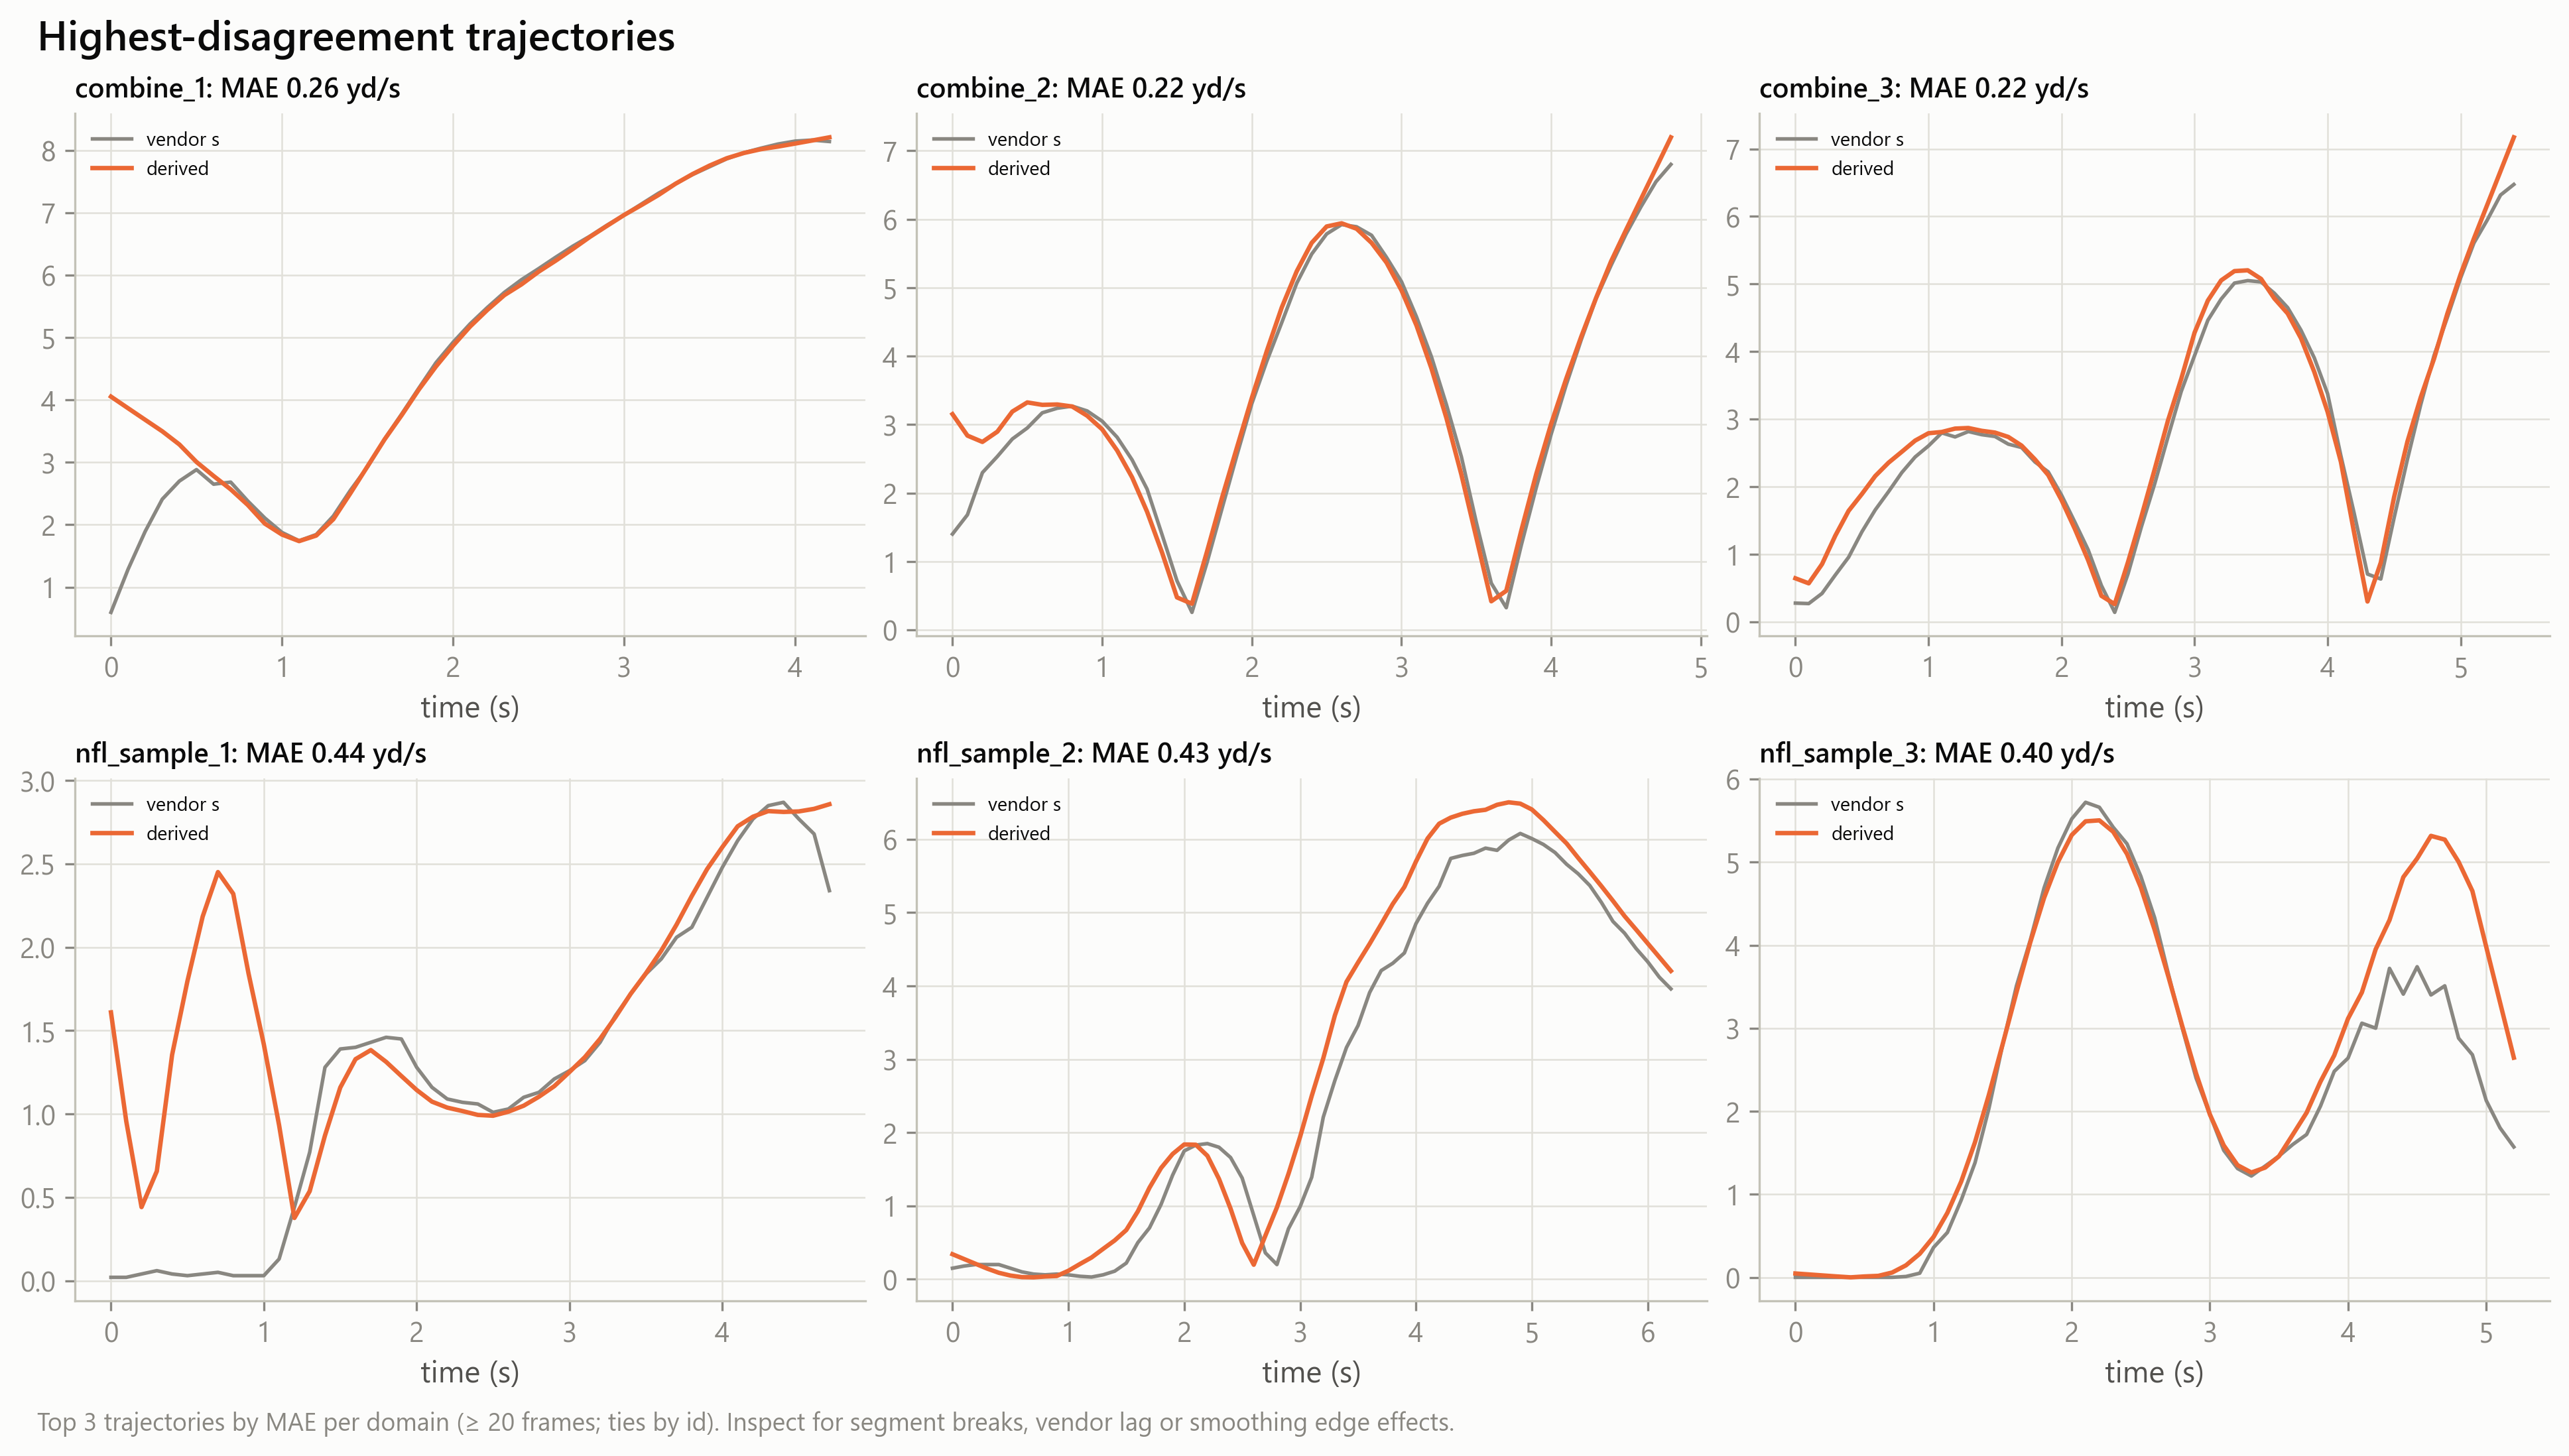

A2_10_error_summary_forest.png


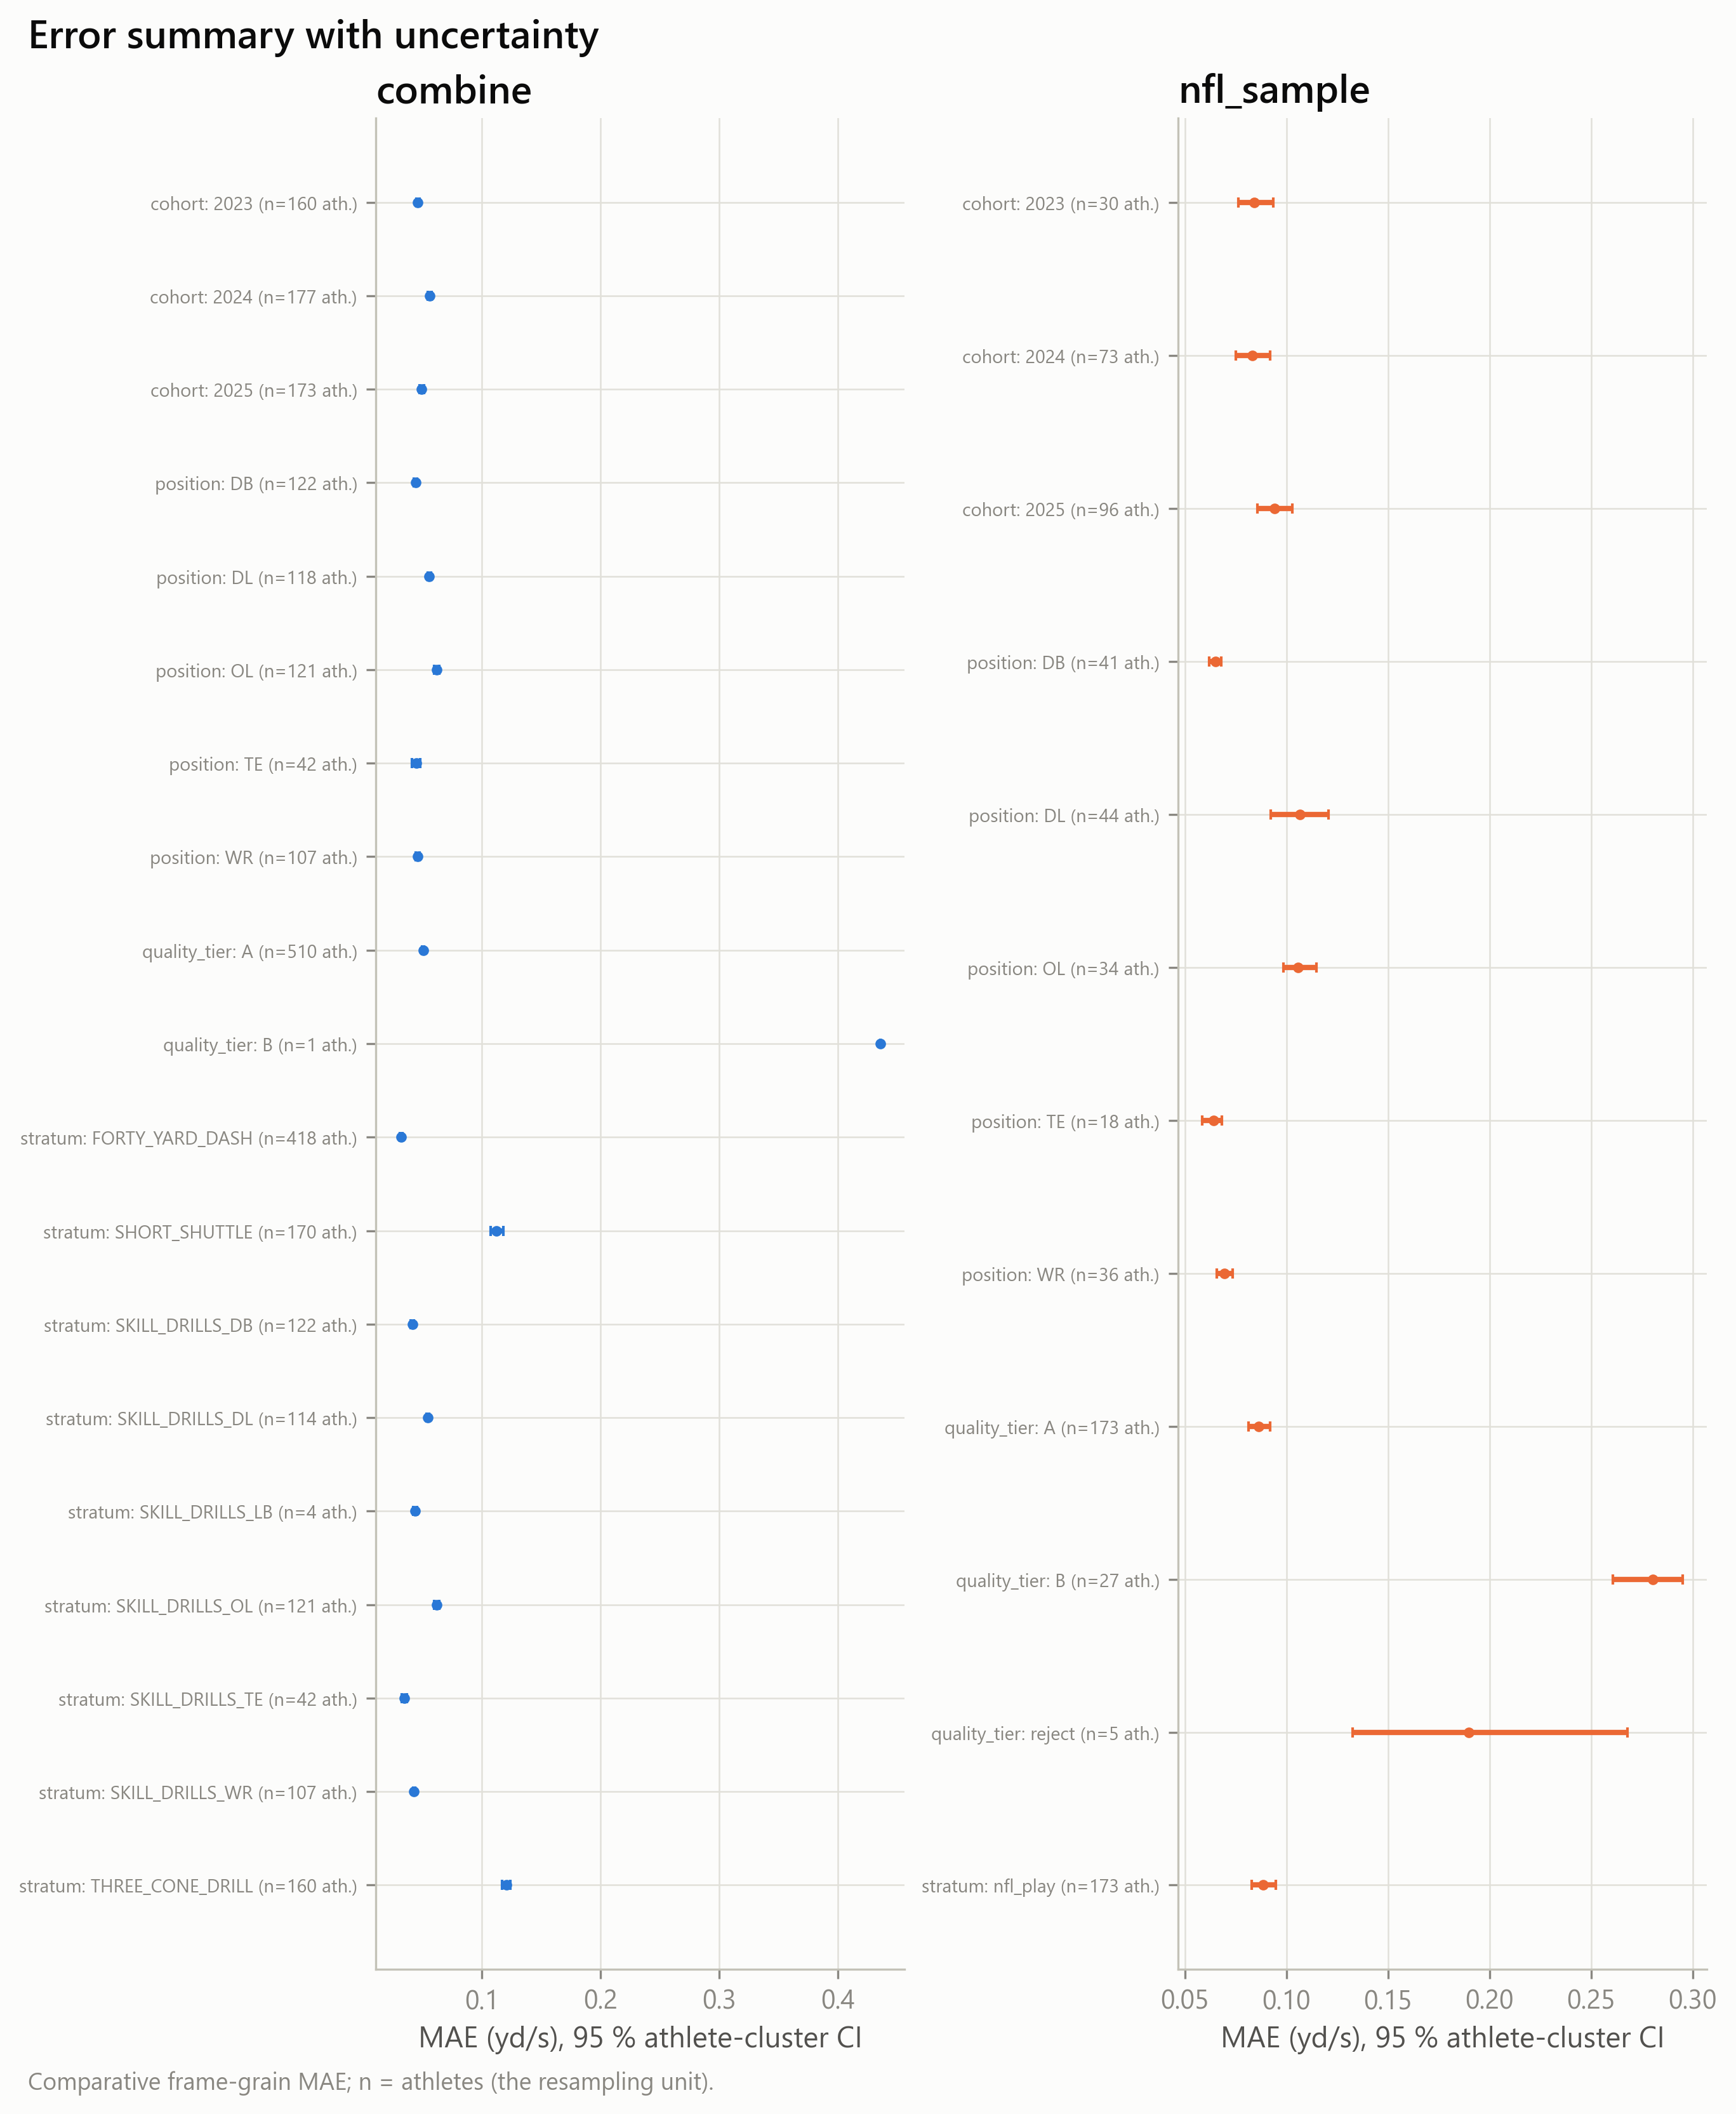

In [12]:
idx = store.figure_index()
if idx.height:
    display(idx.filter(pl.col('study') == 'A').select('figure_id', 'name', 'research_question', 'statistic', 'grain', 'interpretation_status'))
    for p in sorted(store.figure_dir('A').glob('*.png')):
        print(p.name); display(Image(filename=str(p), width=950))

## J. Sensitivity
- Screening quantile: re-run with `QualityStudyConfig(screen_quantile=0.995)` (continuous `pct_*` columns allow any cut-off without recomputation).
- Wilson vs athlete-cluster intervals in `A1_proportions` — a large gap means repeated trajectories per athlete matter.
- Smoothing sensitivity dimension joins after Study B.

## C2 — Reference annotation workflow (user labelling)
```
python -m nflbdb.research.studies --annotation-tasks          # tasks + blind packets → reports/annotation/
# copy annotation_labels_TEMPLATE.csv → annotation_labels.csv; label events in the t_s time base
python -m nflbdb.research.studies --evaluate-annotations reports/annotation/annotation_labels.csv
```
Classes: acceleration, braking, turn, reversal, reacceleration, none (one 'none' row = trajectory without events). Mark doubtful events `uncertain`; evaluation is reported with and without them.

## K. Football interpretation — _[fill ONLY from executed outputs]_
- Are derived speed features trustworthy enough for athlete-level comparisons (MAE / LoA vs typical between-athlete differences)? _…_
- Which drills / positions need caution? _…_

## L. Limitations
- Tiers are provisional rules; tier B is partly *defined* by vendor disagreement (circular separation in A1-04).
- Heading validity is content-confounded (standing still ⇒ undefined heading).
- Vendor speed is itself an estimate, not ground truth; agreement ≠ accuracy.
- NFL frame statistics come from a deterministic game sample; NFL examples are restricted to that sample.
- Frame-level LoA describe frames; athlete-level conclusions use the cluster-bootstrap intervals.

## M. Artifacts
`reports/tables/phase_03/{descriptive,statistical}/A*`, `warehouse/gold/phase_03/quality/*`, `reports/figures/phase_03/A_quality/*`, `figure_index.csv`, `table_index.csv`.

## N. Research decision — _[keep / revise / reject tiers; decide filter scenario for Studies D–H — after execution]_

## Study B (smoothing) and C1 (threshold sensitivity) — modules pending (next milestone step)